<div style="border-top:7px solid #15324b;border-bottom:3px solid #b96b3f;padding:34px 14px;text-align:center">
  <h1 style="margin-bottom:8px">DAC 2026 Preliminary Round</h1>
  <h2 style="margin-top:0;color:#15324b">Integrated Claim Risk and Audit Allocation System — V2</h2>
  <p><b>Second-generation, evidence-selected solution for Kaggle T4 ×2</b></p>
</div>

This notebook is the complete executable analysis and report record. It discovers the supplied data, audits V1 under a corrected evaluation framework, evaluates a compact evidence-driven model ladder, selects a deployable candidate automatically, and writes `/kaggle/working/submission_primary.csv`. It writes `/kaggle/working/submission_secondary.csv` only when a predeclared diversity rule supports a genuine private-leaderboard hedge.

Participant/team identity is intentionally not invented in this code artifact; those administrative fields belong in the official answer-sheet cover when the submission owner prepares the final document.

**Decision boundary.** A score prioritizes a claim for human investigation. It is never an autonomous rejection, payment denial, or allegation of wrongdoing.

**Competition-integrity statement.** Prediction uses only the organizer-supplied claim fields. External material is used solely for methodology, interpretation, and governance. No hidden labels, external row matching, leaderboard probing, or manual test-row adjustment is used.


## Table of Contents

1. [CHAPTER I: Introduction](#chapter-i-introduction)
2. [CHAPTER II: Theoretical Framework](#chapter-ii-theoretical-framework)
3. [CHAPTER III: Analytical Steps](#chapter-iii-analytical-steps)
4. [CHAPTER IV: Analysis of Results](#chapter-iv-analysis-of-results)
5. [CHAPTER V: Conclusion and Recommendation](#chapter-v-conclusion-and-recommendation)
6. [REFERENCES](#references)
7. [ATTACHMENT](#attachment)

Tables and figures use chapter-based numbering for transfer to the official answer sheet. Empirical conclusions are rendered from executed values; empty outputs in the distributed file are intentional.


# CHAPTER I: Introduction

## 1.1 Background and Decision Context

Healthcare claims administration must pay legitimate claims promptly while detecting error, abuse, and deliberate fraud. Machine learning can narrow a large claims universe into an investigable portfolio, but reviews of healthcare-fraud analytics emphasize inconsistent data, uncertain labels, privacy, and limited comparability as persistent constraints [4], [5]. The World Health Organization's PhilHealth case likewise frames analytics as a complement to established review—not an automated verdict [2].

DAC 2026 makes the resource constraint explicit. For $N$ evaluation claims, only $K=\lfloor0.05N\rfloor$ enter the official audit portfolio. Missing fraud wastes pooled resources; unnecessary audits impose delay, workload, and avoidable scrutiny on legitimate policyholders. A defensible system must therefore optimize four linked properties: capture at the audit boundary, global ranking, probability reliability, and protection against disproportionate false-positive exposure.

The V1 submission earned a user-reported public leaderboard score of **0.95833**, while the reported leader was **0.98000** at the prompt date. This is a coarse external signal only. It does not identify mistaken claims, validate a particular model family, or authorize row-level probing. V2 instead reconstructs V1 from code and artifacts, corrects evaluation defects, and tests changes using common out-of-fold evidence.

Calibration matters because investigators may use score magnitude to set review intensity, escalation, and staffing. Discrimination and calibration are different: a model may rank claims well while systematically overstating or understating risk [8], [9]. Protection also cannot be reduced to a scalar. The official false-positive-rate gaps are reported with denominators and uncertainty; disparity is not equated with discrimination.

Interpretability supports investigation and governance, but a feature attribution is neither proof nor causality [22]–[24]. Each alert should expose the score, supporting claim fields, model drivers, data-quality warnings, and a route for override, escalation, and appeal. WHO and NIST guidance motivates documented human responsibility, monitoring, and contestability [25], [26].

## 1.2 Formal Problem

For labeled claims $\mathcal D=\{(x_i,y_i,a_i)\}_{i=1}^{n}$, $x_i$ contains permitted claim fields, $y_i\in\{0,1\}$ is the fraud label, and $a_i$ contains protected attributes used for evaluation. A model estimates

$$\hat p_i=f_\theta(x_i)\approx\Pr(Y_i=1\mid X_i=x_i).$$

At capacity $c$, the audit set $S_c$ contains the $\lfloor cn\rfloor$ largest scores. Exact score ties are resolved with a deterministic **label-neutral claim key**, while optimistic, pessimistic, and expected boundary capture are reported because organizer tie-breaking is unspecified. Claim identifiers are never predictive features.

The official objective is

$$TechnicalScore=0.55\,NR@5\%+0.20\,AP+0.15(1-Brier)+0.10\,ProtectionScore.$$

This is prediction and constrained allocation. Associations, importances, subgroup rates, and explanations are not interpreted causally.

## 1.3 Research Questions

**RQ1.** Which schema, missingness, duplicate-template, unusual-value, identifier, proxy, and source-order properties affect valid analysis?

**RQ2.** Which validation design gives the most reliable feasible model-selection evidence while separately testing transport to unseen claim templates and locations?

**RQ3.** Which V1 choices are verified strengths, verified defects, plausible limitations, rejected explanations, or unresolved uncertainties?

**RQ4.** Do semantic code preservation, fold-safe rarity, burden density, concentration, and clinically structured interactions improve near-boundary fraud ranking?

**RQ5.** Which compact model family or deployable fixed-form ensemble best balances NR@5%, AP, calibration, protection, stability, and complexity?

**RQ6.** Does raw, sigmoid, monotone beta, or diagnostic isotonic calibration improve cross-fitted Brier performance without unsafe ranking plateaus?

**RQ7.** How much fraud is captured at 3%, 5%, and 7% capacity, and what legitimate audit burden remains relative to random and transparent baselines?

**RQ8.** Which patterns characterize false positives, missed fraud, near-boundary fraud, and cross-model recoveries?

**RQ9.** Are eligible gender and official age groups exposed to different legitimate-claim audit rates, with what uncertainty and sensitivity?

**RQ10.** How should NHPA present, oversee, monitor, recalibrate, retrain, challenge, and retire the system?


# CHAPTER II: Theoretical Framework

## 2.1 Constrained Audit Allocation and Ranking

Let $P=\sum_i y_i$, $K=\lfloor0.05N\rfloor$, and $TP_K=\sum_{i\in S_{0.05}}y_i$. The official quantities are

$$Recall@5\%=\frac{TP_K}{P},\qquad Recall_{max}=\min\left(1,\frac{K}{P}\right),$$

$$NormalizedRecall@5\%=\frac{Recall@5\%}{Recall_{max}}.$$

Average Precision (AP) summarizes precision across positive ranks and is more informative than accuracy for selective action [6], [7]. Capacity-specific precision, legitimate audits, audit FPR, cumulative gain, and lift translate ranking quality into investigator workload.

Top-$k$ learning has dedicated surrogates [18], but this dataset is one global claim list without query groups. A pairwise/ranking objective would add calibration and deployment complexity without existing evidence that it beats well-calibrated boosted classifiers. V2 therefore treats direct ranking as a documented rejected direction and concentrates computation on strong probability models, boundary analysis, and fixed deployable blends.

## 2.2 Probability Reliability

The Brier score is

$$Brier=\frac1N\sum_{i=1}^{N}(\hat p_i-y_i)^2,\qquad CalibrationScore=1-Brier.$$

It is a proper score for probability forecasts [8], while reliability curves, calibration intercept, and slope separate useful diagnostics [9]. V2 compares raw scores, sigmoid scaling, monotone beta calibration [10], and isotonic regression. Every reported selection Brier is cross-fitted by outer fold: the calibrator predicting a row never sees that row's label. Ranking terms are calculated from the common raw score because fold-specific calibration maps can otherwise reorder globally held-out rows even when every individual map is monotone. A single deployment calibrator is subsequently fitted to all OOF predictions and applied to test predictions.

Sigmoid and beta maps are constrained to be strictly monotone, preserving ranking. Isotonic is retained only as a Brier/plateau diagnostic and is ineligible for selection because its label-fitted plateaus cannot provide clean ranking evidence. This separates conditional cross-fitted calibration evidence from deployable ranking behavior.

## 2.3 Leakage, Ties, and Validation

Leakage includes unavailable information, target-derived preprocessing, and validation structure that shares outcome-relevant patterns [11]. Here, exact feature signatures can repeat, so the primary split uses stratified grouped folds to keep each signature in one fold [12]. All training rows are explicitly shuffled because storage order itself must not affect optimization or tie resolution.

V1 used stable source-row order to break exact probability ties. Repository forensics show that the label column is stored as one contiguous fraud block followed by one legitimate block. A constant score could therefore appear perfect at the top 5% solely because early rows were fraud. V2 fixes the shared selection function rather than patching individual callers: claim ID supplies a deterministic label-neutral secondary key, and every boundary tie receives optimistic, pessimistic, and expected capture diagnostics.

Model selection over many noisy estimates can itself overfit [13]. V2 uses a small hypothesis-led search, a common primary CV, fold-wise comparisons, seed sensitivity, paired bootstrap uncertainty, and predeclared complexity/stability rules. A location-held-out split is a stress test, not a substitute for primary Kaggle-oriented selection.

## 2.4 Feature Representation and Predictive Models

The ladder starts with random expectation, fold prevalence, a transparent burden model, and regularized logistic regression. Gradient boosting then represents nonlinearities and interactions [14]. CatBoost is the anchor because ordered categorical statistics are designed to reduce target leakage in heterogeneous categorical data [15]. XGBoost supplies GPU-accelerated regularized trees [16]; unlike V1's arbitrary ordinal codes, V2 uses fold-fitted one-hot representation. LightGBM provides a genuinely complementary leaf-wise boosting family on the same fold-safe representation [17].

Feature engineering is hypothesis-driven. Code fields are loaded as strings to preserve leading zeros. Derived families measure diagnosis/procedure burden, density per day, concentration, missingness, code hierarchy, rarity learned within a fold, and limited service–diagnosis–facility interactions motivated by V1 error patterns. The corrected V1-like anchor and V2 candidates share the same folds and metrics; unsupported feature expansion is not used.

Class weights are not automatic. The observed training prevalence is near balanced and may be a sampled competition prevalence rather than an operational base rate. Weighting is introduced only if runtime prevalence indicates genuine imbalance.

## 2.5 Ensembling and Uncertainty

Ensembling can reduce variance only when components make complementary errors. V2 evaluates the same fixed probability or logit blend on OOF and test data—avoiding V1's mismatch between fold-varying validation weights and a median deployment weight. A coarse one-dimensional grid is sufficient. An ensemble must improve a strong single model, win across folds, retain top-5 capture, and pass paired uncertainty; otherwise the simpler model is selected.

Bootstrap intervals quantify sampling uncertainty [28]. Gains are classified as **MATERIAL**, **PROBABLE**, **WEAK**, or **NOISE**, with small positive means not automatically treated as real. Test Pearson/Spearman correlations and top-3/5/7 overlaps measure submission diversity; high global correlation does not guarantee the same audit portfolio.

## 2.6 Protection, Explanation, and Governance

For an eligible group $g$ with at least 100 legitimate claims,

$$FPR_g=\frac{\#\{i\in g:y_i=0,\ i\in S_c\}}{\#\{i\in g:y_i=0\}},\qquad
ProtectionScore=1-\max(\Delta_{gender},\Delta_{age}).$$

The age bands are exactly 0–17, 18–39, 40–59, and 60+. Missing or ineligible groups are shown but excluded from official gaps. False-positive-rate parity is an evaluation lens, not proof that observed differences are discriminatory [20], [21]. Wilson intervals expose denominator uncertainty [29], and protected-variable removal is evaluated without demographic score manipulation.

Model-native importance, held-out permutation loss, SHAP, and grouped response analysis provide complementary explanation [22]. Feature dependence can make attribution unstable or misleading [23], so results are predictive prompts rather than causal findings. Operational recommendations follow healthcare explainability, WHO ethics, and NIST's govern–map–measure–manage lifecycle [24]–[26]. Drift monitoring distinguishes input shift from changing outcome relationships [27].


# CHAPTER III: Analytical Steps

## 3.1 End-to-End Design

The experiment is a single automatic DAG: data integrity and V1 reconstruction determine hypotheses; short CatBoost and feature screens choose one capacity/regularization/representation setting; every serious finalist then receives the same full primary CV with fixed outer-fold rounds; calibration and fixed-form blends use only OOF evidence; uncertainty, ties, and stability govern final selection; retained fold models supply fold-averaged test predictions; a second validated fold candidate is written only when OOF proximity and test diversity justify it.


In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss


In [2]:
def _as_binary(y):
    values = np.asarray(y)
    if values.ndim != 1 or not np.isin(values, [0, 1]).all():
        raise ValueError("y_true must be a one-dimensional binary array")
    return values.astype(int)


def _as_probability(probabilities):
    p = np.asarray(probabilities, dtype=float)
    if p.ndim != 1 or not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError("probabilities must be finite values in [0, 1]")
    return p


def _tie_keys(tie_key, n):
    if tie_key is None:
        return None
    keys = pd.Series(tie_key, dtype="string").fillna("__MISSING_KEY__").to_numpy(dtype=str)
    if len(keys) != n:
        raise ValueError("tie_key and probabilities must have equal length")
    return keys


def top_k_mask(probabilities, capacity=0.05, tie_key=None):
    """Select exact top-k; claim-like keys resolve boundary ties without labels or row order."""
    p = _as_probability(probabilities)
    if not 0 <= capacity <= 1:
        raise ValueError("capacity must be in [0, 1]")
    n, k = len(p), int(np.floor(capacity * len(p)))
    selected = np.zeros(n, dtype=bool)
    if not k:
        return selected
    keys = _tie_keys(tie_key, n)
    preliminary = np.argsort(-p, kind="mergesort")
    if keys is None:
        if k < n and p[preliminary[k - 1]] == p[preliminary[k]]:
            raise ValueError("a label-neutral tie_key is required when a tie crosses the audit boundary")
        order = preliminary
    else:
        order = np.lexsort((keys, -p))
    selected[order[:k]] = True
    return selected


def tie_boundary_analysis(y_true, probabilities, capacity=0.05):
    y, p = _as_binary(y_true), _as_probability(probabilities)
    if len(y) != len(p):
        raise ValueError("y_true and probabilities must have equal length")
    k = int(np.floor(capacity * len(y)))
    empty = {
        "K": k, "boundary_score": np.nan, "strictly_above": 0,
        "boundary_tie_size": 0, "boundary_slots": 0, "boundary_fraud": 0,
        "expected_fraud_captured": 0.0, "optimistic_fraud_captured": 0,
        "pessimistic_fraud_captured": 0,
    }
    if k == 0:
        return empty
    boundary = float(np.partition(p, len(p) - k)[len(p) - k])
    above, tied = p > boundary, p == boundary
    slots = int(k - above.sum())
    fraud_above, fraud_tied = int(y[above].sum()), int(y[tied].sum())
    tie_size = int(tied.sum())
    legitimate_tied = tie_size - fraud_tied
    return {
        "K": k, "boundary_score": boundary, "strictly_above": int(above.sum()),
        "boundary_tie_size": tie_size, "boundary_slots": slots,
        "boundary_fraud": fraud_tied,
        "expected_fraud_captured": fraud_above + slots * fraud_tied / max(tie_size, 1),
        "optimistic_fraud_captured": fraud_above + min(slots, fraud_tied),
        "pessimistic_fraud_captured": fraud_above + max(0, slots - legitimate_tied),
    }


def age_groups(age):
    values = pd.to_numeric(pd.Series(age), errors="coerce").mask(lambda s: s < 0)
    bands = pd.cut(
        values, [-np.inf, 17, 39, 59, np.inf],
        labels=["0–17", "18–39", "40–59", "60+"], right=True,
    ).astype("object")
    return pd.Series(bands, index=values.index).fillna("Missing")


def group_fpr_table(y_true, selected, group, attribute, min_nonfraud=100, official_levels=None):
    y = _as_binary(y_true)
    chosen = np.asarray(selected, dtype=bool)
    values = pd.Series(group, dtype="string").str.strip().fillna("Missing").replace("", "Missing")
    if len(y) != len(chosen) or len(y) != len(values):
        raise ValueError("y_true, selected, and group must have equal length")
    levels = list(official_levels) if official_levels is not None else sorted(values.unique().tolist())
    if "Missing" in values.unique() and "Missing" not in levels:
        levels.append("Missing")
    rows = []
    for level in levels:
        member = values.eq(level).to_numpy()
        legitimate = member & (y == 0)
        denominator = int(legitimate.sum())
        false_positive = int((legitimate & chosen).sum())
        eligible = denominator >= min_nonfraud and str(level) != "Missing"
        rows.append({
            "attribute": attribute, "group": str(level), "population": int(member.sum()),
            "nonfraud": denominator, "audit_count": int((member & chosen).sum()),
            "legitimate_audits": false_positive,
            "FPR": false_positive / denominator if denominator else np.nan,
            "eligible": bool(eligible),
        })
    table = pd.DataFrame(rows)
    table["eligible"] = table["eligible"].astype(bool)
    eligible_values = table.loc[table["eligible"], "FPR"].dropna()
    gap = float(eligible_values.max() - eligible_values.min()) if len(eligible_values) >= 2 else 0.0
    return table, gap


def combine_technical_score(normalized_recall, average_precision, calibration_score, protection_score):
    return float(
        0.55 * normalized_recall + 0.20 * average_precision
        + 0.15 * calibration_score + 0.10 * protection_score
    )


def official_metrics(y_true, probabilities, groups, capacity=0.05, tie_key=None, min_nonfraud=100):
    y, p = _as_binary(y_true), _as_probability(probabilities)
    if len(y) != len(p) or len(y) != len(groups):
        raise ValueError("y_true, probabilities, and groups must have equal length")
    selected = top_k_mask(p, capacity, tie_key=tie_key)
    n, k, positives = len(y), int(selected.sum()), int(y.sum())
    captured = int(y[selected].sum())
    recall = captured / positives if positives else np.nan
    recall_max = min(1.0, k / positives) if positives else np.nan
    normalized = recall / recall_max if positives and recall_max else (0.0 if positives else np.nan)
    ap = average_precision_score(y, p) if positives else np.nan
    brier = brier_score_loss(y, p)
    gender_table, gender_gap = group_fpr_table(
        y, selected, groups["gender"], "gender", min_nonfraud=min_nonfraud
    )
    age_table, age_gap = group_fpr_table(
        y, selected, age_groups(groups["age"]), "age_group", min_nonfraud=min_nonfraud,
        official_levels=["0–17", "18–39", "40–59", "60+"],
    )
    protection = 1.0 - max(gender_gap, age_gap)
    calibration = 1.0 - brier
    technical = (
        combine_technical_score(normalized, ap, calibration, protection)
        if np.isfinite(normalized) and np.isfinite(ap) else np.nan
    )
    legitimate_total = int((y == 0).sum())
    legitimate_audits = int(((y == 0) & selected).sum())
    prevalence = positives / n if n else np.nan
    precision = captured / k if k else np.nan
    return {
        "N": n, "K": k, "P": positives, "TP_K": captured,
        "Recall@5%": recall, "Recall@capacity": recall, "Recall_max": recall_max,
        "NormalizedRecall@5%": normalized, "NormalizedRecall@capacity": normalized,
        "AveragePrecision": ap, "Brier": brier, "CalibrationScore": calibration,
        "Gap_gender": gender_gap, "Gap_age": age_gap,
        "ProtectionScore": protection, "TechnicalScore": technical,
        "Precision@capacity": precision, "LegitimateAudits": legitimate_audits,
        "AuditFPR": legitimate_audits / legitimate_total if legitimate_total else np.nan,
        "Lift@capacity": precision / prevalence if k and prevalence else np.nan,
        "gender_table": gender_table, "age_table": age_table,
        **{f"tie_{key}": value for key, value in tie_boundary_analysis(y, p, capacity).items()},
    }


In [3]:
# Hand-checked metric and tie invariance tests run before any model fitting.
_y = np.array([1, 1, 0, 0] + [0] * 16)
_p = np.linspace(1.0, 0.0, 20)
_g = pd.DataFrame({"gender": ["F"] * 20, "age": [30] * 20})
_m = official_metrics(_y, _p, _g, 0.05, tie_key=np.arange(20))
assert _m["K"] == 1 and np.isclose(_m["Recall@5%"], 0.5)
assert np.isclose(_m["NormalizedRecall@5%"], 1.0)

_keys = np.array([f"C{i:02d}" for i in range(40)][::-1])
_mask = top_k_mask(np.full(40, 0.5), 0.05, tie_key=_keys)
assert sorted(_keys[_mask].tolist()) == ["C00", "C01"]
_perm = np.random.default_rng(7).permutation(40)
_mask_perm = top_k_mask(np.full(40, 0.5), 0.05, tie_key=_keys[_perm])
assert sorted(_keys[_perm][_mask_perm].tolist()) == ["C00", "C01"]

_tie = tie_boundary_analysis([1, 0, 1, 0], [1, 1, 1, 1], 0.5)
assert _tie["boundary_tie_size"] == 4
assert np.isclose(_tie["expected_fraud_captured"], 1.0)
assert _tie["optimistic_fraud_captured"] == 2 and _tie["pessimistic_fraud_captured"] == 0
assert age_groups([0, 17, 18, 39, 40, 59, 60]).tolist() == [
    "0–17", "0–17", "18–39", "18–39", "40–59", "40–59", "60+"
]
print("Official metric, edge-case, and label-neutral tie checks passed.")


Official metric, edge-case, and label-neutral tie checks passed.


In [4]:
REGISTRY_METRIC_COLUMNS = (
    "NormalizedRecall@5%", "AveragePrecision", "Brier", "CalibrationScore",
    "ProtectionScore", "TechnicalScore", "tie_penalty", "robust_score",
)
KNOWN_CANDIDATE_TYPES = {
    "Burden", "Logistic", "CatBoost", "XGBoost", "LightGBM", "ensemble", "baseline",
}


def attach_registry_eligibility(registry, eligibility):
    required = {"candidate", "tie_safe", "prebootstrap_eligible", "prebootstrap_reason"}
    missing_columns = sorted(required - set(eligibility.columns))
    if missing_columns:
        raise ValueError(f"Eligibility table is missing columns: {missing_columns}")
    if eligibility.candidate.isna().any() or eligibility.candidate.duplicated().any():
        raise ValueError("Eligibility candidate IDs must be complete and unique.")
    registry_names = set(registry.experiment_id.astype(str))
    eligibility_names = set(eligibility.candidate.astype(str))
    missing_rows = sorted(registry_names - eligibility_names)
    extra_rows = sorted(eligibility_names - registry_names)
    if missing_rows or extra_rows:
        raise ValueError(
            f"Eligibility rows do not cover the registry; missing={missing_rows}, extra={extra_rows}."
        )
    for column in ("tie_safe", "prebootstrap_eligible"):
        if eligibility[column].isna().any() or eligibility[column].dtype != np.dtype(bool):
            raise TypeError(f"Eligibility column {column} must be complete native bool.")
    if eligibility.prebootstrap_reason.isna().any():
        raise ValueError("Every experiment must have a prebootstrap eligibility reason.")
    return registry.merge(
        eligibility, left_on="experiment_id", right_on="candidate",
        how="left", validate="one_to_one",
    ).drop(columns="candidate")


def validate_experiment_registry(
    registry, candidates, train_size, test_size, decision_columns=(), stage="model selection",
    calibration_results=None,
):
    """Fail with experiment-level diagnostics before a decision mask is consumed."""
    if not isinstance(registry, pd.DataFrame) or registry.empty:
        raise ValueError(f"Experiment registry is empty before {stage}.")
    required = {"experiment_id", "model", *REGISTRY_METRIC_COLUMNS, *decision_columns}
    missing_columns = sorted(required - set(registry.columns))
    if missing_columns:
        raise ValueError(f"Experiment registry is missing columns before {stage}: {missing_columns}")
    if not registry.index.is_unique:
        raise ValueError(f"Experiment registry index is not unique before {stage}.")
    if registry.experiment_id.isna().any() or registry.experiment_id.astype(str).str.strip().eq("").any():
        raise ValueError(f"Experiment IDs must be complete before {stage}.")
    duplicated = registry.loc[registry.experiment_id.duplicated(keep=False), "experiment_id"].astype(str).tolist()
    if duplicated:
        raise ValueError(f"Experiment IDs must be unique before {stage}: {duplicated}")

    unknown_types = sorted(set(registry.model.dropna().astype(str)) - KNOWN_CANDIDATE_TYPES)
    if registry.model.isna().any() or unknown_types:
        raise ValueError(f"Unknown candidate types before {stage}: {unknown_types or ['<missing>']}")

    for column in decision_columns:
        missing = registry[column].isna()
        if missing.any():
            names = registry.loc[missing, "experiment_id"].astype(str).tolist()
            count = int(missing.sum())
            noun = "value" if count == 1 else "values"
            raise ValueError(
                f"{column} contains {count} missing {noun} for experiments: {names}. "
                f"Eligibility must be resolved before {stage}."
            )
        if registry[column].dtype != np.dtype(bool):
            raise TypeError(
                f"{column} must use native bool dtype before {stage}; got {registry[column].dtype}."
            )

    for column in REGISTRY_METRIC_COLUMNS:
        if not pd.api.types.is_numeric_dtype(registry[column]):
            raise TypeError(f"{column} must be numeric before {stage}; got {registry[column].dtype}.")
        finite = np.isfinite(registry[column].to_numpy(dtype=float))
        if not finite.all():
            names = registry.loc[~finite, "experiment_id"].astype(str).tolist()
            raise ValueError(f"{column} is non-finite before {stage} for experiments: {names}")

    bounded = ["NormalizedRecall@5%", "AveragePrecision", "Brier", "CalibrationScore", "ProtectionScore", "TechnicalScore"]
    for column in bounded:
        invalid = ~registry[column].between(0, 1, inclusive="both")
        if invalid.any():
            names = registry.loc[invalid, "experiment_id"].astype(str).tolist()
            raise ValueError(f"{column} is outside [0, 1] before {stage} for experiments: {names}")
    if not np.allclose(registry.CalibrationScore, 1.0 - registry.Brier, atol=1e-10, rtol=0):
        raise ValueError(f"CalibrationScore != 1 - Brier before {stage}.")
    expected_score = (
        0.55 * registry["NormalizedRecall@5%"] + 0.20 * registry.AveragePrecision
        + 0.15 * registry.CalibrationScore + 0.10 * registry.ProtectionScore
    )
    if not np.allclose(registry.TechnicalScore, expected_score, atol=1e-10, rtol=0):
        raise ValueError(f"TechnicalScore components are inconsistent before {stage}.")

    missing_candidates = [name for name in registry.experiment_id if name not in candidates]
    if missing_candidates:
        raise ValueError(f"Registry candidates have no prediction record before {stage}: {missing_candidates}")
    for name in registry.experiment_id:
        candidate = candidates[name]
        for field, expected_length in (("raw_oof", train_size), ("raw_test", test_size)):
            if field not in candidate:
                raise ValueError(f"{name} has no {field} vector before {stage}.")
            values = np.asarray(candidate[field], dtype=float)
            if values.ndim != 1 or len(values) != expected_length:
                raise ValueError(
                    f"{name} {field} shape {values.shape} does not match ({expected_length},) before {stage}."
                )
            if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
                raise ValueError(f"{name} {field} must contain finite probabilities in [0, 1] before {stage}.")

    if calibration_results is not None:
        missing_calibrations = [name for name in registry.experiment_id if name not in calibration_results]
        if missing_calibrations:
            raise ValueError(f"Registry candidates have no calibration record before {stage}: {missing_calibrations}")
        for name in registry.experiment_id:
            calibration = calibration_results[name]
            method = calibration.get("chosen")
            if method not in {"raw", "sigmoid", "beta"}:
                raise ValueError(f"{name} has invalid selected calibration {method!r} before {stage}.")
            for field, expected_length in (("crossfit", train_size), ("deployment_test", test_size)):
                if field not in calibration:
                    raise ValueError(f"{name} has no calibrated {field} vector before {stage}.")
                values = np.asarray(calibration[field], dtype=float)
                if values.ndim != 1 or len(values) != expected_length:
                    raise ValueError(
                        f"{name} {field} shape {values.shape} does not match ({expected_length},) before {stage}."
                    )
                if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
                    raise ValueError(f"{name} {field} must contain finite probabilities in [0, 1] before {stage}.")
            if method != "raw" and calibration.get("deployment_model") is None:
                raise ValueError(f"{name} selected {method} but has no fitted deployment calibrator before {stage}.")


## 3.2 Runtime, Reproducibility, and Compute Policy

The full run targets Kaggle T4 ×2. CatBoost uses both visible GPUs when supported; XGBoost uses one CUDA device; LightGBM remains on CPU because fragile distributed GPU setup is not justified. `DAC_FAST_MODE=1` is a smoke-test facility only and must not be used for the competition submission. No package download or internet access is required.


In [5]:
import gc
import json
import math
import os
import platform
import random
import subprocess
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import optimize, stats
from scipy.spatial.distance import jensenshannon
from scipy.special import expit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from catboost import CatBoostClassifier, Pool
from catboost.utils import get_gpu_device_count
from xgboost import DMatrix, XGBClassifier

try:
    import lightgbm as lgb
    from lightgbm import LGBMClassifier
    LIGHTGBM_AVAILABLE = True
except ImportError:
    lgb = LGBMClassifier = None
    LIGHTGBM_AVAILABLE = False

warnings.filterwarnings("ignore", category=FutureWarning)


@dataclass(frozen=True)
class Config:
    seed: int = 2026
    folds: int = 5
    capacities: tuple = (0.03, 0.05, 0.07)
    fast_mode: bool = os.getenv("DAC_FAST_MODE", "0") == "1"
    v1_cat_iterations: int = 2200
    screen_iterations: int = 1400
    cat_iterations: int = 3200
    xgb_estimators: int = 2600
    lgbm_estimators: int = 2600
    early_stopping: int = 220
    bootstrap_repetitions: int = 300
    shap_sample: int = 700
    min_group_nonfraud: int = 100


CFG = Config()
if CFG.fast_mode:
    CFG = Config(
        fast_mode=True, v1_cat_iterations=250, screen_iterations=180,
        cat_iterations=300, xgb_estimators=300, lgbm_estimators=300,
        early_stopping=50, bootstrap_repetitions=30, shap_sample=150,
    )

IS_KAGGLE = Path("/kaggle/input").exists()
OUTPUT_DIR = Path("/kaggle/working/v2_artifacts" if IS_KAGGLE else "/tmp/dac2026_v2_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PRIMARY_SUBMISSION_PATH = Path("/kaggle/working/submission_primary.csv" if IS_KAGGLE else "/tmp/submission_primary.csv")
SECONDARY_SUBMISSION_PATH = Path("/kaggle/working/submission_secondary.csv" if IS_KAGGLE else "/tmp/submission_secondary.csv")

random.seed(CFG.seed)
np.random.seed(CFG.seed)
os.environ["PYTHONHASHSEED"] = str(CFG.seed)

GPU_COUNT = int(get_gpu_device_count())
CAT_TASK = "GPU" if GPU_COUNT else "CPU"
CAT_DEVICES = ":".join(map(str, range(GPU_COUNT))) if GPU_COUNT else None
XGB_DEVICE = "cuda" if GPU_COUNT else "cpu"

REPORT_FACTS, METRICS, TABLES, FIGURES = {}, {}, {}, {}
CV_RESULTS, CANDIDATES, CALIBRATION_RESULTS = {}, {}, {}
FOLD_RECORDS, EXPERIMENTS, IMPORTANCE_RECORDS = [], [], {}
HYPOTHESES = []

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"navy":"#15324b", "teal":"#267b7b", "orange":"#b96b3f", "gray":"#64748b", "red":"#a23b3b", "green":"#3f7d52"}
plt.rcParams.update({"figure.dpi":120, "savefig.dpi":180, "axes.titleweight":"bold"})


def show_table(frame, number, title, precision=4):
    TABLES[number] = frame.copy()
    display(Markdown(f"**Table {number}. {title}**"))
    display(frame.style.format(precision=precision, na_rep="—"))


def finish_figure(fig, number, caption):
    path = OUTPUT_DIR / f"figure_{number.replace('.', '_')}.png"
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    FIGURES[number] = str(path)
    plt.show()
    plt.close(fig)
    display(Markdown(f"*Figure {number}. {caption}*"))


def report_block(question, method, result, implication, limitation):
    display(Markdown(
        f"**Question.** {question}\n\n**Method.** {method}\n\n**Result.** {result}\n\n"
        f"**Decision implication.** {implication}\n\n**Limitation / alternative explanation.** {limitation}"
    ))


hardware = "No CUDA GPU detected; CPU fallbacks will be used."
if GPU_COUNT:
    hardware = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
        capture_output=True, text=True, check=False,
    ).stdout.strip().replace("\n", "; ")

display(Markdown(
    f"**Runtime:** Python {platform.python_version()} on `{platform.platform()}`  \n"
    f"**Mode:** {'smoke' if CFG.fast_mode else 'full competition'}  \n"
    f"**Visible GPUs:** {GPU_COUNT}; CatBoost devices `{CAT_DEVICES or 'CPU'}`; XGBoost `{XGB_DEVICE}`  \n"
    f"**Hardware:** {hardware}  \n"
    f"**LightGBM available:** {LIGHTGBM_AVAILABLE}"
))


**Runtime:** Python 3.12.13 on `Linux-6.12.90+-x86_64-with-glibc2.35`  
**Mode:** full competition  
**Visible GPUs:** 2; CatBoost devices `0:1`; XGBoost `cuda`  
**Hardware:** Tesla T4, 15360 MiB; Tesla T4, 15360 MiB  
**LightGBM available:** True

## 3.3 Analytical Flow


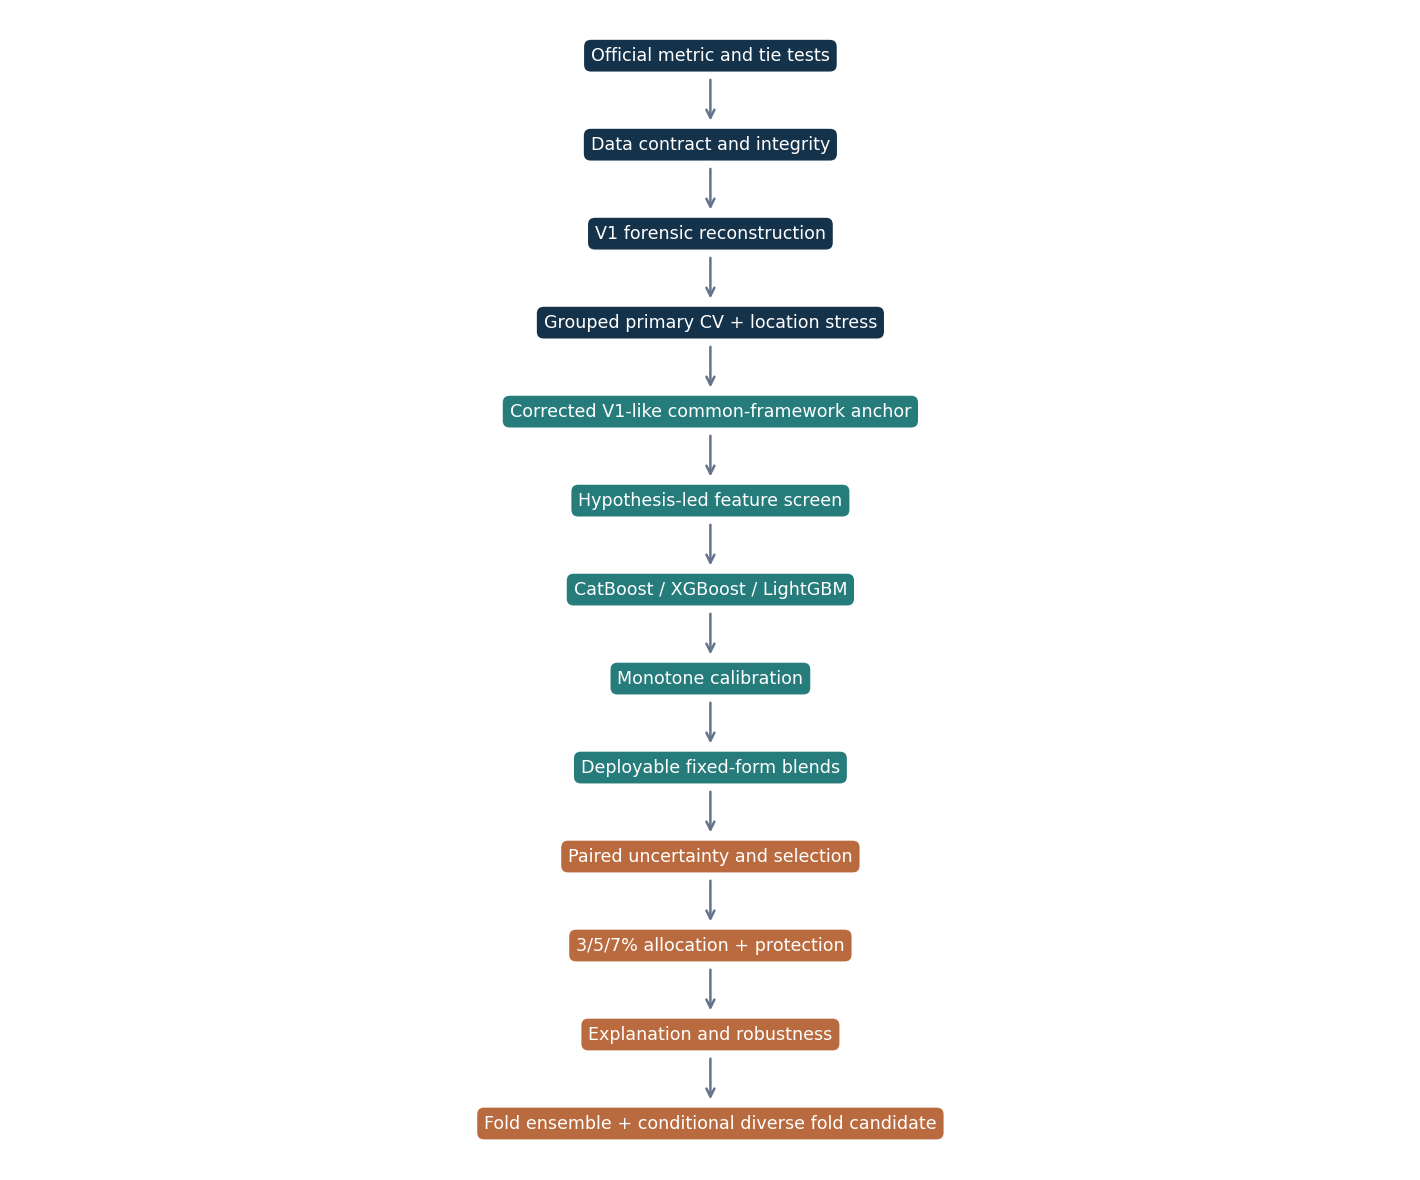

*Figure 3.1. V2 evidence flow from verified specification to conditional submission portfolio.*

In [6]:
steps = [
    "Official metric and tie tests", "Data contract and integrity", "V1 forensic reconstruction",
    "Grouped primary CV + location stress", "Corrected V1-like common-framework anchor",
    "Hypothesis-led feature screen", "CatBoost / XGBoost / LightGBM",
    "Monotone calibration", "Deployable fixed-form blends", "Paired uncertainty and selection",
    "3/5/7% allocation + protection", "Explanation and robustness", "Fold ensemble + conditional diverse fold candidate",
]
fig, ax = plt.subplots(figsize=(12, 10))
ax.axis("off")
for i, label in enumerate(steps):
    y_pos = 1 - (i + 0.5) / len(steps)
    color = COLORS["navy"] if i < 4 else COLORS["teal"] if i < 9 else COLORS["orange"]
    ax.text(
        0.5, y_pos, label, ha="center", va="center", color="white", fontsize=10.5,
        bbox=dict(boxstyle="round,pad=0.45", facecolor=color, edgecolor="white", linewidth=1.2),
    )
    if i < len(steps) - 1:
        next_y = 1 - (i + 1.5) / len(steps)
        ax.annotate("", xy=(0.5, next_y + 0.018), xytext=(0.5, y_pos - 0.018),
                    arrowprops=dict(arrowstyle="->", color=COLORS["gray"], lw=1.5))
finish_figure(fig, "3.1", "V2 evidence flow from verified specification to conditional submission portfolio.")


## 3.4 Data Discovery and Contract Validation

Files are identified by schema rather than a hard-coded Kaggle dataset slug. Semantic administrative codes are loaded as strings before pandas can remove leading zeros. The test table is then aligned to the sample-submission order with one-to-one validation.


In [7]:
ID_COL, TARGET_COL = "claim_id", "label"
SEMANTIC_CATEGORICAL = {
    "kdkc", "dati2", "typeppk", "jkpst", "jnspelsep", "cmg", "severitylevel", "diagprimer"
}


def csv_schema(path):
    return pd.read_csv(path, nrows=0).columns.tolist()


def discover_competition_files():
    roots = [Path("/kaggle/input")] if IS_KAGGLE else [Path.cwd() / "data", Path.cwd().parent / "data"]
    records = []
    for root in roots:
        if root.exists():
            for path in root.rglob("*.csv"):
                try:
                    records.append((path, csv_schema(path), path.stat().st_size))
                except Exception:
                    continue
    train_options = [r for r in records if {ID_COL, TARGET_COL}.issubset(r[1])]
    sample_options = [r for r in records if r[1] == [ID_COL, "fraud_probability"]]
    if not train_options or not sample_options:
        raise FileNotFoundError("Could not locate the DAC train and sample-submission schemas under Kaggle input.")
    for train_record in sorted(train_options, key=lambda r:("train" in r[0].name.lower(), r[2]), reverse=True):
        expected = set(train_record[1]) - {TARGET_COL}
        test_options = [r for r in records if set(r[1]) == expected]
        for test_record in sorted(test_options, key=lambda r:("test" in r[0].name.lower(), r[2]), reverse=True):
            test_ids = set(pd.read_csv(test_record[0], usecols=[ID_COL], dtype={ID_COL:"string"})[ID_COL])
            for sample_record in sorted(sample_options, key=lambda r:("sample" in r[0].name.lower(), r[2]), reverse=True):
                sample_ids = set(pd.read_csv(sample_record[0], usecols=[ID_COL], dtype={ID_COL:"string"})[ID_COL])
                if test_ids == sample_ids:
                    return train_record[0], test_record[0], sample_record[0]
    raise FileNotFoundError("No train/test/sample trio has mutually consistent schemas and claim IDs.")


def read_claim_csv(path):
    columns = csv_schema(path)
    string_columns = [c for c in ({ID_COL} | SEMANTIC_CATEGORICAL) if c in columns]
    return pd.read_csv(path, dtype={c:"string" for c in string_columns}, low_memory=False)


TRAIN_PATH, TEST_PATH, SAMPLE_PATH = discover_competition_files()
train_raw = read_claim_csv(TRAIN_PATH)
test_raw = read_claim_csv(TEST_PATH)
sample_submission = read_claim_csv(SAMPLE_PATH)

if list(sample_submission.columns) != [ID_COL, "fraud_probability"]:
    raise ValueError("Sample submission must contain claim_id and fraud_probability in that order.")
if TARGET_COL not in train_raw or TARGET_COL in test_raw:
    raise ValueError("Target column contract is invalid.")
if train_raw[ID_COL].duplicated().any() or test_raw[ID_COL].duplicated().any():
    raise ValueError("claim_id must be unique within train and test.")

test_raw = (
    sample_submission[[ID_COL]].assign(_submission_order=np.arange(len(sample_submission)))
    .merge(test_raw, on=ID_COL, how="left", validate="one_to_one", indicator=True)
    .sort_values("_submission_order").reset_index(drop=True)
)
if len(test_raw) != len(sample_submission) or not test_raw["_merge"].eq("both").all():
    raise ValueError("Test alignment to the sample submission failed.")
test_raw = test_raw.drop(columns=["_submission_order", "_merge"])

REPORT_FACTS.update({
    "train_rows":len(train_raw), "test_rows":len(test_raw), "columns":train_raw.shape[1],
    "train_path":str(TRAIN_PATH), "test_path":str(TEST_PATH), "sample_path":str(SAMPLE_PATH),
})
display(Markdown(
    f"Loaded **{len(train_raw):,} labeled claims**, **{len(test_raw):,} evaluation claims**, and "
    f"**{train_raw.shape[1]:,} training columns** from `{TRAIN_PATH.parent}`. Test order exactly follows the sample submission."
))


Loaded **160,174 labeled claims**, **40,043 evaluation claims**, and **53 training columns** from `/kaggle/input/competitions/dac-its-2026`. Test order exactly follows the sample submission.

## 3.5 Domain-Safe Representation and Feature Hypotheses

Raw fields are retained. Derived features are limited to families with a stated mechanism and an ablation path: utilization burden, density relative to stay, concentration across grouped codes, semantic code hierarchy, missingness, and a small set of interactions implicated by V1 errors. Frequencies are learned separately inside each outer fold in Section 3.11.


In [8]:
def clean_claims(frame):
    out = frame.copy()
    for column in out.columns:
        if column == TARGET_COL:
            out[column] = pd.to_numeric(out[column], errors="raise")
        elif column in ({ID_COL} | SEMANTIC_CATEGORICAL) or out[column].dtype == "object":
            values = out[column].astype("string").str.strip()
            out[column] = values.mask(values.eq(""), "__MISSING__").fillna("__MISSING__")
        else:
            out[column] = pd.to_numeric(out[column], errors="coerce")
    return out


def entropy_and_share(block):
    values = block.to_numpy(dtype=float)
    totals = values.sum(axis=1)
    shares = np.divide(values, totals[:, None], out=np.zeros_like(values), where=totals[:, None] > 0)
    entropy = -(np.where(shares > 0, shares * np.log(shares + 1e-12), 0)).sum(axis=1)
    maximum_share = np.divide(values.max(axis=1), totals, out=np.zeros(len(values)), where=totals > 0)
    return entropy, maximum_share


def engineer_features(frame):
    out = frame.copy()
    dx = [c for c in out if c.startswith("dx2_")]
    proc = [c for c in out if c.startswith("proc")]
    age = pd.to_numeric(out.get("umur"), errors="coerce")
    los = pd.to_numeric(out.get("los"), errors="coerce").clip(lower=0)
    out["age_band"] = age_groups(age).astype("string")
    out["is_pediatric"] = age.le(17).fillna(False).astype(int)
    out["is_older_adult"] = age.ge(60).fillna(False).astype(int)
    out["zero_los"] = los.eq(0).fillna(False).astype(int)
    out["log1p_los"] = np.log1p(los)
    # Preserve missingness for the fold-fitted model/preprocessor; no full-data statistic enters this feature.
    out["age_x_log_los"] = age * out["log1p_los"]

    for prefix, columns in (("diagnosis", dx), ("procedure", proc)):
        block = out[columns].apply(pd.to_numeric, errors="coerce").fillna(0).clip(lower=0)
        out[f"{prefix}_total"] = block.sum(axis=1)
        out[f"{prefix}_nonzero_groups"] = block.ne(0).sum(axis=1)
        out[f"{prefix}_max_group"] = block.max(axis=1)
        entropy, maximum_share = entropy_and_share(block)
        out[f"{prefix}_entropy"] = entropy
        out[f"{prefix}_max_share"] = maximum_share

    out["total_coded_burden"] = out["diagnosis_total"] + out["procedure_total"]
    out["total_nonzero_groups"] = out["diagnosis_nonzero_groups"] + out["procedure_nonzero_groups"]
    out["log1p_coded_burden"] = np.log1p(out["total_coded_burden"])
    out["procedure_to_diagnosis"] = (out["procedure_total"] + 0.5) / (out["diagnosis_total"] + 0.5)
    out["burden_per_day"] = out["total_coded_burden"] / (los.fillna(0) + 1)
    out["procedure_per_day"] = out["procedure_total"] / (los.fillna(0) + 1)
    out["diagnosis_per_day"] = out["diagnosis_total"] / (los.fillna(0) + 1)
    missing_block = out.drop(columns=[c for c in [ID_COL, TARGET_COL] if c in out])
    missing_count = missing_block.isna().sum(axis=1)
    for column in missing_block.select_dtypes(include=["object", "string"]).columns:
        missing_count += missing_block[column].astype("string").eq("__MISSING__").astype(int)
    out["missing_field_count"] = missing_count

    for source in ["kdkc", "dati2"]:
        if source in out:
            out[f"{source}_prefix2"] = out[source].astype("string").str[:2]
    interactions = {
        "cmg__severity": ("cmg", "severitylevel"),
        "service__facility": ("jnspelsep", "typeppk"),
        "geo__facility": ("dati2", "typeppk"),
        "kdkc__dati2": ("kdkc", "dati2"),
        "diagnosis__cmg": ("diagprimer", "cmg"),
        "diagnosis__service": ("diagprimer", "jnspelsep"),
        "diagnosis__facility": ("diagprimer", "typeppk"),
        "cmg__facility": ("cmg", "typeppk"),
    }
    for name, (left, right) in interactions.items():
        if left in out and right in out:
            out[name] = out[left].astype("string") + "__" + out[right].astype("string")
    return out


train_clean, test_clean = clean_claims(train_raw), clean_claims(test_raw)
train_model, test_model = engineer_features(train_clean), engineer_features(test_clean)
target_values = pd.to_numeric(train_model[TARGET_COL], errors="raise")
if target_values.isna().any() or not target_values.isin([0, 1]).all():
    raise ValueError("Training label must be complete and binary.")
y = target_values.astype(int).to_numpy()
TIE_KEYS = train_raw[ID_COL].astype("string").to_numpy(dtype=str)
TEST_TIE_KEYS = test_raw[ID_COL].astype("string").to_numpy(dtype=str)

raw_feature_columns = [c for c in train_clean if c not in {ID_COL, TARGET_COL}]
CONSTANT_COLUMNS = [c for c in train_model if c not in {ID_COL, TARGET_COL} and train_model[c].nunique(dropna=False) <= 1]
ALL_FEATURE_COLUMNS = [c for c in train_model if c not in {ID_COL, TARGET_COL, *CONSTANT_COLUMNS}]
CATEGORICAL_COLUMNS = [
    c for c in ALL_FEATURE_COLUMNS
    if c in SEMANTIC_CATEGORICAL or str(train_model[c].dtype) in {"object", "string"}
]
NUMERIC_COLUMNS = [c for c in ALL_FEATURE_COLUMNS if c not in CATEGORICAL_COLUMNS]

V1_ENGINEERED_COLUMNS = [
    "age_band", "is_pediatric", "is_older_adult", "log1p_los",
    "diagnosis_total", "diagnosis_nonzero_groups", "diagnosis_max_group",
    "procedure_total", "procedure_nonzero_groups", "procedure_max_group",
    "total_coded_burden", "log1p_coded_burden",
    "cmg__severity", "service__facility", "geo__facility",
]
V1_FEATURE_COLUMNS = [c for c in raw_feature_columns + V1_ENGINEERED_COLUMNS if c in ALL_FEATURE_COLUMNS]
V2_FEATURE_COLUMNS = list(ALL_FEATURE_COLUMNS)
FREQUENCY_BASE_COLUMNS = [
    c for c in ["kdkc", "dati2", "geo__facility", "kdkc__dati2", "diagnosis__facility", "diagnosis__cmg"]
    if c in V2_FEATURE_COLUMNS
]

PROTECTED = pd.DataFrame({
    "gender":train_clean.get("jkpst", pd.Series("Missing", index=train_clean.index)),
    "age":train_clean.get("umur", pd.Series(np.nan, index=train_clean.index)),
})
TEST_PROTECTED = pd.DataFrame({
    "gender":test_clean.get("jkpst", pd.Series("Missing", index=test_clean.index)),
    "age":test_clean.get("umur", pd.Series(np.nan, index=test_clean.index)),
})
PROTECTED_FEATURES = [c for c in ["jkpst", "umur", "age_band", "is_pediatric", "is_older_adult", "age_x_log_los"] if c in V2_FEATURE_COLUMNS]
LOCATION_PROXY_FEATURES = [c for c in ["kdkc", "dati2", "kdkc_prefix2", "dati2_prefix2", "geo__facility", "kdkc__dati2"] if c in V2_FEATURE_COLUMNS]

FEATURE_FAMILY_COLUMNS = {
    "code hierarchy": [c for c in ["kdkc_prefix2", "dati2_prefix2"] if c in V2_FEATURE_COLUMNS],
    "burden density": [c for c in ["zero_los", "age_x_log_los", "procedure_to_diagnosis", "burden_per_day", "procedure_per_day", "diagnosis_per_day"] if c in V2_FEATURE_COLUMNS],
    "code concentration": [c for c in ["diagnosis_entropy", "diagnosis_max_share", "procedure_entropy", "procedure_max_share", "total_nonzero_groups"] if c in V2_FEATURE_COLUMNS],
    "structured interactions": [c for c in ["kdkc__dati2", "diagnosis__cmg", "diagnosis__service", "diagnosis__facility", "cmg__facility"] if c in V2_FEATURE_COLUMNS],
}

FEATURE_HYPOTHESES = pd.DataFrame([
    ("F1", "Preserve semantic codes", "Leading zeros encode administrative code structure and must survive loading.", "string codes and two-character hierarchy", "corrected V1-like anchor versus V2"),
    ("F2", "Burden density", "Similar counts may imply different intensity over different lengths of stay.", "burden/procedure/diagnosis per day", "feature-family delta and error contrasts"),
    ("F3", "Code concentration", "Total burden misses whether activity is diffuse or concentrated.", "entropy and maximum share", "feature-family delta and importance"),
    ("F4", "Fold-safe rarity", "Rare locations and combinations may mark unusual billing templates.", "outer-train frequency maps", "V2 model gain and near-boundary analysis"),
    ("F5", "Structured interactions", "V1 errors and importance implicate diagnosis, service, facility, severity, and geography jointly.", "limited categorical crosses", "CatBoost screen and cross-model recovery"),
], columns=["ID", "Hypothesis", "Motivation", "Implementation", "Test"])

REPORT_FACTS.update({
    "target_prevalence":float(y.mean()), "v1_features":len(V1_FEATURE_COLUMNS),
    "v2_features":len(V2_FEATURE_COLUMNS), "categorical_features":len(CATEGORICAL_COLUMNS),
    "constant_columns":CONSTANT_COLUMNS,
})
show_table(FEATURE_HYPOTHESES, "3.1", "Hypothesis-driven feature families and predeclared tests")
display(Markdown(
    f"The labeled fraud prevalence is **{y.mean():.2%}**. The corrected V1-like set has **{len(V1_FEATURE_COLUMNS)}** "
    f"features; V2 has **{len(V2_FEATURE_COLUMNS)}** before fold-safe frequencies. The prevalence is a property of "
    "the competition sample, not an asserted operational fraud base rate."
))


**Table 3.1. Hypothesis-driven feature families and predeclared tests**

,ID,Hypothesis,Motivation,Implementation,Test
0,F1,Preserve semantic codes,Leading zeros encode administrative code structure and must survive loading.,string codes and two-character hierarchy,corrected V1-like anchor versus V2
1,F2,Burden density,Similar counts may imply different intensity over different lengths of stay.,burden/procedure/diagnosis per day,feature-family delta and error contrasts
2,F3,Code concentration,Total burden misses whether activity is diffuse or concentrated.,entropy and maximum share,feature-family delta and importance
3,F4,Fold-safe rarity,Rare locations and combinations may mark unusual billing templates.,outer-train frequency maps,V2 model gain and near-boundary analysis
4,F5,Structured interactions,"V1 errors and importance implicate diagnosis, service, facility, severity, and geography jointly.",limited categorical crosses,CatBoost screen and cross-model recovery


The labeled fraud prevalence is **50.07%**. The corrected V1-like set has **63** features; V2 has **81** before fold-safe frequencies. The prevalence is a property of the competition sample, not an asserted operational fraud base rate.

## 3.6 Dataset Forensics

The integrity audit covers missing and inconsistent values, exact and feature duplicates, conflicting duplicate labels, train/test template overlap, implausible ranges, sparse grouped codes, categorical cardinality, identifier overlap, and label/source-order structure. Exact overlap is internal analysis of supplied data, never external label recovery.


In [9]:
def feature_signature(frame, columns):
    normalized = frame[columns].copy()
    for column in columns:
        normalized[column] = normalized[column].astype("string").fillna("__NA__")
    return pd.util.hash_pandas_object(normalized, index=False).astype("uint64")


def quality_profile(train_frame, test_frame):
    rows = []
    for column in train_frame.columns:
        if column == TARGET_COL:
            continue
        series, test_series = train_frame[column], test_frame[column]
        categorical = column in SEMANTIC_CATEGORICAL or column == ID_COL
        numeric = None if categorical else pd.to_numeric(series, errors="coerce")
        levels = series.astype("string").fillna("Missing").value_counts()
        train_levels, test_levels = set(series.dropna().astype(str)), set(test_series.dropna().astype(str))
        rows.append({
            "feature":column, "dtype":str(series.dtype), "missing_n":int(series.isna().sum()),
            "missing_pct":float(series.isna().mean()), "cardinality":int(series.nunique(dropna=False)),
            "rare_levels_lt20":int((levels < 20).sum()), "rows_in_rare_levels":int(levels[levels < 20].sum()),
            "train_only_levels":len(train_levels - test_levels), "test_only_levels":len(test_levels - train_levels),
            "min":float(numeric.min()) if numeric is not None and numeric.notna().any() else np.nan,
            "median":float(numeric.median()) if numeric is not None and numeric.notna().any() else np.nan,
            "max":float(numeric.max()) if numeric is not None and numeric.notna().any() else np.nan,
        })
    return pd.DataFrame(rows)


QUALITY_PROFILE = quality_profile(train_raw, test_raw)
signature_columns = [c for c in train_clean if c not in {ID_COL, TARGET_COL}]
SIGNATURE_GROUPS = feature_signature(train_clean, signature_columns)
TEST_SIGNATURES = feature_signature(test_clean, signature_columns)
signature_summary = pd.DataFrame({"signature":SIGNATURE_GROUPS, "label":y}).groupby("signature")["label"].agg(rows="size", positives="sum", label_values="nunique")

clinical_template_columns = [c for c in signature_columns if c not in {"kdkc", "dati2", "jkpst", "umur"}]
CLINICAL_SIGNATURES = feature_signature(train_clean, clinical_template_columns)
TEST_CLINICAL_SIGNATURES = feature_signature(test_clean, clinical_template_columns)

grouped_columns = [c for c in train_clean if c.startswith("dx2_") or c.startswith("proc")]
grouped_numeric = train_clean[grouped_columns].apply(pd.to_numeric, errors="coerce")
plausibility = {
    "age below 0":train_clean["umur"].lt(0),
    "age above 120":train_clean["umur"].gt(120),
    "negative length of stay":train_clean["los"].lt(0),
    "length of stay above 365 (review flag)":train_clean["los"].gt(365),
    "negative grouped diagnosis/procedure count":grouped_numeric.lt(0).any(axis=1),
    "non-integer grouped diagnosis/procedure count":grouped_numeric.mod(1).fillna(0).ne(0).any(axis=1),
}
PLAUSIBILITY = pd.DataFrame([{"check":name, "flagged_claims":int(mask.fillna(False).sum())} for name, mask in plausibility.items()])

label_transitions = int(np.count_nonzero(np.diff(y)))
row_deciles = pd.qcut(np.arange(len(y)), 10, labels=False)
SOURCE_ORDER_PROFILE = pd.DataFrame({"row_decile":row_deciles, "label":y}).groupby("row_decile")["label"].agg(claims="size", frauds="sum", fraud_rate="mean").reset_index()
constant = np.full(len(y), y.mean())
neutral_constant = official_metrics(y, constant, PROTECTED, 0.05, tie_key=TIE_KEYS)
k5 = int(np.floor(0.05 * len(y)))
source_selected = np.zeros(len(y), dtype=bool); source_selected[:k5] = True
source_tp = int(y[source_selected].sum())
source_nr = source_tp / k5 if k5 and y.sum() >= k5 else source_tp / max(int(y.sum()), 1)
SOURCE_ORDER_AUDIT = pd.DataFrame([
    {"tie_policy":"source-row stable (V1 defect)", "fraud_captured":source_tp, "NormalizedRecall@5%":source_nr},
    {"tie_policy":"claim_id neutral (V2)", "fraud_captured":neutral_constant["TP_K"], "NormalizedRecall@5%":neutral_constant["NormalizedRecall@5%"]},
    {"tie_policy":"tie expectation", "fraud_captured":neutral_constant["tie_expected_fraud_captured"], "NormalizedRecall@5%":neutral_constant["tie_expected_fraud_captured"] / max(1, min(k5, int(y.sum())))},
])

DUPLICATE_SUMMARY = pd.DataFrame([
    ("duplicate claim_id (train)", int(train_raw[ID_COL].duplicated().sum())),
    ("duplicate claim_id (test)", int(test_raw[ID_COL].duplicated().sum())),
    ("exact duplicate rows (train)", int(train_raw.duplicated().sum())),
    ("repeated exact-feature signature groups", int((signature_summary.rows > 1).sum())),
    ("rows in repeated exact-feature signatures", int(signature_summary.loc[signature_summary.rows > 1, "rows"].sum())),
    ("exact-feature signatures with conflicting labels", int((signature_summary.label_values > 1).sum())),
    ("test rows exactly matching a train signature", int(TEST_SIGNATURES.isin(set(SIGNATURE_GROUPS)).sum())),
    ("test rows matching a reduced clinical template", int(TEST_CLINICAL_SIGNATURES.isin(set(CLINICAL_SIGNATURES)).sum())),
    ("train/test claim_id overlap", int(train_raw[ID_COL].isin(set(test_raw[ID_COL])).sum())),
], columns=["check", "count"])

SPARSITY = pd.DataFrame({
    "feature":grouped_columns,
    "zero_pct":[float(grouped_numeric[c].fillna(0).eq(0).mean()) for c in grouped_columns],
    "nonzero_n":[int(grouped_numeric[c].fillna(0).ne(0).sum()) for c in grouped_columns],
}).sort_values("zero_pct", ascending=False)

CARDINALITY = QUALITY_PROFILE[["feature", "dtype", "cardinality", "rare_levels_lt20", "rows_in_rare_levels", "test_only_levels"]].sort_values("cardinality", ascending=False)
REPORT_FACTS.update({
    "missing_cells":int(train_raw.isna().sum().sum()), "label_transitions":label_transitions,
    "repeated_signature_rows":int(signature_summary.loc[signature_summary.rows > 1, "rows"].sum()),
    "conflicting_signatures":int((signature_summary.label_values > 1).sum()),
    "test_signature_overlap":int(TEST_SIGNATURES.isin(set(SIGNATURE_GROUPS)).sum()),
    "leading_zero_kdkc":int(train_raw["kdkc"].str.startswith("0").sum()),
    "leading_zero_dati2":int(train_raw["dati2"].str.startswith("0").sum()),
})
TABLES.update({
    "A.quality":QUALITY_PROFILE, "A.duplicates":DUPLICATE_SUMMARY, "A.plausibility":PLAUSIBILITY,
    "A.sparsity":SPARSITY, "A.cardinality":CARDINALITY, "A.source_order":SOURCE_ORDER_AUDIT,
})


## 3.7 Association and Subgroup Description

Categorical association uses chi-square with pooled rare levels and Cramér's $V$; numeric separation uses Mann–Whitney rank-biserial effect and KS distance. Benjamini–Hochberg correction controls multiplicity. Effect size and uncertainty—not significance alone—drive interpretation.


In [10]:
def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p); ranked = p[order]
    adjusted = np.minimum.accumulate((ranked * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    result = np.empty_like(adjusted); result[order] = np.clip(adjusted, 0, 1)
    return result


def categorical_associations(frame, target, columns):
    rows = []
    for column in columns:
        values = frame[column].astype("string").fillna("Missing")
        counts = values.value_counts(); values = values.where(values.map(counts) >= 20, "__RARE__")
        table = pd.crosstab(values, target)
        if min(table.shape) < 2:
            continue
        chi2, p_value, _, _ = stats.chi2_contingency(table, correction=False)
        denominator = len(values) * max(min(table.shape[0] - 1, table.shape[1] - 1), 1)
        rows.append({"feature":column, "p_value":p_value, "Cramers_V":math.sqrt(chi2 / denominator), "levels":table.shape[0]})
    result = pd.DataFrame(rows)
    if len(result): result["p_bh"] = benjamini_hochberg(result.p_value)
    return result.sort_values("Cramers_V", ascending=False)


def numeric_associations(frame, target, columns):
    rows = []
    for column in columns:
        values = pd.to_numeric(frame[column], errors="coerce")
        fraud, legitimate = values[np.asarray(target) == 1].dropna(), values[np.asarray(target) == 0].dropna()
        if not len(fraud) or not len(legitimate) or values.nunique(dropna=True) <= 1:
            continue
        u, p_value = stats.mannwhitneyu(fraud, legitimate, alternative="two-sided")
        effect = 2 * u / (len(fraud) * len(legitimate)) - 1
        rows.append({
            "feature":column, "p_value":p_value, "abs_rank_biserial":abs(effect),
            "signed_rank_biserial":effect, "KS":stats.ks_2samp(fraud, legitimate, method="asymp").statistic,
            "fraud_median":fraud.median(), "legitimate_median":legitimate.median(),
        })
    result = pd.DataFrame(rows)
    if len(result): result["p_bh"] = benjamini_hochberg(result.p_value)
    return result.sort_values("abs_rank_biserial", ascending=False)


def categorical_level_rates(frame, target, columns):
    rows = []
    for column in columns:
        summary = pd.DataFrame({"level":frame[column].astype("string"), "label":target}).groupby("level")["label"].agg(["size", "sum", "mean"]).reset_index()
        summary["feature"] = column
        summary["abs_rate_difference"] = (summary["mean"] - np.mean(target)).abs()
        rows.append(summary.rename(columns={"size":"claims", "sum":"frauds", "mean":"fraud_rate"}))
    return pd.concat(rows, ignore_index=True).sort_values(["abs_rate_difference", "claims"], ascending=[False, False])


raw_categorical = [c for c in raw_feature_columns if c in SEMANTIC_CATEGORICAL]
raw_numeric = [c for c in raw_feature_columns if c not in raw_categorical]
CATEGORICAL_ASSOCIATIONS = categorical_associations(train_clean, y, raw_categorical)
NUMERIC_ASSOCIATIONS = numeric_associations(train_clean, y, raw_numeric)
CATEGORY_LEVEL_RATES = categorical_level_rates(train_clean, y, raw_categorical)
TABLES.update({
    "A.categorical_associations":CATEGORICAL_ASSOCIATIONS,
    "A.numeric_associations":NUMERIC_ASSOCIATIONS,
    "A.category_rates":CATEGORY_LEVEL_RATES,
})


## 3.8 Leakage and Proxy Assessment

Identifiers, row order, protected fields, structural location variables, constants, extreme univariate signals, and claim fields are classified separately. Strong prediction is not called leakage without a semantic or availability reason. Protected and location variables are retained for the main competition model, evaluated for disparity, and stress-tested rather than manipulated after prediction.


In [11]:
def fold_safe_univariate_ap(frame, target, columns):
    splitter = StratifiedKFold(3, shuffle=True, random_state=CFG.seed)
    rows = []
    for column in columns:
        values = frame[column]
        prediction = np.zeros(len(frame))
        if column in SEMANTIC_CATEGORICAL or values.dtype == "object" or str(values.dtype) == "string":
            text = values.astype("string").fillna("Missing")
            for fit_idx, valid_idx in splitter.split(frame, target):
                means = pd.DataFrame({"x":text.iloc[fit_idx].to_numpy(), "y":target[fit_idx]}).groupby("x").y.mean()
                prediction[valid_idx] = text.iloc[valid_idx].map(means).fillna(target[fit_idx].mean())
        else:
            numeric = pd.to_numeric(values, errors="coerce")
            for fit_idx, valid_idx in splitter.split(frame, target):
                median = numeric.iloc[fit_idx].median()
                model = LogisticRegression(max_iter=250, random_state=CFG.seed)
                model.fit(numeric.iloc[fit_idx].fillna(median).to_numpy().reshape(-1, 1), target[fit_idx])
                prediction[valid_idx] = model.predict_proba(numeric.iloc[valid_idx].fillna(median).to_numpy().reshape(-1, 1))[:, 1]
        rows.append({"feature":column, "univariate_oof_AP":average_precision_score(target, prediction), "uniqueness_ratio":values.nunique(dropna=False) / len(values)})
    return pd.DataFrame(rows).sort_values("univariate_oof_AP", ascending=False)


UNIVARIATE_AUDIT = fold_safe_univariate_ap(train_clean, y, raw_feature_columns)
SUSPICIOUS_SIGNAL_FEATURES = UNIVARIATE_AUDIT.loc[UNIVARIATE_AUDIT.univariate_oof_AP >= 0.95, "feature"].tolist()
LEAKAGE_REGISTER = pd.DataFrame([
    (ID_COL, "identifier", "excluded from prediction; neutral tie key only", "unique alignment field"),
    ("source row position", "storage-order leakage", "excluded everywhere", f"only {label_transitions} label transition(s); V1 stable ties were invalid"),
    (", ".join(CONSTANT_COLUMNS) or "none", "non-informative", "excluded", "constant after cleaning/engineering"),
    (", ".join(PROTECTED_FEATURES), "protected or sensitive", "retain, score fairly, screen removal", "may encode case mix and direct demographic signal"),
    (", ".join(LOCATION_PROXY_FEATURES), "structural proxy", "retain for competition; location stress test", "V1 importance and removal evidence are large, but transportability is weaker"),
    (", ".join(SUSPICIOUS_SIGNAL_FEATURES) or "none", "empirically suspicious", "semantic review and importance cross-check", "extreme fold-safe univariate AP if present"),
    ("diagnosis/procedure/service/stay fields", "claim information", "retained", "available at scoring; predictive association is not causality"),
], columns=["feature_set", "classification", "decision", "rationale"])
TABLES.update({"A.univariate":UNIVARIATE_AUDIT, "A.leakage":LEAKAGE_REGISTER})


## 3.9 Train–Test Shift

Numeric KS and standardized mean difference, categorical Jensen–Shannon divergence, unseen levels, and adversarial-validation AUC assess covariate shift. They cannot reveal hidden labels. Importance is cross-referenced later; shifted important features are investigated rather than automatically removed.


In [12]:
def standardized_mean_difference(a, b):
    a, b = pd.to_numeric(a, errors="coerce"), pd.to_numeric(b, errors="coerce")
    pooled = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return float((a.mean() - b.mean()) / pooled) if pooled > 0 else 0.0


def categorical_js(a, b):
    a, b = pd.Series(a).astype("string").fillna("Missing"), pd.Series(b).astype("string").fillna("Missing")
    levels = sorted(set(a.unique()) | set(b.unique()))
    pa = a.value_counts(normalize=True).reindex(levels, fill_value=0).to_numpy()
    pb = b.value_counts(normalize=True).reindex(levels, fill_value=0).to_numpy()
    return float(jensenshannon(pa, pb, base=2) ** 2)


shift_rows = []
for column in raw_feature_columns:
    if column in raw_categorical:
        train_levels, test_levels = set(train_clean[column].astype(str)), set(test_clean[column].astype(str))
        shift_rows.append({"feature":column, "type":"categorical", "KS":np.nan, "abs_SMD":np.nan, "JS_divergence":categorical_js(train_clean[column], test_clean[column]), "unseen_test_levels":len(test_levels - train_levels)})
    else:
        a, b = pd.to_numeric(train_clean[column], errors="coerce").dropna(), pd.to_numeric(test_clean[column], errors="coerce").dropna()
        shift_rows.append({
            "feature":column, "type":"numeric",
            "KS":float(stats.ks_2samp(a, b, method="asymp").statistic) if len(a) and len(b) else np.nan,
            "abs_SMD":abs(standardized_mean_difference(a, b)), "JS_divergence":np.nan,
            "unseen_test_levels":np.nan,
        })
SHIFT_TABLE = pd.DataFrame(shift_rows)
SHIFT_TABLE["shift_magnitude"] = SHIFT_TABLE[["KS", "abs_SMD", "JS_divergence"]].max(axis=1, skipna=True)
SHIFT_TABLE = SHIFT_TABLE.sort_values("shift_magnitude", ascending=False)


def make_ohe(min_frequency=20):
    try:
        return OneHotEncoder(handle_unknown="ignore", min_frequency=min_frequency, sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", min_frequency=min_frequency, sparse=True)


def adversarial_validation(train_frame, test_frame):
    maximum = 50_000 if not CFG.fast_mode else 8_000
    train_sample = train_frame.sample(min(len(train_frame), maximum), random_state=CFG.seed)
    test_sample = test_frame.sample(min(len(test_frame), maximum), random_state=CFG.seed)
    combined = pd.concat([train_sample, test_sample], ignore_index=True)
    origin = np.r_[np.zeros(len(train_sample), dtype=int), np.ones(len(test_sample), dtype=int)]
    categorical = [c for c in raw_categorical if c in combined]
    numeric = [c for c in raw_feature_columns if c not in categorical]
    transformer = ColumnTransformer([
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("ohe", make_ohe(50))]), categorical),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ])
    model = Pipeline([("transform", transformer), ("model", LogisticRegression(max_iter=400, C=0.3, class_weight="balanced", random_state=CFG.seed))])
    prediction = cross_val_predict(model, combined[raw_feature_columns], origin, cv=StratifiedKFold(3, shuffle=True, random_state=CFG.seed), method="predict_proba", n_jobs=1)[:, 1]
    return roc_auc_score(origin, prediction)


ADVERSARIAL_AUC = adversarial_validation(train_clean[raw_feature_columns], test_clean[raw_feature_columns])
REPORT_FACTS["adversarial_auc"] = float(ADVERSARIAL_AUC)
TABLES["A.shift"] = SHIFT_TABLE


## 3.10 Primary and Stress-Test Validation

The common primary design is five-fold StratifiedGroupKFold by exact cleaned feature signature. It estimates performance on unseen exact templates while preserving class balance. Screens, blend weights, calibration choice, and provisional selection use folds 1–3; folds 4–5 are predeclared confirmation perspectives that may veto a fragile choice but are not used to tune it. Because standard OOF base models for the development folds were trained on other folds, this guard is not claimed to be fully nested external validation. A selected group-shuffle split holding out `kdkc` locations separately tests transportability and never picks the Kaggle model.


In [13]:
if pd.Series(SIGNATURE_GROUPS).nunique() >= CFG.folds:
    PRIMARY_SPLITS = list(StratifiedGroupKFold(CFG.folds, shuffle=True, random_state=CFG.seed).split(train_model, y, groups=SIGNATURE_GROUPS))
    PRIMARY_VALIDATION = "StratifiedGroupKFold by exact cleaned feature signature"
else:
    PRIMARY_SPLITS = list(StratifiedKFold(CFG.folds, shuffle=True, random_state=CFG.seed).split(train_model, y))
    PRIMARY_VALIDATION = "StratifiedKFold fallback"

FOLD_ID = np.full(len(y), -1, dtype=int)
validation_rows = []
for fold, (fit_idx, valid_idx) in enumerate(PRIMARY_SPLITS):
    FOLD_ID[valid_idx] = fold
    overlap = len(set(SIGNATURE_GROUPS.iloc[fit_idx]) & set(SIGNATURE_GROUPS.iloc[valid_idx]))
    validation_rows.append({
        "fold":fold + 1, "train_n":len(fit_idx), "valid_n":len(valid_idx),
        "train_fraud_rate":y[fit_idx].mean(), "valid_fraud_rate":y[valid_idx].mean(),
        "signature_overlap":overlap,
    })
VALIDATION_TABLE = pd.DataFrame(validation_rows)
if (FOLD_ID < 0).any() or VALIDATION_TABLE.signature_overlap.sum() != 0:
    raise RuntimeError("Primary fold construction failed its separation contract.")

# The first three folds drive screens/meta-selection; the last two are confirmation perspectives.
# Base-model OOF predictions remain standard five-fold OOF, so this is a guard against selection
# fragility rather than a claim of fully nested external validation.
SELECTION_FOLD_IDS = np.arange(max(1, CFG.folds - 2))
CONFIRMATION_FOLD_IDS = np.arange(max(1, CFG.folds - 2), CFG.folds)
VALIDATION_TABLE["role"] = np.where(VALIDATION_TABLE.fold.isin(SELECTION_FOLD_IDS + 1), "selection", "confirmation")

ordinary_overlap = 0
for fit_idx, valid_idx in StratifiedKFold(CFG.folds, shuffle=True, random_state=CFG.seed).split(train_model, y):
    ordinary_overlap += len(set(SIGNATURE_GROUPS.iloc[fit_idx]) & set(SIGNATURE_GROUPS.iloc[valid_idx]))

location_candidates = []
for candidate_seed in range(CFG.seed, CFG.seed + 30):
    split = next(GroupShuffleSplit(1, test_size=0.2, random_state=candidate_seed).split(train_model, y, groups=train_clean["kdkc"]))
    fit_idx, valid_idx = split
    penalty = abs(len(valid_idx) / len(y) - 0.2) + abs(y[valid_idx].mean() - y.mean())
    location_candidates.append((penalty, candidate_seed, fit_idx, valid_idx))
_, LOCATION_STRESS_SEED, LOCATION_TRAIN_IDX, LOCATION_VALID_IDX = min(location_candidates, key=lambda item:item[0])

fold_path = OUTPUT_DIR / "primary_fold_assignments.csv"
pd.DataFrame({ID_COL:TIE_KEYS, "fold":FOLD_ID}).to_csv(fold_path, index=False)
TABLES["A.validation"] = VALIDATION_TABLE
REPORT_FACTS.update({
    "primary_validation":PRIMARY_VALIDATION, "ordinary_signature_overlap":int(ordinary_overlap),
    "location_stress_seed":LOCATION_STRESS_SEED,
    "selection_folds":SELECTION_FOLD_IDS.tolist(), "confirmation_folds":CONFIRMATION_FOLD_IDS.tolist(),
})
display(Markdown(
    f"Primary CV has **0** train–validation exact-signature overlaps; ordinary stratification would create "
    f"**{ordinary_overlap:,}** overlapping signatures across folds. The location stress fold contains "
    f"**{len(LOCATION_VALID_IDX):,}** claims and uses seed **{LOCATION_STRESS_SEED}**."
))


Primary CV has **0** train–validation exact-signature overlaps; ordinary stratification would create **13,092** overlapping signatures across folds. The location stress fold contains **32,877** claims and uses seed **2049**.

## 3.11 V1 Reconstruction and Hypothesis Registry

V1 is treated as experimental evidence. The table below records the executed pipeline and artifacts, then separates verified facts from plausible interpretations and unresolved test-label questions. Historical V1 metrics retain their original evaluation context; the runtime corrected V1-like anchor below uses corrected ties, preserved codes, and the same primary folds as V2.


In [14]:
V1_TRACE = pd.DataFrame([
    ("raw data", "53 train columns; pandas inferred administrative codes before string conversion"),
    ("features", "48 raw predictors plus 15 static engineered fields; claim_id excluded"),
    ("folds", "5-fold stratified grouped CV by exact cleaned feature signature"),
    ("candidates", "prevalence, burden logistic, one-hot logistic, CatBoost, ordinal-coded XGBoost"),
    ("OOF", "persisted for all main candidates; fold-averaged test predictions also persisted"),
    ("calibration", "global OOF cross-fitting of raw/sigmoid/isotonic; fold-specific maps could reorder OOF rows"),
    ("blend", "fold-varying OOF Cat/XGB weights but one median deployment weight"),
    ("decision", "blend gain 0.000944 rejected by a 0.001 threshold; sigmoid CatBoost selected"),
    ("final fit", "single full-data CatBoost refit at median fold iteration; fold-average prediction not submitted"),
    ("submission", "results/v1/submission.csv; user-reported public score 0.95833"),
], columns=["stage", "verified implementation"])

V1_FORENSICS = pd.DataFrame([
    ("F01", "VERIFIED", "Labels form one fraud block then one legitimate block; only one transition.", "source-order tie breaking is invalid"),
    ("F02", "VERIFIED", "Stable V1 ties made a constant baseline NR@5%=1.0 and burden NR@3%=1.0.", "correct the shared top-k function and report tie ranges"),
    ("F03", "VERIFIED", "V1 CatBoost raw OOF: NR@5%=0.970155, AP=0.823402, Brier=0.172186.", "strong anchor, not proof of optimality"),
    ("F04", "VERIFIED", "V1 fixed Cat/XGB probability blends near 0.80 Cat improved all three raw components in artifact reanalysis.", "test fixed deployable blends under corrected CV"),
    ("F05", "VERIFIED", "Alternate Cat seed was highly correlated yet a two-seed mean improved boundary capture, AP, and Brier.", "evaluate a V2 seed ensemble"),
    ("F06", "VERIFIED", "Full-refit and fold-average V1 test scores had Spearman≈0.994 but only 91.66% top-5 overlap (167 swaps per side).", "treat inference strategy as real portfolio uncertainty"),
    ("F07", "VERIFIED", "Location-feature removal reduced V1 OOF Technical Score by about 0.095; unseen-kdkc stress score was about 0.752.", "retain for Kaggle but surface transport risk"),
    ("F08", "VERIFIED", "All five V1 CatBoost folds stopped at 2,195–2,200 of 2,200 iterations.", "test longer/regularized capacity rather than assume convergence"),
    ("F09", "VERIFIED", "V1 XGBoost represented categories with arbitrary ordinal numbers.", "replace with fold-fitted one-hot representation"),
    ("F10", "PLAUSIBLE", "The public gap may reflect ranking, validation, calibration, ensemble, or refit variance.", "public score cannot identify affected claims"),
    ("F11", "REJECTED", "High global prediction correlation implies equivalent audit portfolios.", "top-5 overlap directly contradicts this"),
    ("F12", "UNKNOWN", "Which inference candidate is best on private labels.", "preserve a second file only when runtime diversity is meaningful"),
], columns=["ID", "status", "evidence or hypothesis", "V2 consequence"])

V1_ARTIFACT_PROVENANCE = pd.DataFrame([
    ("results/v1/experiment_registry.csv", "d5158941b81b143d7336b344e79c82736fa3ca3ab0403d6ceb51a568ba80fd21"),
    ("results/v1/fold_metrics.csv", "48e92076a8675ac5bd84f862e483a3668c4e2d7b9acc2bd4d2d20694bffb9728"),
    ("results/v1/model_decision.csv", "130b15ff51ad0da088bbbad39614ebfe048f0e259e513315b725f0a62d68c886"),
    ("results/v1/predictions_catboost.npz", "ffa23f887c1b3312ee066e15c03d868a8af85c53b25b06fc8a7f5c5c74509ffa"),
    ("results/v1/predictions_xgboost.npz", "109980e0f56a0e75524147613edce29a160814d32a11fe11b1d8916df68d5408"),
    ("results/v1/submission.csv", "634a0a47816382174b1d1b3d235406fb48ef53cf65560339bf44a57f3b6e95ea"),
], columns=["repository artifact", "SHA-256 verified during V2 authoring"])

HYPOTHESES = [
    {"ID":"H01", "Hypothesis":"Label-neutral ties remove source-order optimism.", "Motivation":"F01–F02", "Test":"constant and burden tie sensitivity", "Evidence":"verified before training", "Status":"SUPPORTED"},
    {"ID":"H02", "Hypothesis":"Preserving semantic code strings and hierarchy improves representation.", "Motivation":"leading-zero audit", "Test":"corrected V1-like anchor versus V2 features", "Evidence":"await runtime", "Status":"INCONCLUSIVE"},
    {"ID":"H03", "Hypothesis":"Longer regularized CatBoost improves boundary ranking.", "Motivation":"F08", "Test":"two-setting screen then full CV", "Evidence":"await runtime", "Status":"INCONCLUSIVE"},
    {"ID":"H04", "Hypothesis":"Burden density, concentration, rarity, and structured interactions recover near-boundary fraud.", "Motivation":"V1 FP/FN error contrasts", "Test":"feature-family comparison and error audit", "Evidence":"await runtime", "Status":"INCONCLUSIVE"},
    {"ID":"H05", "Hypothesis":"A two-seed CatBoost mean reduces ranking variance.", "Motivation":"F05", "Test":"common OOF seed blend", "Evidence":"await runtime", "Status":"INCONCLUSIVE"},
    {"ID":"H06", "Hypothesis":"A fixed cross-family blend captures complementary fraud.", "Motivation":"F04 and OOF disagreement", "Test":"fixed probability/logit grids", "Evidence":"await runtime", "Status":"INCONCLUSIVE"},
    {"ID":"H07", "Hypothesis":"Fold-averaged inference is a safer primary than an unvalidated full refit.", "Motivation":"F06", "Test":"validated fold ensemble plus conditional test-diverse validated-candidate hedge", "Evidence":"test labels unavailable", "Status":"INCONCLUSIVE"},
    {"ID":"H08", "Hypothesis":"Location signal is useful in-distribution but less transportable.", "Motivation":"F07", "Test":"primary versus kdkc-held-out stress", "Evidence":"prior artifacts plus runtime stress", "Status":"SUPPORTED"},
    {"ID":"H09", "Hypothesis":"Monotone calibration improves Brier without changing ranking.", "Motivation":"15% calibration weight", "Test":"outer-fold cross-fitted raw/sigmoid/beta/isotonic", "Evidence":"await runtime", "Status":"INCONCLUSIVE"},
    {"ID":"H10", "Hypothesis":"A direct learning-to-rank model is worth its added complexity.", "Motivation":"55% top-5 weight", "Test":"design review", "Evidence":"no query groups; calibration and API risk exceed current evidence", "Status":"REJECTED"},
]
HYPOTHESIS_REGISTRY = pd.DataFrame(HYPOTHESES)
show_table(V1_TRACE, "3.2", "Verified V1 pipeline reconstruction")
show_table(V1_FORENSICS, "3.3", "V1 forensic claims classified by evidence status")
show_table(V1_ARTIFACT_PROVENANCE, "3.3a", "Immutable provenance for the V1 evidence quoted in this notebook")
show_table(HYPOTHESIS_REGISTRY, "3.4", "Pre-experiment hypothesis registry")


**Table 3.2. Verified V1 pipeline reconstruction**

,stage,verified implementation
0,raw data,53 train columns; pandas inferred administrative codes before string conversion
1,features,48 raw predictors plus 15 static engineered fields; claim_id excluded
2,folds,5-fold stratified grouped CV by exact cleaned feature signature
3,candidates,"prevalence, burden logistic, one-hot logistic, CatBoost, ordinal-coded XGBoost"
4,OOF,persisted for all main candidates; fold-averaged test predictions also persisted
5,calibration,global OOF cross-fitting of raw/sigmoid/isotonic; fold-specific maps could reorder OOF rows
6,blend,fold-varying OOF Cat/XGB weights but one median deployment weight
7,decision,blend gain 0.000944 rejected by a 0.001 threshold; sigmoid CatBoost selected
8,final fit,single full-data CatBoost refit at median fold iteration; fold-average prediction not submitted
9,submission,results/v1/submission.csv; user-reported public score 0.95833


**Table 3.3. V1 forensic claims classified by evidence status**

,ID,status,evidence or hypothesis,V2 consequence
0,F01,VERIFIED,Labels form one fraud block then one legitimate block; only one transition.,source-order tie breaking is invalid
1,F02,VERIFIED,Stable V1 ties made a constant baseline NR@5%=1.0 and burden NR@3%=1.0.,correct the shared top-k function and report tie ranges
2,F03,VERIFIED,"V1 CatBoost raw OOF: NR@5%=0.970155, AP=0.823402, Brier=0.172186.","strong anchor, not proof of optimality"
3,F04,VERIFIED,V1 fixed Cat/XGB probability blends near 0.80 Cat improved all three raw components in artifact reanalysis.,test fixed deployable blends under corrected CV
4,F05,VERIFIED,"Alternate Cat seed was highly correlated yet a two-seed mean improved boundary capture, AP, and Brier.",evaluate a V2 seed ensemble
5,F06,VERIFIED,Full-refit and fold-average V1 test scores had Spearman≈0.994 but only 91.66% top-5 overlap (167 swaps per side).,treat inference strategy as real portfolio uncertainty
6,F07,VERIFIED,Location-feature removal reduced V1 OOF Technical Score by about 0.095; unseen-kdkc stress score was about 0.752.,retain for Kaggle but surface transport risk
7,F08,VERIFIED,"All five V1 CatBoost folds stopped at 2,195–2,200 of 2,200 iterations.",test longer/regularized capacity rather than assume convergence
8,F09,VERIFIED,V1 XGBoost represented categories with arbitrary ordinal numbers.,replace with fold-fitted one-hot representation
9,F10,PLAUSIBLE,"The public gap may reflect ranking, validation, calibration, ensemble, or refit variance.",public score cannot identify affected claims


**Table 3.3a. Immutable provenance for the V1 evidence quoted in this notebook**

,repository artifact,SHA-256 verified during V2 authoring
0,results/v1/experiment_registry.csv,d5158941b81b143d7336b344e79c82736fa3ca3ab0403d6ceb51a568ba80fd21
1,results/v1/fold_metrics.csv,48e92076a8675ac5bd84f862e483a3668c4e2d7b9acc2bd4d2d20694bffb9728
2,results/v1/model_decision.csv,130b15ff51ad0da088bbbad39614ebfe048f0e259e513315b725f0a62d68c886
3,results/v1/predictions_catboost.npz,ffa23f887c1b3312ee066e15c03d868a8af85c53b25b06fc8a7f5c5c74509ffa
4,results/v1/predictions_xgboost.npz,109980e0f56a0e75524147613edce29a160814d32a11fe11b1d8916df68d5408
5,results/v1/submission.csv,634a0a47816382174b1d1b3d235406fb48ef53cf65560339bf44a57f3b6e95ea


**Table 3.4. Pre-experiment hypothesis registry**

,ID,Hypothesis,Motivation,Test,Evidence,Status
0,H01,Label-neutral ties remove source-order optimism.,F01–F02,constant and burden tie sensitivity,verified before training,SUPPORTED
1,H02,Preserving semantic code strings and hierarchy improves representation.,leading-zero audit,corrected V1-like anchor versus V2 features,await runtime,INCONCLUSIVE
2,H03,Longer regularized CatBoost improves boundary ranking.,F08,two-setting screen then full CV,await runtime,INCONCLUSIVE
3,H04,"Burden density, concentration, rarity, and structured interactions recover near-boundary fraud.",V1 FP/FN error contrasts,feature-family comparison and error audit,await runtime,INCONCLUSIVE
4,H05,A two-seed CatBoost mean reduces ranking variance.,F05,common OOF seed blend,await runtime,INCONCLUSIVE
5,H06,A fixed cross-family blend captures complementary fraud.,F04 and OOF disagreement,fixed probability/logit grids,await runtime,INCONCLUSIVE
6,H07,Fold-averaged inference is a safer primary than an unvalidated full refit.,F06,validated fold ensemble plus conditional test-diverse validated-candidate hedge,test labels unavailable,INCONCLUSIVE
7,H08,Location signal is useful in-distribution but less transportable.,F07,primary versus kdkc-held-out stress,prior artifacts plus runtime stress,SUPPORTED
8,H09,Monotone calibration improves Brier without changing ranking.,15% calibration weight,outer-fold cross-fitted raw/sigmoid/beta/isotonic,await runtime,INCONCLUSIVE
9,H10,A direct learning-to-rank model is worth its added complexity.,55% top-5 weight,design review,no query groups; calibration and API risk exceed current evidence,REJECTED


## 3.12 Progressive Model Ladder and Staged CatBoost Screen

All candidates share the primary folds and label-neutral metrics. Fold-safe frequency maps use only the outer training partition. A corrected V1-like CatBoost provides the common-framework anchor. Two V2 CatBoost settings and hypothesis-led feature removals receive the same two-fold fixed-round screen; only the programmatically chosen representation receives full CV. Every boosted screen and full-CV finalist uses a predeclared fixed iteration count, so an outer validation label never chooses the iteration at which that same fold is scored. The second CatBoost seed tests variance, XGBoost fixes V1's ordinal encoding, and LightGBM adds a complementary tree-growth strategy. The fold models—not a post-hoc full fit—produce the primary test prediction.


In [15]:
def add_frequency_features(fit_frame, valid_frame, evaluation_frame, features, enabled):
    fit = fit_frame[features].copy()
    valid = valid_frame[features].copy()
    evaluation = evaluation_frame[features].copy() if evaluation_frame is not None else None
    added = []
    if enabled:
        for column in FREQUENCY_BASE_COLUMNS:
            if column not in features:
                continue
            name = f"frequency__{column}"
            frequency = fit[column].astype("string").value_counts(dropna=False) / len(fit)
            fit[name] = fit[column].astype("string").map(frequency).fillna(0).astype(float)
            valid[name] = valid[column].astype("string").map(frequency).fillna(0).astype(float)
            if evaluation is not None:
                evaluation[name] = evaluation[column].astype("string").map(frequency).fillna(0).astype(float)
            added.append(name)
    return fit, valid, evaluation, features + added


def catboost_ready(frame, categorical):
    out = frame.copy()
    for column in categorical:
        out[column] = out[column].astype("string").fillna("__MISSING__").astype(str)
    for column in out.columns.difference(categorical):
        out[column] = pd.to_numeric(out[column], errors="coerce")
    return out


def tabular_preprocessor(frame, features, scale_numeric=False):
    categorical = [c for c in features if c in CATEGORICAL_COLUMNS]
    numeric = [c for c in features if c not in categorical]
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    transformer = ColumnTransformer([
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", make_ohe(20))]), categorical),
        ("numeric", Pipeline(numeric_steps), numeric),
    ], sparse_threshold=0.3)
    return transformer, categorical, numeric


def lgbm_average_precision(target, prediction):
    return "average_precision", average_precision_score(target, prediction), True


def xgboost_probability(model, matrix):
    """Use explicit DMatrix prediction so CPU sparse input does not trigger inplace device fallback."""
    prediction_args = {}
    try:
        prediction_args["iteration_range"] = (0, int(model.best_iteration) + 1)
    except (AttributeError, TypeError):
        pass
    return np.asarray(model.get_booster().predict(DMatrix(matrix), **prediction_args), dtype=float)


def lightgbm_probability(model, matrix):
    """Predict from the native booster on the same sparse representation used for fitting."""
    iterations = int(getattr(model, "best_iteration_", 0) or getattr(model, "n_estimators_", model.n_estimators))
    return np.asarray(model.booster_.predict(matrix, num_iteration=iterations), dtype=float)


def fit_predict_fold(kind, fit_frame, fit_target, valid_frame, valid_target, evaluation_frame, features, seed, parameters):
    order = np.random.default_rng(seed).permutation(len(fit_target))
    fit_frame, fit_target = fit_frame.iloc[order].reset_index(drop=True), np.asarray(fit_target)[order]
    categorical = [c for c in features if c in CATEGORICAL_COLUMNS]
    fallback = "none"

    if kind in {"Burden", "Logistic"}:
        transformer, _, _ = tabular_preprocessor(fit_frame, features, scale_numeric=True)
        model = Pipeline([
            ("transform", transformer),
            ("model", LogisticRegression(
                C=parameters.get("C", 0.5), max_iter=parameters.get("max_iter", 600),
                solver="lbfgs", random_state=seed,
            )),
        ])
        model.fit(fit_frame[features], fit_target)
        valid_prediction = model.predict_proba(valid_frame[features])[:, 1]
        test_prediction = model.predict_proba(evaluation_frame[features])[:, 1] if evaluation_frame is not None else None
        return valid_prediction, test_prediction, {"kind":kind, "model":model, "features":features}, None, fallback

    if kind == "CatBoost":
        fit_cb = catboost_ready(fit_frame[features], categorical)
        valid_cb = catboost_ready(valid_frame[features], categorical)
        evaluation_cb = catboost_ready(evaluation_frame[features], categorical) if evaluation_frame is not None else None
        fixed_iterations = bool(parameters.get("fixed_iterations", False))
        model_parameters = dict(
            loss_function="Logloss", allow_writing_files=False,
            verbose=False, random_seed=seed, task_type=CAT_TASK,
            iterations=parameters["iterations"], learning_rate=parameters["learning_rate"],
            depth=parameters["depth"], l2_leaf_reg=parameters["l2_leaf_reg"],
            random_strength=parameters["random_strength"], bootstrap_type="Bayesian",
            bagging_temperature=parameters["bagging_temperature"],
            max_ctr_complexity=parameters.get("max_ctr_complexity", 1),
            border_count=parameters.get("border_count", 128),
        )
        if parameters.get("scale_pos_weight") is not None:
            model_parameters["scale_pos_weight"] = parameters["scale_pos_weight"]
        if not fixed_iterations:
            model_parameters["eval_metric"] = "PRAUC:type=Classic"
        if CAT_DEVICES:
            model_parameters["devices"] = CAT_DEVICES
        model = CatBoostClassifier(**model_parameters)
        try:
            if fixed_iterations:
                model.fit(fit_cb, fit_target, cat_features=categorical, verbose=False)
            else:
                model.fit(
                    fit_cb, fit_target, cat_features=categorical, eval_set=(valid_cb, valid_target),
                    early_stopping_rounds=parameters.get("early_stopping", CFG.early_stopping),
                    use_best_model=True, verbose=False,
                )
        except Exception as error:
            message = str(error).lower()
            recoverable = CAT_TASK == "GPU" and any(token in message for token in ("gpu", "cuda", "nccl", "memory"))
            if not recoverable:
                raise
            fallback = "single GPU; max_ctr_complexity=1"
            model_parameters.update(devices="0", max_ctr_complexity=1)
            model = CatBoostClassifier(**model_parameters)
            if fixed_iterations:
                model.fit(fit_cb, fit_target, cat_features=categorical, verbose=False)
            else:
                model.fit(
                    fit_cb, fit_target, cat_features=categorical, eval_set=(valid_cb, valid_target),
                    early_stopping_rounds=parameters.get("early_stopping", CFG.early_stopping),
                    use_best_model=True, verbose=False,
                )
        valid_prediction = model.predict_proba(valid_cb)[:, 1]
        test_prediction = model.predict_proba(evaluation_cb)[:, 1] if evaluation_cb is not None else None
        best_iteration = int(parameters["iterations"]) if fixed_iterations else max(1, int(model.get_best_iteration()) + 1)
        bundle = {"kind":kind, "model":model, "features":features, "categorical":categorical}
        return valid_prediction, test_prediction, bundle, best_iteration, fallback

    transformer, _, _ = tabular_preprocessor(fit_frame, features, scale_numeric=False)
    fit_encoded = transformer.fit_transform(fit_frame[features])
    valid_encoded = transformer.transform(valid_frame[features])
    evaluation_encoded = transformer.transform(evaluation_frame[features]) if evaluation_frame is not None else None

    if kind == "XGBoost":
        fixed_iterations = bool(parameters.get("fixed_iterations", False))
        xgb_parameters = dict(
            n_estimators=parameters["n_estimators"], learning_rate=parameters["learning_rate"],
            max_depth=parameters["max_depth"], min_child_weight=parameters["min_child_weight"],
            subsample=parameters["subsample"], colsample_bytree=parameters["colsample_bytree"],
            reg_alpha=parameters["reg_alpha"], reg_lambda=parameters["reg_lambda"],
            objective="binary:logistic", eval_metric="aucpr", tree_method="hist", device=XGB_DEVICE,
            random_state=seed, n_jobs=8,
        )
        if not fixed_iterations:
            xgb_parameters["early_stopping_rounds"] = parameters.get("early_stopping", CFG.early_stopping)
        model = XGBClassifier(**xgb_parameters)
        try:
            if fixed_iterations:
                model.fit(fit_encoded, fit_target, verbose=False)
            else:
                model.fit(fit_encoded, fit_target, eval_set=[(valid_encoded, valid_target)], verbose=False)
        except Exception as error:
            message = str(error).lower()
            if XGB_DEVICE != "cuda" or not any(token in message for token in ("gpu", "cuda", "memory")):
                raise
            fallback = "CPU"
            model.set_params(device="cpu")
            if fixed_iterations:
                model.fit(fit_encoded, fit_target, verbose=False)
            else:
                model.fit(fit_encoded, fit_target, eval_set=[(valid_encoded, valid_target)], verbose=False)
        best_iteration = int(parameters["n_estimators"]) if fixed_iterations else int(getattr(model, "best_iteration", parameters["n_estimators"] - 1)) + 1
    elif kind == "LightGBM":
        if not LIGHTGBM_AVAILABLE:
            raise RuntimeError("LightGBM is unavailable in this runtime.")
        model = LGBMClassifier(
            n_estimators=parameters["n_estimators"], learning_rate=parameters["learning_rate"],
            num_leaves=parameters["num_leaves"], max_depth=parameters["max_depth"],
            min_child_samples=parameters["min_child_samples"], subsample=parameters["subsample"],
            subsample_freq=1,
            colsample_bytree=parameters["colsample_bytree"], reg_alpha=parameters["reg_alpha"],
            reg_lambda=parameters["reg_lambda"], objective="binary", random_state=seed,
            metric="None", n_jobs=-1, verbosity=-1,
        )
        fixed_iterations = bool(parameters.get("fixed_iterations", False))
        if fixed_iterations:
            model.fit(fit_encoded, fit_target)
            best_iteration = int(parameters["n_estimators"])
        else:
            model.fit(
                fit_encoded, fit_target, eval_set=[(valid_encoded, valid_target)], eval_metric=lgbm_average_precision,
                callbacks=[lgb.early_stopping(parameters.get("early_stopping", CFG.early_stopping), first_metric_only=True, verbose=False), lgb.log_evaluation(0)],
            )
            best_iteration = int(model.best_iteration_ or parameters["n_estimators"])
    else:
        raise ValueError(f"Unknown model kind: {kind}")

    prediction_function = xgboost_probability if kind == "XGBoost" else lightgbm_probability
    valid_prediction = prediction_function(model, valid_encoded)
    test_prediction = prediction_function(model, evaluation_encoded) if evaluation_encoded is not None else None
    bundle = {"kind":kind, "model":model, "transformer":transformer, "features":features}
    return valid_prediction, test_prediction, bundle, best_iteration, fallback


def predict_bundle(bundle, frame):
    features = bundle["features"]
    if bundle["kind"] == "CatBoost":
        ready = catboost_ready(frame[features], bundle["categorical"])
        return bundle["model"].predict_proba(ready)[:, 1]
    if bundle["kind"] == "XGBoost":
        return xgboost_probability(bundle["model"], bundle["transformer"].transform(frame[features]))
    if bundle["kind"] == "LightGBM":
        return lightgbm_probability(bundle["model"], bundle["transformer"].transform(frame[features]))
    return bundle["model"].predict_proba(frame[features])[:, 1]


def augmented_raw_metrics(target, prediction, groups, tie_key, capacity=0.05):
    result = official_metrics(target, prediction, groups, capacity, tie_key=tie_key, min_nonfraud=CFG.min_group_nonfraud)
    result["ROC_AUC"] = roc_auc_score(target, prediction) if len(np.unique(target)) == 2 else np.nan
    result["LogLoss"] = log_loss(target, np.clip(prediction, 1e-7, 1 - 1e-7), labels=[0, 1])
    return result


def run_cv(kind, name, features, parameters, seed=CFG.seed, use_frequency=False, retain_anchor=False, notes=""):
    oof = np.full(len(y), np.nan)
    test_folds, best_iterations, fold_rows, fallback_rows = [], [], [], []
    anchor = None
    started = time.perf_counter()
    for fold, (fit_idx, valid_idx) in enumerate(PRIMARY_SPLITS):
        fold_started = time.perf_counter()
        fit_frame, valid_frame, evaluation_frame, used_features = add_frequency_features(
            train_model.iloc[fit_idx], train_model.iloc[valid_idx], test_model,
            list(features), use_frequency,
        )
        valid_prediction, test_prediction, bundle, best_iteration, fallback = fit_predict_fold(
            kind, fit_frame, y[fit_idx], valid_frame, y[valid_idx], evaluation_frame,
            used_features, seed + fold, parameters,
        )
        oof[valid_idx] = np.clip(valid_prediction, 0, 1)
        test_folds.append(np.clip(test_prediction, 0, 1))
        if best_iteration is not None:
            best_iterations.append(best_iteration)
        if fallback != "none":
            fallback_rows.append(f"fold {fold + 1}: {fallback}")
        metric = augmented_raw_metrics(
            y[valid_idx], oof[valid_idx], PROTECTED.iloc[valid_idx].reset_index(drop=True),
            TIE_KEYS[valid_idx],
        )
        fold_rows.append({
            "model":name, "fold":fold + 1, "seed":seed + fold, **{k:v for k,v in metric.items() if not isinstance(v, pd.DataFrame)},
            "seconds":time.perf_counter() - fold_started, "best_iteration":best_iteration,
        })
        if kind == "CatBoost":
            importance = bundle["model"].get_feature_importance(type="FeatureImportance")
            IMPORTANCE_RECORDS.setdefault(name, []).append(pd.Series(importance, index=used_features, name=f"fold_{fold + 1}"))
        if retain_anchor and fold == 0:
            anchor = {"bundle":bundle, "valid_frame":valid_frame.copy(), "valid_idx":valid_idx.copy(), "prediction":oof[valid_idx].copy()}
        print(f"{name:24s} fold {fold + 1}/{CFG.folds} | TS={metric['TechnicalScore']:.5f} | NR5={metric['NormalizedRecall@5%']:.5f} | AP={metric['AveragePrecision']:.5f}")
        gc.collect()
    if np.isnan(oof).any():
        raise RuntimeError(f"{name} did not predict every OOF row")
    test_prediction = np.mean(test_folds, axis=0)
    global_metric = augmented_raw_metrics(y, oof, PROTECTED, TIE_KEYS)
    fold_frame = pd.DataFrame(fold_rows)
    runtime = (time.perf_counter() - started) / 60
    record = {
        "experiment_id":name, "model":kind, "feature_family":"V2 + fold frequencies" if use_frequency else "V1/static",
        "validation":PRIMARY_VALIDATION, "seed":seed, "parameters_summary":json.dumps(parameters, sort_keys=True),
        **{k:v for k,v in global_metric.items() if not isinstance(v, pd.DataFrame)},
        "fold_SD":fold_frame.TechnicalScore.std(ddof=1), "runtime_minutes":runtime,
        "notes":notes + (("; fallbacks=" + " | ".join(fallback_rows)) if fallback_rows else ""),
    }
    result = {
        "kind":kind, "name":name, "features":list(features), "parameters":dict(parameters),
        "seed":seed, "use_frequency":use_frequency, "oof":oof, "test":test_prediction,
        "test_folds":np.vstack(test_folds),
        "fold_metrics":fold_frame, "best_iterations":best_iterations, "record":record, "anchor":anchor,
    }
    CV_RESULTS[name] = result
    CANDIDATES[name] = {"raw_oof":oof, "raw_test":test_prediction, "components":[name], "complexity":1, "runtime_minutes":runtime}
    FOLD_RECORDS.extend(fold_rows); EXPERIMENTS.append(record)
    np.savez_compressed(OUTPUT_DIR / f"predictions_{name.lower().replace(' ', '_').replace('/', '_')}.npz", oof=oof, test=test_prediction)
    return result


def constant_baseline():
    oof, test = np.zeros(len(y)), np.zeros(len(test_model))
    rows = []
    for fold, (fit_idx, valid_idx) in enumerate(PRIMARY_SPLITS):
        prevalence = float(y[fit_idx].mean())
        oof[valid_idx] = prevalence; test += prevalence / CFG.folds
        metric = augmented_raw_metrics(y[valid_idx], oof[valid_idx], PROTECTED.iloc[valid_idx].reset_index(drop=True), TIE_KEYS[valid_idx])
        rows.append({"model":"Fold prevalence", "fold":fold + 1, "seed":CFG.seed, **{k:v for k,v in metric.items() if not isinstance(v, pd.DataFrame)}, "seconds":0.0, "best_iteration":np.nan})
    metric = augmented_raw_metrics(y, oof, PROTECTED, TIE_KEYS)
    record = {
        "experiment_id":"Fold prevalence", "model":"Constant", "feature_family":"none", "validation":PRIMARY_VALIDATION,
        "seed":CFG.seed, "parameters_summary":"fold-local prevalence", **{k:v for k,v in metric.items() if not isinstance(v, pd.DataFrame)},
        "fold_SD":pd.DataFrame(rows).TechnicalScore.std(ddof=1), "runtime_minutes":0.0,
        "notes":"claim_id resolves ties; expected and worst/best tie capture are also reported",
    }
    CV_RESULTS["Fold prevalence"] = {"oof":oof, "test":test, "fold_metrics":pd.DataFrame(rows), "record":record}
    FOLD_RECORDS.extend(rows); EXPERIMENTS.append(record)


def screen_catboost_configs(configurations):
    rows = []
    for label, parameters in configurations.items():
        for fold, (fit_idx, valid_idx) in enumerate(PRIMARY_SPLITS[:2]):
            fit_frame, valid_frame, _, used_features = add_frequency_features(
                train_model.iloc[fit_idx], train_model.iloc[valid_idx], None, V2_FEATURE_COLUMNS, True
            )
            prediction, _, _, best_iteration, fallback = fit_predict_fold(
                "CatBoost", fit_frame, y[fit_idx], valid_frame, y[valid_idx], None,
                used_features, CFG.seed + 500 + fold, parameters,
            )
            metric = augmented_raw_metrics(y[valid_idx], prediction, PROTECTED.iloc[valid_idx].reset_index(drop=True), TIE_KEYS[valid_idx])
            rows.append({"configuration":label, "fold":fold + 1, "best_iteration":best_iteration, "fallback":fallback, **{k:v for k,v in metric.items() if k in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]}})
    detail = pd.DataFrame(rows)
    summary = detail.groupby("configuration").agg(
        mean_TechnicalScore=("TechnicalScore", "mean"), mean_NR5=("NormalizedRecall@5%", "mean"),
        mean_AP=("AveragePrecision", "mean"), mean_Brier=("Brier", "mean"), fold_SD=("TechnicalScore", "std"),
    ).reset_index()
    best_score = summary.mean_TechnicalScore.max()
    shortlist = summary[summary.mean_TechnicalScore >= best_score - 0.0005].copy()
    shortlist["preference"] = shortlist.configuration.map({"depth7_regularized":0, "depth8_capacity":1}).fillna(9)
    selected = shortlist.sort_values(["preference", "fold_SD", "mean_TechnicalScore"], ascending=[True, True, False]).iloc[0].configuration
    return detail, summary, selected


In [16]:
BURDEN_FEATURES = [c for c in ["los", "diagnosis_total", "procedure_total", "severitylevel"] if c in V1_FEATURE_COLUMNS]
BURDEN_PARAMS = {"C":0.5, "max_iter":500}
LOGISTIC_PARAMS = {"C":0.5, "max_iter":700}
V1_CAT_PARAMS = {
    "iterations":CFG.v1_cat_iterations, "learning_rate":0.035, "depth":8,
    "l2_leaf_reg":6.0, "random_strength":0.5, "bagging_temperature":0.8,
    "max_ctr_complexity":1, "border_count":128, "early_stopping":180 if not CFG.fast_mode else CFG.early_stopping,
    "fixed_iterations":True,
}
CAT_SCREEN_CONFIGS = {
    "depth7_regularized":{
        "iterations":CFG.screen_iterations, "learning_rate":0.035, "depth":7,
        "l2_leaf_reg":8.0, "random_strength":0.25, "bagging_temperature":0.5,
        "max_ctr_complexity":2, "border_count":128, "early_stopping":140 if not CFG.fast_mode else CFG.early_stopping,
        "fixed_iterations":True,
    },
    "depth8_capacity":{
        "iterations":CFG.screen_iterations, "learning_rate":0.030, "depth":8,
        "l2_leaf_reg":8.0, "random_strength":0.35, "bagging_temperature":0.5,
        "max_ctr_complexity":2, "border_count":128, "early_stopping":140 if not CFG.fast_mode else CFG.early_stopping,
        "fixed_iterations":True,
    },
}
XGB_PARAMS = {
    "n_estimators":CFG.xgb_estimators, "learning_rate":0.035, "max_depth":7,
    "min_child_weight":6, "subsample":0.85, "colsample_bytree":0.82,
    "reg_alpha":0.08, "reg_lambda":7.0, "early_stopping":CFG.early_stopping,
    "fixed_iterations":True,
}
LGBM_PARAMS = {
    "n_estimators":CFG.lgbm_estimators, "learning_rate":0.025, "num_leaves":48,
    "max_depth":-1, "min_child_samples":60, "subsample":0.85, "colsample_bytree":0.82,
    "reg_alpha":0.10, "reg_lambda":7.0, "early_stopping":CFG.early_stopping,
    "fixed_iterations":True,
}
CALIBRATION_METHODS = ("raw", "sigmoid", "beta", "isotonic")
SELECTABLE_CALIBRATION_METHODS = ("raw", "sigmoid", "beta")
SELECTION_EXCLUSIONS = {
    "Burden baseline":"transparent diagnostic baseline; never a final competition candidate",
}
SELECTION_POLICY = {
    "max_tie_penalty":0.0005,
    "ensemble_min_gain":0.00075,
    "ensemble_min_fold_wins":3,
    "ensemble_min_confirmation_wins":1,
    "ensemble_max_component_overlap":0.985,
    "confirmation_max_loss":0.0005,
    "near_tie_tolerance":0.0005,
}
EXPECTED_EXPERIMENT_PLAN = pd.DataFrame([
    ("Fold prevalence", "Constant", False),
    ("Burden baseline", "Burden", False),
    ("Corrected V1-like anchor", "CatBoost", True),
    ("Logistic V2", "Logistic", True),
    ("CatBoost V2 seed 2026", "CatBoost", True),
    ("CatBoost V2 seed 2127", "CatBoost", True),
    ("XGBoost V2 one-hot", "XGBoost", True),
] + ([("LightGBM V2 one-hot", "LightGBM", True)] if LIGHTGBM_AVAILABLE else []),
    columns=["experiment_id", "model", "selection_candidate"],
)
REGISTRY_SCHEMA_CONTRACT = pd.DataFrame([
    ("experiment_id", "string", "complete and unique"),
    ("model", "known candidate type", "complete"),
    ("NormalizedRecall@5% / AveragePrecision / Brier", "finite float", "[0, 1]"),
    ("CalibrationScore / ProtectionScore / TechnicalScore", "finite float", "[0, 1]"),
    ("tie_penalty / robust_score", "finite float", "complete before selection"),
    ("prebootstrap_eligible", "native bool", "complete for every row; diagnostic baselines are False"),
    ("bootstrap_eligible", "native bool", "complete for every row after uncertainty"),
    ("selected", "native bool", "exactly one True after final selection"),
], columns=["field", "dtype", "invariant"])
SELECTION_PATH_COVERAGE = pd.DataFrame([
    ("A — multiple eligible", "rank by robust evidence; bootstrap consequential pair; apply near-tie simplicity rule"),
    ("B — one eligible", "select that validated candidate; runner-up comparison is optional"),
    ("C — no conservative survivor", "after registry validation, choose strongest valid single by robust score and disclose fallback"),
    ("D — ensemble rejected", "remove complex provisional winner; use surviving valid single or documented single fallback"),
    ("E — ensemble accepted", "retain ensemble if uncertainty and confirmation gates pass"),
    ("F — no secondary hedge", "write primary only and remove any stale secondary file"),
    ("G — secondary hedge justified", "validate and write an OOF-proximate, test-diverse alternative"),
], columns=["static path", "terminal behavior"])

# Rehearse the future one-to-one eligibility merge with planned IDs before any fit begins.
PREFLIGHT_REGISTRY = EXPECTED_EXPERIMENT_PLAN.loc[
    ~EXPECTED_EXPERIMENT_PLAN.experiment_id.eq("Fold prevalence"), ["experiment_id", "model"]
].reset_index(drop=True)
PREFLIGHT_ELIGIBILITY = pd.DataFrame([
    {
        "candidate":name,
        "tie_safe":bool(name not in SELECTION_EXCLUSIONS),
        "prebootstrap_eligible":bool(name not in SELECTION_EXCLUSIONS),
        "prebootstrap_reason":SELECTION_EXCLUSIONS.get(name, "planned selectable candidate"),
    }
    for name in PREFLIGHT_REGISTRY.experiment_id
])
PREFLIGHT_REGISTRY_MERGED = attach_registry_eligibility(PREFLIGHT_REGISTRY, PREFLIGHT_ELIGIBILITY)

# Early structural preflight: this executes before burden, CatBoost, XGBoost, or LightGBM fitting.
preflight_conditions = [
    ("full competition mode", not CFG.fast_mode, "DAC_FAST_MODE must be unset for a submission run"),
    ("primary fold count", len(PRIMARY_SPLITS) == CFG.folds == 5, "exactly five primary folds"),
    ("fold coverage", len(FOLD_ID) == len(y) and np.isin(FOLD_ID, np.arange(CFG.folds)).all(), "each train row belongs to one known fold"),
    ("selection/confirmation partition", not set(SELECTION_FOLD_IDS) & set(CONFIRMATION_FOLD_IDS) and set(np.r_[SELECTION_FOLD_IDS, CONFIRMATION_FOLD_IDS]) == set(range(CFG.folds)), "fold roles are disjoint and exhaustive"),
    ("feature contracts", bool(BURDEN_FEATURES) and bool(V1_FEATURE_COLUMNS) and bool(V2_FEATURE_COLUMNS), "all planned feature sets are non-empty"),
    ("feature leakage exclusion", all({ID_COL, TARGET_COL}.isdisjoint(features) for features in [BURDEN_FEATURES, V1_FEATURE_COLUMNS, V2_FEATURE_COLUMNS]), "identifier and label are absent from model features"),
    ("feature uniqueness", all(len(features) == len(set(features)) for features in [BURDEN_FEATURES, V1_FEATURE_COLUMNS, V2_FEATURE_COLUMNS]), "no duplicate feature names"),
    ("experiment IDs", EXPECTED_EXPERIMENT_PLAN.experiment_id.notna().all() and EXPECTED_EXPERIMENT_PLAN.experiment_id.is_unique, "planned IDs are complete and unique"),
    ("eligibility schema rehearsal", PREFLIGHT_REGISTRY_MERGED.prebootstrap_eligible.dtype == np.dtype(bool) and not PREFLIGHT_REGISTRY_MERGED.prebootstrap_eligible.isna().any() and set(SELECTION_EXCLUSIONS) <= set(PREFLIGHT_REGISTRY_MERGED.experiment_id), "every planned registry row receives explicit native-Boolean eligibility"),
    ("required model libraries", CatBoostClassifier is not None and XGBClassifier is not None and DMatrix is not None, f"CatBoost and XGBoost loaded; LightGBM optional availability={LIGHTGBM_AVAILABLE}"),
    ("calibration methods", CALIBRATION_METHODS == ("raw", "sigmoid", "beta", "isotonic") and set(SELECTABLE_CALIBRATION_METHODS) < set(CALIBRATION_METHODS), "isotonic remains diagnostic-only"),
    ("selection configuration", all(np.isfinite(list(SELECTION_POLICY.values()))) and all(value >= 0 for value in SELECTION_POLICY.values()), "selection thresholds are finite and non-negative"),
    ("fixed boosted rounds", V1_CAT_PARAMS["fixed_iterations"] and all(config["fixed_iterations"] for config in CAT_SCREEN_CONFIGS.values()) and XGB_PARAMS["fixed_iterations"] and LGBM_PARAMS["fixed_iterations"], "outer validation never chooses its own tree count"),
    ("sample submission schema", list(sample_submission.columns) == [ID_COL, "fraud_probability"] and sample_submission[ID_COL].notna().all() and sample_submission[ID_COL].is_unique, "claim_id plus fraud_probability with unique complete IDs"),
    ("test/sample alignment", test_raw[ID_COL].astype(str).tolist() == sample_submission[ID_COL].astype(str).tolist(), "test rows exactly follow sample order"),
    ("output directories", all(path.parent.exists() and os.access(path.parent, os.W_OK) for path in [PRIMARY_SUBMISSION_PATH, SECONDARY_SUBMISSION_PATH]), "submission parents exist and are writable"),
    ("bootstrap configuration", CFG.bootstrap_repetitions > 0, "positive bootstrap repetitions"),
    ("Kaggle CUDA", (not IS_KAGGLE) or GPU_COUNT > 0, "enable a Kaggle GPU accelerator"),
]
PREFLIGHT_CHECKS = pd.DataFrame(preflight_conditions, columns=["check", "passed", "contract"])
PREFLIGHT_CHECKS["passed"] = PREFLIGHT_CHECKS["passed"].astype(bool)
failed_preflight = PREFLIGHT_CHECKS.loc[~PREFLIGHT_CHECKS.passed]
if len(failed_preflight):
    raise RuntimeError(f"Preflight failed before model training: {failed_preflight.to_dict('records')}")
PREFLIGHT_CHECKS.to_csv(OUTPUT_DIR / "preflight_checks.csv", index=False)
show_table(PREFLIGHT_CHECKS, "3.5", "Fail-fast configuration and control-flow preflight")
show_table(REGISTRY_SCHEMA_CONTRACT, "3.6", "Experiment-registry decision contract")
show_table(SELECTION_PATH_COVERAGE, "3.7", "Static model-selection and submission path coverage")
display(Markdown(
    f"**Preflight passed before model fitting.** Visible GPUs: {GPU_COUNT}; requested CatBoost devices: "
    f"`{CAT_DEVICES or 'CPU'}`. " + ("T4 ×2 is visible." if GPU_COUNT >= 2 else "One GPU is visible; robust single-device fallbacks remain enabled.")
))

constant_baseline()

run_cv("Burden", "Burden baseline", BURDEN_FEATURES, BURDEN_PARAMS, notes="transparent low-dimensional workload benchmark")
run_cv("CatBoost", "Corrected V1-like anchor", V1_FEATURE_COLUMNS, V1_CAT_PARAMS, notes="V1-like architecture under corrected ties, shuffled rows, semantic strings, fixed rounds, and common folds")

SCREEN_DETAIL, SCREEN_SUMMARY, SELECTED_CAT_CONFIG = screen_catboost_configs(CAT_SCREEN_CONFIGS)
SELECTED_CAT_PARAMS = dict(CAT_SCREEN_CONFIGS[SELECTED_CAT_CONFIG])
screen_iteration = int(SCREEN_DETAIL.loc[SCREEN_DETAIL.configuration.eq(SELECTED_CAT_CONFIG), "best_iteration"].median())
screen_saturated = screen_iteration >= int(0.95 * CFG.screen_iterations)
selected_rounds = max(CFG.v1_cat_iterations, int(math.ceil(1.25 * screen_iteration)))
if screen_saturated:
    selected_rounds = max(selected_rounds, int(math.ceil(1.30 * CFG.v1_cat_iterations)))
SELECTED_CAT_PARAMS["iterations"] = min(CFG.cat_iterations, selected_rounds)
SELECTED_CAT_PARAMS["early_stopping"] = CFG.early_stopping
SELECTED_CAT_PARAMS["fixed_iterations"] = True


def screen_feature_variant(label, features, use_frequency=True):
    parameters = CAT_SCREEN_CONFIGS[SELECTED_CAT_CONFIG]
    rows = []
    for fold, (fit_idx, valid_idx) in enumerate(PRIMARY_SPLITS[:2]):
        fit_frame, valid_frame, _, used_features = add_frequency_features(
            train_model.iloc[fit_idx], train_model.iloc[valid_idx], None, list(features), use_frequency
        )
        prediction, _, _, _, fallback = fit_predict_fold(
            "CatBoost", fit_frame, y[fit_idx], valid_frame, y[valid_idx], None,
            used_features, CFG.seed + 500 + fold, parameters,
        )
        metric = augmented_raw_metrics(y[valid_idx], prediction, PROTECTED.iloc[valid_idx].reset_index(drop=True), TIE_KEYS[valid_idx])
        rows.append({"variant":label, "fold":fold + 1, "fallback":fallback, **{k:metric[k] for k in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]}})
    detail = pd.DataFrame(rows)
    summary = {column:float(detail[column].mean()) for column in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]}
    return detail, summary


base_screen_detail = SCREEN_DETAIL[SCREEN_DETAIL.configuration.eq(SELECTED_CAT_CONFIG)]
base_screen = {column:float(base_screen_detail[column].mean()) for column in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]}
ablation_rows = [{"variant":"V2 screen full", **base_screen, "delta_TechnicalScore":0.0, "screen_status":"reference"}]
feature_ablation_details = [base_screen_detail.rename(columns={"configuration":"variant"}).assign(variant="V2 screen full")]
rejected_screen_families = []
for family, columns in FEATURE_FAMILY_COLUMNS.items():
    reduced = [c for c in V2_FEATURE_COLUMNS if c not in columns]
    detail, summary = screen_feature_variant(f"{family} removed", reduced)
    contribution = base_screen["TechnicalScore"] - summary["TechnicalScore"]
    status = "SCREEN_POSITIVE" if contribution >= 0.00075 else "SCREEN_NEGATIVE" if contribution <= -0.00075 else "INCONCLUSIVE"
    if status == "SCREEN_NEGATIVE":
        rejected_screen_families.append(family)
    feature_ablation_details.append(detail)
    ablation_rows.append({
        "variant":f"{family} removed", **summary,
        "delta_TechnicalScore":summary["TechnicalScore"] - base_screen["TechnicalScore"],
        "feature_contribution":contribution, "screen_status":status,
    })

rarity_detail, rarity_summary = screen_feature_variant("fold-safe rarity removed", V2_FEATURE_COLUMNS, use_frequency=False)
rarity_contribution = base_screen["TechnicalScore"] - rarity_summary["TechnicalScore"]
rarity_status = "SCREEN_POSITIVE" if rarity_contribution >= 0.00075 else "SCREEN_NEGATIVE" if rarity_contribution <= -0.00075 else "INCONCLUSIVE"
feature_ablation_details.append(rarity_detail)
ablation_rows.append({
    "variant":"fold-safe rarity removed", **rarity_summary,
    "delta_TechnicalScore":rarity_summary["TechnicalScore"] - base_screen["TechnicalScore"],
    "feature_contribution":rarity_contribution, "screen_status":rarity_status,
})

protected_features = [c for c in V2_FEATURE_COLUMNS if c not in PROTECTED_FEATURES]
PROTECTED_SCREEN_DETAIL, protected_summary = screen_feature_variant("protected attributes removed", protected_features)
feature_ablation_details.append(PROTECTED_SCREEN_DETAIL)
protected_delta = protected_summary["TechnicalScore"] - base_screen["TechnicalScore"]
protected_screen_selected = protected_delta >= 0.001 and protected_summary["ProtectionScore"] >= base_screen["ProtectionScore"] - 0.002
ablation_rows.append({"variant":"protected attributes removed", **protected_summary, "delta_TechnicalScore":protected_delta, "screen_status":"PROMOTED" if protected_screen_selected else "SENSITIVITY_ONLY"})

SUSPICIOUS_SCREEN_DETAIL = pd.DataFrame()
suspicious_screen_selected = False
if SUSPICIOUS_SIGNAL_FEATURES:
    suspicious_features = [c for c in V2_FEATURE_COLUMNS if c not in SUSPICIOUS_SIGNAL_FEATURES]
    SUSPICIOUS_SCREEN_DETAIL, suspicious_summary = screen_feature_variant("extreme univariate signals removed", suspicious_features)
    feature_ablation_details.append(SUSPICIOUS_SCREEN_DETAIL)
    suspicious_delta = suspicious_summary["TechnicalScore"] - base_screen["TechnicalScore"]
    suspicious_screen_selected = suspicious_delta >= 0.001
    ablation_rows.append({"variant":"extreme univariate signals removed", **suspicious_summary, "delta_TechnicalScore":suspicious_delta, "screen_status":"PROMOTED" if suspicious_screen_selected else "SENSITIVITY_ONLY"})

columns_to_remove = {
    column for family in rejected_screen_families for column in FEATURE_FAMILY_COLUMNS[family]
}
if protected_screen_selected:
    columns_to_remove.update(PROTECTED_FEATURES)
if suspicious_screen_selected:
    columns_to_remove.update(SUSPICIOUS_SIGNAL_FEATURES)
SELECTED_V2_FEATURE_COLUMNS = [c for c in V2_FEATURE_COLUMNS if c not in columns_to_remove]
SELECTED_USE_FREQUENCY = rarity_status != "SCREEN_NEGATIVE"
if not SELECTED_V2_FEATURE_COLUMNS or {ID_COL, TARGET_COL} & set(SELECTED_V2_FEATURE_COLUMNS):
    raise RuntimeError("Feature screening produced an invalid finalist feature set before full CV.")
if not SELECTED_CAT_PARAMS.get("fixed_iterations") or SELECTED_CAT_PARAMS["iterations"] <= 0:
    raise RuntimeError("CatBoost screening produced an invalid fixed-round finalist configuration.")
ABLATION_SCREEN = pd.DataFrame(ablation_rows)
FEATURE_ABLATION_DETAIL = pd.concat(feature_ablation_details, ignore_index=True)
family_to_id = {
    "code hierarchy removed":"F1", "burden density removed":"F2",
    "code concentration removed":"F3", "fold-safe rarity removed":"F4",
    "structured interactions removed":"F5",
}
feature_evidence = ABLATION_SCREEN[ABLATION_SCREEN.variant.isin(family_to_id)].copy()
feature_evidence["ID"] = feature_evidence.variant.map(family_to_id)
FEATURE_HYPOTHESIS_RESULTS = FEATURE_HYPOTHESES.merge(
    feature_evidence[["ID", "feature_contribution", "screen_status"]], on="ID", how="left"
)

run_cv("Logistic", "Logistic V2", SELECTED_V2_FEATURE_COLUMNS, LOGISTIC_PARAMS, use_frequency=SELECTED_USE_FREQUENCY, notes="regularized one-hot interpretable baseline after feature screening")

run_cv(
    "CatBoost", "CatBoost V2 seed 2026", SELECTED_V2_FEATURE_COLUMNS, SELECTED_CAT_PARAMS,
    seed=CFG.seed, use_frequency=SELECTED_USE_FREQUENCY, retain_anchor=True,
    notes=f"screen winner={SELECTED_CAT_CONFIG}; saturated={screen_saturated}; rejected families={rejected_screen_families or 'none'}; frequency={SELECTED_USE_FREQUENCY}; fixed outer-fold rounds={SELECTED_CAT_PARAMS['iterations']}",
)
run_cv(
    "CatBoost", "CatBoost V2 seed 2127", SELECTED_V2_FEATURE_COLUMNS, SELECTED_CAT_PARAMS,
    seed=CFG.seed + 101, use_frequency=SELECTED_USE_FREQUENCY,
    notes="predeclared seed sensitivity for variance reduction",
)

run_cv(
    "XGBoost", "XGBoost V2 one-hot", SELECTED_V2_FEATURE_COLUMNS, XGB_PARAMS,
    use_frequency=SELECTED_USE_FREQUENCY, notes=f"fold-fitted one-hot categoricals; fixed outer-fold rounds; device={XGB_DEVICE}",
)

if LIGHTGBM_AVAILABLE:
    run_cv(
        "LightGBM", "LightGBM V2 one-hot", SELECTED_V2_FEATURE_COLUMNS, LGBM_PARAMS,
        use_frequency=SELECTED_USE_FREQUENCY, notes="CPU leaf-wise complementary model on fold-fitted one-hot categoricals with fixed outer-fold rounds",
    )
else:
    display(Markdown("**LightGBM candidate skipped:** the package is not installed in this runtime; all other selection logic remains valid."))

RAW_EXPERIMENT_REGISTRY = pd.DataFrame(EXPERIMENTS).sort_values("TechnicalScore", ascending=False).reset_index(drop=True)
ALL_FOLD_METRICS = pd.concat([result["fold_metrics"] for result in CV_RESULTS.values()], ignore_index=True)
RAW_EXPERIMENT_REGISTRY.to_csv(OUTPUT_DIR / "experiment_registry_models_partial.csv", index=False)
ALL_FOLD_METRICS.to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
TABLES.update({"A.raw_experiments":RAW_EXPERIMENT_REGISTRY, "A.fold_metrics":ALL_FOLD_METRICS, "A.cat_screen":SCREEN_DETAIL})


**Table 3.5. Fail-fast configuration and control-flow preflight**

,check,passed,contract
0,full competition mode,True,DAC_FAST_MODE must be unset for a submission run
1,primary fold count,True,exactly five primary folds
2,fold coverage,True,each train row belongs to one known fold
3,selection/confirmation partition,True,fold roles are disjoint and exhaustive
4,feature contracts,True,all planned feature sets are non-empty
5,feature leakage exclusion,True,identifier and label are absent from model features
6,feature uniqueness,True,no duplicate feature names
7,experiment IDs,True,planned IDs are complete and unique
8,eligibility schema rehearsal,True,every planned registry row receives explicit native-Boolean eligibility
9,required model libraries,True,CatBoost and XGBoost loaded; LightGBM optional availability=True


**Table 3.6. Experiment-registry decision contract**

,field,dtype,invariant
0,experiment_id,string,complete and unique
1,model,known candidate type,complete
2,NormalizedRecall@5% / AveragePrecision / Brier,finite float,"[0, 1]"
3,CalibrationScore / ProtectionScore / TechnicalScore,finite float,"[0, 1]"
4,tie_penalty / robust_score,finite float,complete before selection
5,prebootstrap_eligible,native bool,complete for every row; diagnostic baselines are False
6,bootstrap_eligible,native bool,complete for every row after uncertainty
7,selected,native bool,exactly one True after final selection


**Table 3.7. Static model-selection and submission path coverage**

,static path,terminal behavior
0,A — multiple eligible,rank by robust evidence; bootstrap consequential pair; apply near-tie simplicity rule
1,B — one eligible,select that validated candidate; runner-up comparison is optional
2,C — no conservative survivor,"after registry validation, choose strongest valid single by robust score and disclose fallback"
3,D — ensemble rejected,remove complex provisional winner; use surviving valid single or documented single fallback
4,E — ensemble accepted,retain ensemble if uncertainty and confirmation gates pass
5,F — no secondary hedge,write primary only and remove any stale secondary file
6,G — secondary hedge justified,"validate and write an OOF-proximate, test-diverse alternative"


**Preflight passed before model fitting.** Visible GPUs: 2; requested CatBoost devices: `0:1`. T4 ×2 is visible.

Burden baseline          fold 1/5 | TS=0.65765 | NR5=0.61759 | AP=0.53981
Burden baseline          fold 2/5 | TS=0.64682 | NR5=0.59662 | AP=0.54388
Burden baseline          fold 3/5 | TS=0.65755 | NR5=0.61413 | AP=0.54358
Burden baseline          fold 4/5 | TS=0.65016 | NR5=0.60263 | AP=0.53724
Burden baseline          fold 5/5 | TS=0.63911 | NR5=0.58930 | AP=0.52784
Corrected V1-like anchor fold 1/5 | TS=0.90320 | NR5=0.95134 | AP=0.79065
Corrected V1-like anchor fold 2/5 | TS=0.90827 | NR5=0.95935 | AP=0.79346
Corrected V1-like anchor fold 3/5 | TS=0.90026 | NR5=0.94559 | AP=0.79242
Corrected V1-like anchor fold 4/5 | TS=0.90287 | NR5=0.95181 | AP=0.78828
Corrected V1-like anchor fold 5/5 | TS=0.90205 | NR5=0.95146 | AP=0.78533
Logistic V2              fold 1/5 | TS=0.86262 | NR5=0.89832 | AP=0.74484
Logistic V2              fold 2/5 | TS=0.86858 | NR5=0.90682 | AP=0.75145
Logistic V2              fold 3/5 | TS=0.85643 | NR5=0.88743 | AP=0.74621
Logistic V2              fold 4/5 | TS

## 3.13 Deployable Candidate Construction and Complementarity

Seed averaging and cross-family blends use identical formulas for OOF and test predictions. Blend weights are screened on a coarse fixed grid; a near-best weight closest to 0.5 is preferred to avoid false precision. Probability, logit, and percentile-rank spaces are compared; rank blends receive the same cross-fitted calibration stage before submission. The complete grid remains in the attachment.


In [17]:
def probability_logit(probability):
    p = np.clip(np.asarray(probability, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def probability_from_logit(value):
    return expit(np.asarray(value, dtype=float))


def blend_values(left, right, weight, space):
    if space == "probability":
        return np.clip(weight * left + (1 - weight) * right, 0, 1)
    if space == "logit":
        return probability_from_logit(weight * probability_logit(left) + (1 - weight) * probability_logit(right))
    if space == "rank":
        left_rank = pd.Series(left).rank(method="average", pct=True).to_numpy()
        right_rank = pd.Series(right).rank(method="average", pct=True).to_numpy()
        return weight * left_rank + (1 - weight) * right_rank
    raise ValueError(space)


def add_candidate(name, raw_oof, raw_test, components, complexity, runtime_minutes=0.0, metadata=None):
    CANDIDATES[name] = {
        "raw_oof":np.clip(np.asarray(raw_oof), 0, 1), "raw_test":np.clip(np.asarray(raw_test), 0, 1),
        "components":list(components), "complexity":int(complexity),
        "runtime_minutes":float(runtime_minutes), "metadata":metadata or {},
    }


seed_left, seed_right = CANDIDATES["CatBoost V2 seed 2026"], CANDIDATES["CatBoost V2 seed 2127"]
add_candidate(
    "CatBoost V2 seed mean",
    0.5 * seed_left["raw_oof"] + 0.5 * seed_right["raw_oof"],
    0.5 * seed_left["raw_test"] + 0.5 * seed_right["raw_test"],
    ["CatBoost V2 seed 2026", "CatBoost V2 seed 2127"], 2,
    seed_left["runtime_minutes"] + seed_right["runtime_minutes"],
    {"space":"probability", "weight":0.5},
)


def portfolio_overlap(left, right, capacity, keys):
    a = top_k_mask(left, capacity, tie_key=keys)
    b = top_k_mask(right, capacity, tie_key=keys)
    k = int(a.sum())
    return float((a & b).sum() / k) if k else np.nan


def diversity_rows(names, source="oof"):
    rows = []
    keys = TIE_KEYS if source == "oof" else TEST_TIE_KEYS
    field = "raw_oof" if source == "oof" else "raw_test"
    for i, left_name in enumerate(names):
        for right_name in names[i + 1:]:
            left, right = CANDIDATES[left_name][field], CANDIDATES[right_name][field]
            rows.append({
                "source":source, "candidate_1":left_name, "candidate_2":right_name,
                "Pearson":np.corrcoef(left, right)[0, 1],
                "Spearman":stats.spearmanr(left, right).statistic,
                **{f"top_{int(c*100)}_overlap":portfolio_overlap(left, right, c, keys) for c in CFG.capacities},
            })
    return pd.DataFrame(rows)


base_names = ["CatBoost V2 seed mean", "XGBoost V2 one-hot"]
if "LightGBM V2 one-hot" in CANDIDATES:
    base_names.append("LightGBM V2 one-hot")
BASE_DIVERSITY = diversity_rows(base_names)

BLEND_GRID_ROWS = []
cat_name = "CatBoost V2 seed mean"
for complement_name in [n for n in ["XGBoost V2 one-hot", "LightGBM V2 one-hot"] if n in CANDIDATES]:
    left, right = CANDIDATES[cat_name], CANDIDATES[complement_name]
    for space in ("probability", "logit", "rank"):
        grid_rows = []
        for weight in np.arange(0.4, 0.91, 0.1):
            prediction = blend_values(left["raw_oof"], right["raw_oof"], weight, space)
            metric = augmented_raw_metrics(y, prediction, PROTECTED, TIE_KEYS)
            fold_scores = []
            for fold in range(CFG.folds):
                idx = np.flatnonzero(FOLD_ID == fold)
                fold_scores.append(augmented_raw_metrics(y[idx], prediction[idx], PROTECTED.iloc[idx].reset_index(drop=True), TIE_KEYS[idx])["TechnicalScore"])
            row = {
                "complement":complement_name, "space":space, "cat_weight":round(float(weight), 2),
                "mean_fold_TechnicalScore":float(np.mean(fold_scores)), "fold_SD":float(np.std(fold_scores, ddof=1)),
                "selection_fold_mean":float(np.mean(np.asarray(fold_scores)[SELECTION_FOLD_IDS])),
                "confirmation_fold_mean":float(np.mean(np.asarray(fold_scores)[CONFIRMATION_FOLD_IDS])),
                **{k:metric[k] for k in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]},
            }
            grid_rows.append(row); BLEND_GRID_ROWS.append(row)
        grid = pd.DataFrame(grid_rows)
        best = grid.selection_fold_mean.max()
        chosen = grid[grid.selection_fold_mean >= best - 0.0004].assign(
            distance=lambda d:(d.cat_weight - 0.5).abs()
        ).sort_values(["distance", "fold_SD", "selection_fold_mean"], ascending=[True, True, False]).iloc[0]
        weight = float(chosen.cat_weight)
        name = f"Cat seed mean + {complement_name.split()[0]} {space} blend w={weight:.1f}"
        add_candidate(
            name,
            blend_values(left["raw_oof"], right["raw_oof"], weight, space),
            blend_values(left["raw_test"], right["raw_test"], weight, space),
            [cat_name, complement_name], 3,
            left["runtime_minutes"] + right["runtime_minutes"],
            {"space":space, "cat_weight":weight, "complement":complement_name},
        )

BLEND_GRID = pd.DataFrame(BLEND_GRID_ROWS)
BLEND_GRID.to_csv(OUTPUT_DIR / "blend_grid_partial.csv", index=False)
TABLES.update({"A.base_diversity":BASE_DIVERSITY, "A.blend_grid":BLEND_GRID})


## 3.14 Cross-Fitted Calibration

Calibration is evaluated with leave-one-outer-fold-out mappings. Sigmoid and beta parameters are constrained so the mapping is strictly increasing. Folds 1–3 choose the method; folds 4–5 veto it if confirmation Brier is more than 0.00010 worse than raw. Selection uses raw OOF ranking plus cross-fitted Brier because a deployed global monotone map preserves rank, whereas concatenating several fold-specific maps needlessly changes the global order. Isotonic is diagnostic-only: its all-OOF deployment map is never allowed to influence OOF ranking or candidate selection because label-fitted plateaus and unspecified organizer ties are not honestly rank-validatable here.


In [18]:
class MonotoneSigmoid:
    def fit(self, prediction, target):
        x, y_fit = probability_logit(prediction), np.asarray(target, dtype=float)
        def objective(theta):
            z = np.exp(theta[0]) * x + theta[1]
            return np.mean(np.logaddexp(0, z) - y_fit * z)
        self.result_ = optimize.minimize(objective, np.array([0.0, 0.0]), method="L-BFGS-B")
        if not self.result_.success:
            raise RuntimeError(f"Sigmoid calibration failed: {self.result_.message}")
        self.slope_, self.intercept_ = np.exp(self.result_.x[0]), self.result_.x[1]
        return self

    def predict(self, prediction):
        return expit(self.slope_ * probability_logit(prediction) + self.intercept_)


class MonotoneBeta:
    def fit(self, prediction, target):
        p = np.clip(np.asarray(prediction, dtype=float), 1e-6, 1 - 1e-6)
        x1, x2, y_fit = np.log(p), -np.log1p(-p), np.asarray(target, dtype=float)
        def objective(theta):
            z = np.exp(theta[0]) * x1 + np.exp(theta[1]) * x2 + theta[2]
            return np.mean(np.logaddexp(0, z) - y_fit * z)
        self.result_ = optimize.minimize(objective, np.array([0.0, 0.0, 0.0]), method="L-BFGS-B")
        if not self.result_.success:
            raise RuntimeError(f"Beta calibration failed: {self.result_.message}")
        self.a_, self.b_, self.c_ = np.exp(self.result_.x[0]), np.exp(self.result_.x[1]), self.result_.x[2]
        return self

    def predict(self, prediction):
        p = np.clip(np.asarray(prediction, dtype=float), 1e-6, 1 - 1e-6)
        return expit(self.a_ * np.log(p) + self.b_ * (-np.log1p(-p)) + self.c_)


def fit_calibrator(method, prediction, target):
    if method == "raw":
        return None
    if method == "sigmoid":
        return MonotoneSigmoid().fit(prediction, target)
    if method == "beta":
        return MonotoneBeta().fit(prediction, target)
    if method == "isotonic":
        return IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(np.asarray(prediction), target)
    raise ValueError(method)


def apply_calibrator(calibrator, method, prediction):
    if method == "raw":
        return np.asarray(prediction, dtype=float)
    if method == "isotonic":
        return calibrator.predict(np.asarray(prediction, dtype=float))
    return calibrator.predict(prediction)


def crossfit_calibration(raw_prediction, method):
    if method == "raw":
        return np.asarray(raw_prediction, dtype=float).copy()
    result = np.zeros(len(y), dtype=float)
    for fold in range(CFG.folds):
        fit_idx, valid_idx = np.flatnonzero(FOLD_ID != fold), np.flatnonzero(FOLD_ID == fold)
        calibrator = fit_calibrator(method, raw_prediction[fit_idx], y[fit_idx])
        result[valid_idx] = apply_calibrator(calibrator, method, raw_prediction[valid_idx])
    return np.clip(result, 0, 1)


def replace_calibration_components(metrics, brier):
    result = dict(metrics)
    result["Brier"] = float(brier)
    result["CalibrationScore"] = 1.0 - float(brier)
    result["TechnicalScore"] = combine_technical_score(
        result["NormalizedRecall@5%"], result["AveragePrecision"],
        result["CalibrationScore"], result["ProtectionScore"],
    )
    return result


def evaluate_calibration(name, candidate):
    raw = candidate["raw_oof"]
    rows, crossfit_predictions, deployment_models, deployment_oof = [], {}, {}, {}
    for method in CALIBRATION_METHODS:
        honest = crossfit_calibration(raw, method)
        model = fit_calibrator(method, raw, y)
        mapped = np.clip(apply_calibrator(model, method, raw), 0, 1)
        metric = augmented_raw_metrics(y, raw, PROTECTED, TIE_KEYS)
        metric = replace_calibration_components(metric, brier_score_loss(y, honest))
        selection_mask = np.isin(FOLD_ID, SELECTION_FOLD_IDS)
        confirmation_mask = np.isin(FOLD_ID, CONFIRMATION_FOLD_IDS)
        tie = tie_boundary_analysis(y, mapped, 0.05)
        pessimistic_recall = tie["pessimistic_fraud_captured"] / max(metric["P"], 1)
        pessimistic_nr = pessimistic_recall / metric["Recall_max"] if metric["Recall_max"] else 0.0
        rows.append({
            "candidate":name, "calibration":method,
            **{k:metric[k] for k in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "CalibrationScore", "ProtectionScore", "TechnicalScore"]},
            "deployment_unique_probabilities":pd.Series(np.round(mapped, 12)).nunique(),
            "boundary_tie_size":tie["boundary_tie_size"], "pessimistic_NR5":pessimistic_nr,
            "selection_Brier":brier_score_loss(y[selection_mask], honest[selection_mask]),
            "confirmation_Brier":brier_score_loss(y[confirmation_mask], honest[confirmation_mask]),
            "rank_preserving":method in SELECTABLE_CALIBRATION_METHODS,
            "selection_eligible":method in SELECTABLE_CALIBRATION_METHODS,
        })
        crossfit_predictions[method] = honest
        deployment_models[method] = model
        deployment_oof[method] = mapped
    table = pd.DataFrame(rows)
    monotone = table[table.calibration.isin(SELECTABLE_CALIBRATION_METHODS)].copy()
    raw_brier = float(monotone.loc[monotone.calibration.eq("raw"), "selection_Brier"].iloc[0])
    best_monotone = monotone.sort_values(["selection_Brier", "calibration"]).iloc[0]
    chosen = str(best_monotone.calibration) if raw_brier - best_monotone.selection_Brier >= 0.00005 else "raw"
    raw_confirmation = float(monotone.loc[monotone.calibration.eq("raw"), "confirmation_Brier"].iloc[0])
    chosen_confirmation = float(monotone.loc[monotone.calibration.eq(chosen), "confirmation_Brier"].iloc[0])
    if chosen != "raw" and chosen_confirmation > raw_confirmation + 0.00010:
        chosen = "raw"
    isotonic_eligible = False
    selected_row = table[table.calibration.eq(chosen)].iloc[0].to_dict()
    CALIBRATION_RESULTS[name] = {
        "table":table, "chosen":chosen, "crossfit":crossfit_predictions[chosen],
        "deployment_model":deployment_models[chosen], "deployment_oof":deployment_oof[chosen],
        "deployment_test":np.clip(apply_calibrator(deployment_models[chosen], chosen, candidate["raw_test"]), 0, 1),
        "isotonic_eligible":isotonic_eligible, "selected_row":selected_row,
    }
    return table


CALIBRATION_COMPARISON = pd.concat(
    [evaluate_calibration(name, candidate) for name, candidate in CANDIDATES.items()],
    ignore_index=True,
)
CALIBRATION_COMPARISON.to_csv(OUTPUT_DIR / "calibration_comparison_partial.csv", index=False)
TABLES["A.calibration"] = CALIBRATION_COMPARISON


## 3.15 Experiment Registry, Uncertainty, and Automatic Selection

The registry combines raw rank/fairness components with leave-one-fold-out calibration Brier, conditional on the fixed OOF predictions. Pessimistic boundary-tie capture—not a lucky claim-ID realization—penalizes selection. The robust score is formed on predeclared folds 1–3; folds 4–5 can veto a candidate that degrades by more than 0.0005 against its reference. A complexity penalty is deliberately small. A cross-model or seed ensemble is eligible only if it gains at least 0.00075 over the best single candidate on the selection folds, wins at least three of five folds and at least one confirmation fold, is not redundant, and has at most 0.0005 tie penalty. The provisional winner is always compared with a simpler or runner-up candidate by exact-signature-cluster bootstrap; a complex winner requires a positive lower 95% bound. Within 0.0005 robust score, the simpler candidate is preferred. These are conditional model-selection estimates, not an untouched or fully nested external test.

Every experiment receives explicit native-Boolean pre-bootstrap, post-bootstrap, and selected states. Transparent diagnostic baselines are explicitly `False`; missing eligibility is treated as pipeline corruption. If—and only if—the validated registry is complete but conservative gates leave no survivor, the documented methodological fallback chooses the strongest valid single candidate by robust score.


In [19]:
def candidate_fold_scores(name):
    candidate, calibration = CANDIDATES[name], CALIBRATION_RESULTS[name]
    ranking = candidate["raw_oof"]
    honest = calibration["crossfit"]
    scores = []
    for fold in range(CFG.folds):
        idx = np.flatnonzero(FOLD_ID == fold)
        metric = augmented_raw_metrics(y[idx], ranking[idx], PROTECTED.iloc[idx].reset_index(drop=True), TIE_KEYS[idx])
        metric = replace_calibration_components(metric, brier_score_loss(y[idx], honest[idx]))
        scores.append(metric["TechnicalScore"])
    return np.asarray(scores)


registry_rows = []
for name, candidate in CANDIDATES.items():
    calibration = CALIBRATION_RESULTS[name]
    method = calibration["chosen"]
    ranking = candidate["raw_oof"]
    metric = augmented_raw_metrics(y, ranking, PROTECTED, TIE_KEYS)
    metric = replace_calibration_components(metric, brier_score_loss(y, calibration["crossfit"]))
    folds = candidate_fold_scores(name)
    maximum_capture = max(1, min(int(metric["K"]), int(metric["P"])))
    pessimistic_nr = float(metric["tie_pessimistic_fraud_captured"] / maximum_capture)
    tie_robust_score = combine_technical_score(
        pessimistic_nr, metric["AveragePrecision"], metric["CalibrationScore"], metric["ProtectionScore"]
    )
    source = CV_RESULTS.get(name, {})
    metadata = candidate.get("metadata", {})
    registry_rows.append({
        "experiment_id":name, "model":source.get("kind", "ensemble" if candidate["complexity"] > 1 else "baseline"),
        "feature_family":"V2" if "V2" in name or candidate["complexity"] > 1 else "corrected V1-like / compact",
        "validation":PRIMARY_VALIDATION, "seed":source.get("seed", CFG.seed),
        "parameters_summary":json.dumps(source.get("parameters", metadata), sort_keys=True),
        **{k:metric[k] for k in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "CalibrationScore", "ProtectionScore", "TechnicalScore"]},
        "fold_SD":float(folds.std(ddof=1)), "runtime_minutes":candidate["runtime_minutes"],
        "selection_fold_mean":float(folds[SELECTION_FOLD_IDS].mean()),
        "selection_fold_SD":float(folds[SELECTION_FOLD_IDS].std(ddof=1)) if len(SELECTION_FOLD_IDS) > 1 else 0.0,
        "confirmation_fold_mean":float(folds[CONFIRMATION_FOLD_IDS].mean()),
        "calibration":method, "complexity":candidate["complexity"],
        "boundary_tie_size":int(metric["tie_boundary_tie_size"]),
        "pessimistic_NR5":pessimistic_nr, "tie_robust_TechnicalScore":tie_robust_score,
        "tie_penalty":float(metric["TechnicalScore"] - tie_robust_score),
        "prediction_shift_KS":stats.ks_2samp(candidate["raw_oof"], candidate["raw_test"], method="asymp").statistic,
        "notes":f"components={candidate['components']}",
    })

EXPERIMENT_REGISTRY = pd.DataFrame(registry_rows)
EXPERIMENT_REGISTRY["robust_score"] = (
    EXPERIMENT_REGISTRY.selection_fold_mean - EXPERIMENT_REGISTRY.tie_penalty
    - 0.10 * EXPERIMENT_REGISTRY.selection_fold_SD
    - 0.00020 * (EXPERIMENT_REGISTRY.complexity - 1)
)

selection_pool = EXPERIMENT_REGISTRY[
    ~EXPERIMENT_REGISTRY.experiment_id.isin(SELECTION_EXCLUSIONS)
].copy()
single_pool = selection_pool[selection_pool.complexity.eq(1)]
if selection_pool.empty or single_pool.empty:
    raise RuntimeError("Selection requires at least one valid non-diagnostic single-model candidate.")
best_single_name = single_pool.sort_values(["robust_score", "TechnicalScore"], ascending=False).iloc[0].experiment_id
best_single_score = float(single_pool.loc[single_pool.experiment_id.eq(best_single_name), "selection_fold_mean"].iloc[0] - single_pool.loc[single_pool.experiment_id.eq(best_single_name), "tie_penalty"].iloc[0])
best_single_folds = candidate_fold_scores(best_single_name)
best_single_confirmation = float(best_single_folds[CONFIRMATION_FOLD_IDS].mean())

eligibility_rows = []
for _, row in EXPERIMENT_REGISTRY.iterrows():
    name = row.experiment_id
    tie_safe = bool(row.tie_penalty <= SELECTION_POLICY["max_tie_penalty"])
    if name in SELECTION_EXCLUSIONS:
        # Root-cause contract: the failed run omitted Burden from this table, then a left merge
        # turned its intended "not eligible" state into NaN. Every registry row is classified here.
        eligibility_rows.append({
            "candidate":name, "gain_over_best_single":np.nan, "fold_wins":0,
            "confirmation_gain":np.nan, "confirmation_wins":0,
            "component_top5_overlap":np.nan, "tie_safe":tie_safe,
            "prebootstrap_eligible":False,
            "prebootstrap_reason":SELECTION_EXCLUSIONS[name],
        })
        continue
    folds = candidate_fold_scores(name)
    gain = float(row.selection_fold_mean - row.tie_penalty - best_single_score)
    wins = int((folds > best_single_folds).sum())
    confirmation_gain = float(folds[CONFIRMATION_FOLD_IDS].mean() - best_single_confirmation)
    confirmation_wins = int((folds[CONFIRMATION_FOLD_IDS] > best_single_folds[CONFIRMATION_FOLD_IDS]).sum())
    components = CANDIDATES[name]["components"]
    redundancy = 1.0
    if len(components) >= 2 and all(component in CANDIDATES for component in components):
        redundancy = portfolio_overlap(CANDIDATES[components[0]]["raw_oof"], CANDIDATES[components[1]]["raw_oof"], 0.05, TIE_KEYS)
    eligible = (row.complexity == 1 and tie_safe and (
        name == best_single_name or confirmation_gain >= -SELECTION_POLICY["confirmation_max_loss"]
    )) or (
        gain >= SELECTION_POLICY["ensemble_min_gain"]
        and wins >= SELECTION_POLICY["ensemble_min_fold_wins"]
        and redundancy < SELECTION_POLICY["ensemble_max_component_overlap"] and tie_safe
        and confirmation_gain >= -SELECTION_POLICY["confirmation_max_loss"]
        and confirmation_wins >= SELECTION_POLICY["ensemble_min_confirmation_wins"]
    )
    reason = (
        "passed pre-bootstrap single-candidate gate" if eligible and row.complexity == 1
        else "passed pre-bootstrap ensemble gate" if eligible
        else "did not pass the predeclared tie/stability/complementarity gate"
    )
    eligibility_rows.append({
        "candidate":name, "gain_over_best_single":gain, "fold_wins":wins,
        "confirmation_gain":confirmation_gain, "confirmation_wins":confirmation_wins,
        "component_top5_overlap":redundancy, "tie_safe":tie_safe,
        "prebootstrap_eligible":bool(eligible), "prebootstrap_reason":reason,
    })
ELIGIBILITY = pd.DataFrame(eligibility_rows)
EXPERIMENT_REGISTRY = attach_registry_eligibility(EXPERIMENT_REGISTRY, ELIGIBILITY)
EXPERIMENT_REGISTRY["bootstrap_eligible"] = False
EXPERIMENT_REGISTRY["selected"] = False
EXPERIMENT_REGISTRY["bootstrap_reason"] = "not yet evaluated"
validate_experiment_registry(
    EXPERIMENT_REGISTRY, CANDIDATES, len(y), len(test_model),
    decision_columns=("prebootstrap_eligible", "bootstrap_eligible", "selected"),
    stage="bootstrap selection", calibration_results=CALIBRATION_RESULTS,
)
EXPERIMENT_REGISTRY.to_csv(OUTPUT_DIR / "experiment_registry_partial.csv", index=False)
ELIGIBILITY.to_csv(OUTPUT_DIR / "eligibility_partial.csv", index=False)


def sample_technical(name, indices):
    candidate, calibration = CANDIDATES[name], CALIBRATION_RESULTS[name]
    ranking = candidate["raw_oof"]
    sampled_keys = np.asarray([f"{TIE_KEYS[index]}__{position}" for position, index in enumerate(indices)])
    groups = PROTECTED.iloc[indices].reset_index(drop=True)
    metric = augmented_raw_metrics(y[indices], ranking[indices], groups, sampled_keys)
    brier = brier_score_loss(y[indices], calibration["crossfit"][indices])
    return replace_calibration_components(metric, brier)["TechnicalScore"]


signature_frame = pd.DataFrame({"signature":np.asarray(SIGNATURE_GROUPS), "row":np.arange(len(y)), "label":y})
BOOTSTRAP_CLUSTERS = {"all_fraud":[], "all_legitimate":[], "mixed":[]}
for _, group in signature_frame.groupby("signature", sort=False):
    rows = group.row.to_numpy(dtype=int)
    labels = group.label.to_numpy(dtype=int)
    stratum = "all_fraud" if labels.min() == 1 else "all_legitimate" if labels.max() == 0 else "mixed"
    BOOTSTRAP_CLUSTERS[stratum].append(rows)


def sample_signature_cluster_rows(rng):
    sampled = []
    for clusters in BOOTSTRAP_CLUSTERS.values():
        if clusters:
            sampled.extend(clusters[index] for index in rng.integers(0, len(clusters), len(clusters)))
    indices = np.concatenate(sampled)
    rng.shuffle(indices)
    return indices


def paired_bootstrap(left_name, right_name, repetitions=CFG.bootstrap_repetitions):
    rng = np.random.default_rng(CFG.seed + 700)
    differences = []
    for _ in range(repetitions):
        indices = sample_signature_cluster_rows(rng)
        differences.append(sample_technical(left_name, indices) - sample_technical(right_name, indices))
    values = np.asarray(differences)
    observed = float(
        EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.experiment_id.eq(left_name), "TechnicalScore"].iloc[0]
        - EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.experiment_id.eq(right_name), "TechnicalScore"].iloc[0]
    )
    probability = float(np.mean(values > 0))
    if observed >= 0.003 and probability >= 0.90:
        classification = "MATERIAL"
    elif observed >= 0.001 and probability >= 0.75:
        classification = "PROBABLE"
    elif observed > 0 and probability >= 0.55:
        classification = "WEAK"
    else:
        classification = "NOISE"
    return {
        "candidate":left_name, "reference":right_name, "observed_delta":observed,
        "bootstrap_mean_delta":float(values.mean()), "ci_2.5%":float(np.quantile(values, 0.025)),
        "ci_97.5%":float(np.quantile(values, 0.975)), "probability_gain":probability,
        "classification":classification, "method":"conditional exact-signature-cluster bootstrap",
    }


eligible_pool = EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.prebootstrap_eligible].copy()
fallback_single = single_pool.sort_values(
    ["robust_score", "TechnicalScore", "fold_SD"], ascending=[False, False, True]
).head(1).copy()
SELECTION_FALLBACK_REASON = None
if eligible_pool.empty:
    # The registry has already passed metric/prediction validation. An empty pool here therefore
    # means conservative gates rejected all candidates, not that pipeline state is corrupted.
    eligible_pool = fallback_single.copy()
    SELECTION_FALLBACK_REASON = "no candidate passed the conservative pre-bootstrap gate; strongest valid single selected by robust score"
    display(Markdown(f"**Methodological fallback:** {SELECTION_FALLBACK_REASON}."))
ordered_eligible = eligible_pool.sort_values(["robust_score", "TechnicalScore"], ascending=False)
preliminary_name = str(ordered_eligible.iloc[0].experiment_id)
runner_up_name = str(ordered_eligible.iloc[1].experiment_id) if len(ordered_eligible) > 1 else None
important_pairs = [("CatBoost V2 seed 2026", "Corrected V1-like anchor")]
if preliminary_name != "Corrected V1-like anchor":
    important_pairs.append((preliminary_name, "Corrected V1-like anchor"))
confirmation_reference = best_single_name if CANDIDATES[preliminary_name]["complexity"] > 1 else runner_up_name
if confirmation_reference and confirmation_reference != preliminary_name:
    important_pairs.append((preliminary_name, confirmation_reference))
important_pairs = list(dict.fromkeys(important_pairs))
missing_pair_candidates = sorted({name for pair in important_pairs for name in pair if name not in CANDIDATES})
if missing_pair_candidates:
    raise RuntimeError(f"Bootstrap references unknown candidates: {missing_pair_candidates}")
UNCERTAINTY = pd.DataFrame([paired_bootstrap(left, right) for left, right in important_pairs])

confirmed_pool = eligible_pool.copy()
if confirmation_reference and confirmation_reference != preliminary_name:
    confirmation = UNCERTAINTY[(UNCERTAINTY.candidate == preliminary_name) & (UNCERTAINTY.reference == confirmation_reference)]
    preliminary_confirmation = float(EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.experiment_id.eq(preliminary_name), "confirmation_fold_mean"].iloc[0])
    reference_confirmation = float(EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.experiment_id.eq(confirmation_reference), "confirmation_fold_mean"].iloc[0])
    confirmation_guard = preliminary_confirmation - reference_confirmation >= -SELECTION_POLICY["confirmation_max_loss"]
    confirmed = len(confirmation) == 1 and float(confirmation["ci_2.5%"].iloc[0]) > 0 and confirmation_guard
    if not confirmation_guard:
        confirmed_pool = confirmed_pool[~confirmed_pool.experiment_id.eq(preliminary_name)].copy()
    elif not confirmed and CANDIDATES[preliminary_name]["complexity"] > 1:
        confirmed_pool = confirmed_pool[confirmed_pool.complexity.eq(1)].copy()
    elif not confirmed:
        preliminary_sd = float(confirmed_pool.loc[confirmed_pool.experiment_id.eq(preliminary_name), "fold_SD"].iloc[0])
        reference_sd = float(confirmed_pool.loc[confirmed_pool.experiment_id.eq(confirmation_reference), "fold_SD"].iloc[0])
        if reference_sd <= preliminary_sd:
            confirmed_pool = confirmed_pool[~confirmed_pool.experiment_id.eq(preliminary_name)].copy()

if confirmed_pool.empty:
    confirmed_pool = fallback_single.copy()
    SELECTION_FALLBACK_REASON = "uncertainty/confirmation removed the provisional pool; strongest valid single selected by robust score"
    display(Markdown(f"**Methodological fallback:** {SELECTION_FALLBACK_REASON}."))

FINAL_CHOICE = str(confirmed_pool.sort_values(["robust_score", "TechnicalScore"], ascending=False).iloc[0].experiment_id)
best_confirmed_score = float(confirmed_pool.robust_score.max())
near = confirmed_pool[
    confirmed_pool.robust_score >= best_confirmed_score - SELECTION_POLICY["near_tie_tolerance"]
].sort_values(
    ["complexity", "fold_SD", "TechnicalScore"], ascending=[True, True, False]
)
if len(near):
    FINAL_CHOICE = str(near.iloc[0].experiment_id)

bootstrap_names = set(confirmed_pool.experiment_id.astype(str))
EXPERIMENT_REGISTRY["bootstrap_eligible"] = EXPERIMENT_REGISTRY.experiment_id.astype(str).isin(bootstrap_names).astype(bool)
EXPERIMENT_REGISTRY["bootstrap_reason"] = np.where(
    EXPERIMENT_REGISTRY.bootstrap_eligible,
    "survived uncertainty/confirmation or documented methodological fallback",
    np.where(EXPERIMENT_REGISTRY.prebootstrap_eligible, "removed by uncertainty/confirmation", "pre-bootstrap ineligible"),
)
EXPERIMENT_REGISTRY["selected"] = EXPERIMENT_REGISTRY.experiment_id.eq(FINAL_CHOICE).astype(bool)
if EXPERIMENT_REGISTRY.selected.sum() != 1:
    raise RuntimeError("Exactly one primary candidate must be selected.")
if not bool(EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.selected, "bootstrap_eligible"].iloc[0]):
    raise RuntimeError("The selected candidate did not survive the bootstrap/fallback decision pool.")
validate_experiment_registry(
    EXPERIMENT_REGISTRY, CANDIDATES, len(y), len(test_model),
    decision_columns=("prebootstrap_eligible", "bootstrap_eligible", "selected"),
    stage="final candidate selection", calibration_results=CALIBRATION_RESULTS,
)
EXPERIMENT_REGISTRY.to_csv(OUTPUT_DIR / "experiment_registry_selected.csv", index=False)

FINAL_CANDIDATE = CANDIDATES[FINAL_CHOICE]
FINAL_CALIBRATION = CALIBRATION_RESULTS[FINAL_CHOICE]
FINAL_RAW_OOF, FINAL_RAW_TEST = FINAL_CANDIDATE["raw_oof"], FINAL_CANDIDATE["raw_test"]
FINAL_OOF_PROBABILITY = FINAL_CALIBRATION["crossfit"]
FINAL_TEST_PROBABILITY = FINAL_CALIBRATION["deployment_test"]
FINAL_METRICS = EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.selected].iloc[0].to_dict()
np.savez_compressed(
    OUTPUT_DIR / "selected_predictions.npz",
    raw_oof=FINAL_RAW_OOF, calibrated_oof=FINAL_OOF_PROBABILITY,
    raw_test=FINAL_RAW_TEST, calibrated_test=FINAL_TEST_PROBABILITY, fold_id=FOLD_ID,
)


def validate_submission(frame):
    if list(frame.columns) != [ID_COL, "fraud_probability"]:
        raise ValueError("Submission columns are invalid.")
    if (
        len(frame) != len(test_model) or len(frame) != len(sample_submission)
        or frame[ID_COL].isna().any() or frame[ID_COL].duplicated().any()
    ):
        raise ValueError("Submission row/ID contract is invalid.")
    if frame[ID_COL].astype(str).tolist() != sample_submission[ID_COL].astype(str).tolist():
        raise ValueError("Submission order does not match sample submission.")
    probability = frame.fraud_probability.to_numpy(dtype=float)
    if not np.isfinite(probability).all() or ((probability < 0) | (probability > 1)).any():
        raise ValueError("Submission probabilities must be finite and in [0,1].")


# Write the essential competition output before optional interpretability and robustness diagnostics.
submission_primary = pd.DataFrame({ID_COL:sample_submission[ID_COL], "fraud_probability":FINAL_TEST_PROBABILITY})
validate_submission(submission_primary)
submission_primary.to_csv(PRIMARY_SUBMISSION_PATH, index=False)

TABLES.update({"A.experiment_registry":EXPERIMENT_REGISTRY, "A.eligibility":ELIGIBILITY, "A.uncertainty":UNCERTAINTY})
METRICS["selected"] = FINAL_METRICS
REPORT_FACTS.update({
    "final_choice":FINAL_CHOICE, "final_calibration":FINAL_CALIBRATION["chosen"],
    "best_single":best_single_name,
})


# CHAPTER IV: Analysis of Results

This chapter is organized by decision evidence rather than notebook chronology. Runtime prose uses actual values and keeps historical V1 artifact evidence separate from corrected V2 execution.

## 4.1 Dataset Characteristics and Integrity


**Table 4.1. Dataset contract and identifier integrity**

,role,rows,columns,identifier_unique
0,labeled train,160174,53,True
1,evaluation test,40043,52,True
2,sample submission,40043,2,True


**Table 4.2. Duplicate, template, and train–test overlap audit**

,check,count
0,duplicate claim_id (train),0
1,duplicate claim_id (test),0
2,exact duplicate rows (train),0
3,repeated exact-feature signature groups,6747
4,rows in repeated exact-feature signatures,17906
5,exact-feature signatures with conflicting labels,1737
6,test rows exactly matching a train signature,0
7,test rows matching a reduced clinical template,31410
8,train/test claim_id overlap,0


**Table 4.3. Domain plausibility flags requiring interpretation rather than silent deletion**

,check,flagged_claims
0,age below 0,0
1,age above 120,0
2,negative length of stay,0
3,length of stay above 365 (review flag),10
4,negative grouped diagnosis/procedure count,0
5,non-integer grouped diagnosis/procedure count,0


**Table 4.4. Highest-cardinality and rare-level fields**

,feature,dtype,cardinality,rare_levels_lt20,rows_in_rare_levels,test_only_levels
0,claim_id,string,160174,160174,160174,40043
2,dati2,string,486,35,391,0
7,los,int64,128,96,298,14
1,kdkc,string,126,0,0,0
5,umur,int64,105,13,65,0
3,typeppk,string,25,0,0,0
8,cmg,string,23,1,8,0
49,proc80_99,int64,22,9,28,0
10,diagprimer,string,21,1,17,0
26,dx2_p00_p96,int64,12,6,34,2


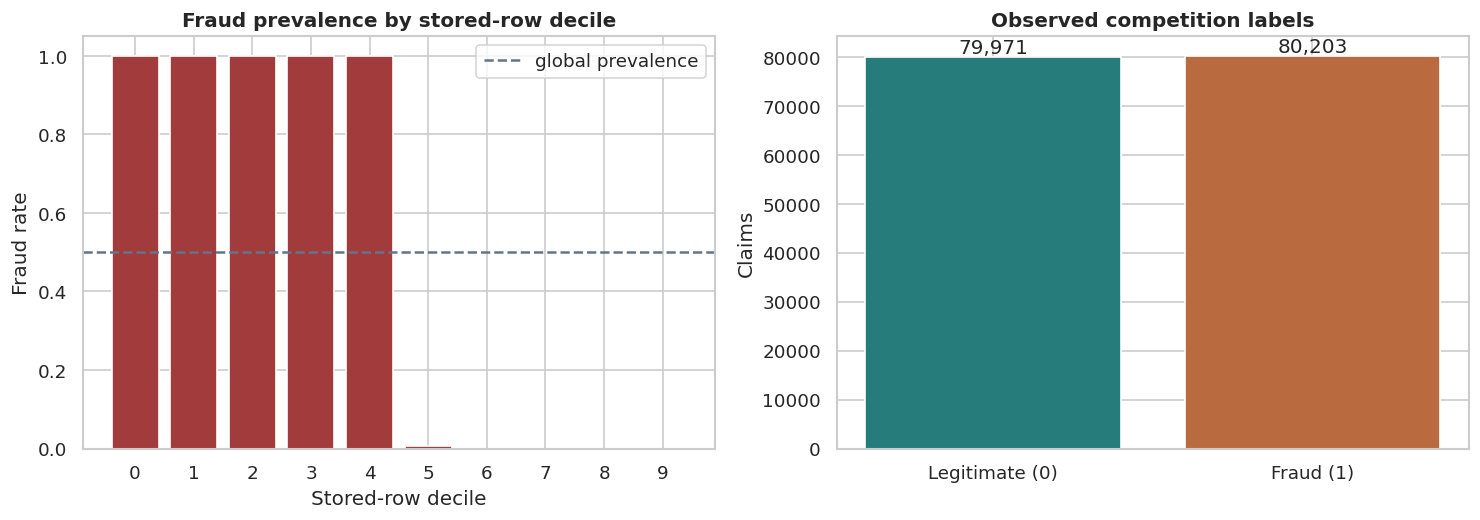

*Figure 4.1. Label balance and the storage-order discontinuity that invalidates source-row tie breaking.*

**Table 4.5. Constant-score sensitivity to tie policy**

,tie_policy,fraud_captured,NormalizedRecall@5%
0,source-row stable (V1 defect),8008.0000,1.0000
1,claim_id neutral (V2),4045.0000,0.5051
2,tie expectation,4009.7995,0.5007


**Question.** What data-integrity facts most affect valid modeling?

**Method.** Schema, uniqueness, missingness, plausibility, exact/reduced templates, semantic-code formatting, and source-order labels were audited before modeling.

**Result.** Train contains 160,174 claims and test 40,043. Missing cells total 0. 17,906 train rows belong to repeated exact-feature signatures, including 1,737 conflicting signature groups. There are 0 exact train–test signature matches. Labels have 1 stored-order transition; 46,210 kdkc and 160,174 dati2 values begin with zero.

**Decision implication.** Exact signatures must remain grouped, administrative codes must remain strings, row order cannot be a feature or tie key, and implausible extremes are flagged rather than automatically discarded.

**Limitation / alternative explanation.** The organizer has not supplied a data dictionary or label-adjudication history. Plausibility flags identify review needs, not proven errors.

In [20]:
SCHEMA_SUMMARY = pd.DataFrame([
    {"role":"labeled train", "rows":len(train_raw), "columns":train_raw.shape[1], "identifier_unique":not train_raw[ID_COL].duplicated().any()},
    {"role":"evaluation test", "rows":len(test_raw), "columns":test_raw.shape[1], "identifier_unique":not test_raw[ID_COL].duplicated().any()},
    {"role":"sample submission", "rows":len(sample_submission), "columns":sample_submission.shape[1], "identifier_unique":not sample_submission[ID_COL].duplicated().any()},
])
show_table(SCHEMA_SUMMARY, "4.1", "Dataset contract and identifier integrity")
show_table(DUPLICATE_SUMMARY, "4.2", "Duplicate, template, and train–test overlap audit")
show_table(PLAUSIBILITY, "4.3", "Domain plausibility flags requiring interpretation rather than silent deletion")
show_table(CARDINALITY.head(15), "4.4", "Highest-cardinality and rare-level fields")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].bar(SOURCE_ORDER_PROFILE.row_decile.astype(str), SOURCE_ORDER_PROFILE.fraud_rate, color=COLORS["red"])
axes[0].axhline(y.mean(), color=COLORS["gray"], linestyle="--", label="global prevalence")
axes[0].set(title="Fraud prevalence by stored-row decile", xlabel="Stored-row decile", ylabel="Fraud rate", ylim=(0, 1.05))
axes[0].legend()
label_counts = pd.Series(y).value_counts().sort_index()
axes[1].bar(["Legitimate (0)", "Fraud (1)"], label_counts.values, color=[COLORS["teal"], COLORS["orange"]])
axes[1].set(title="Observed competition labels", ylabel="Claims")
for i, value in enumerate(label_counts.values): axes[1].text(i, value, f"{value:,}", ha="center", va="bottom")
finish_figure(fig, "4.1", "Label balance and the storage-order discontinuity that invalidates source-row tie breaking.")

show_table(SOURCE_ORDER_AUDIT, "4.5", "Constant-score sensitivity to tie policy")
report_block(
    "What data-integrity facts most affect valid modeling?",
    "Schema, uniqueness, missingness, plausibility, exact/reduced templates, semantic-code formatting, and source-order labels were audited before modeling.",
    f"Train contains {len(train_raw):,} claims and test {len(test_raw):,}. Missing cells total {REPORT_FACTS['missing_cells']:,}. "
    f"{REPORT_FACTS['repeated_signature_rows']:,} train rows belong to repeated exact-feature signatures, including {REPORT_FACTS['conflicting_signatures']:,} conflicting signature groups. "
    f"There are {REPORT_FACTS['test_signature_overlap']:,} exact train–test signature matches. Labels have {REPORT_FACTS['label_transitions']} stored-order transition; "
    f"{REPORT_FACTS['leading_zero_kdkc']:,} kdkc and {REPORT_FACTS['leading_zero_dati2']:,} dati2 values begin with zero.",
    "Exact signatures must remain grouped, administrative codes must remain strings, row order cannot be a feature or tie key, and implausible extremes are flagged rather than automatically discarded.",
    "The organizer has not supplied a data dictionary or label-adjudication history. Plausibility flags identify review needs, not proven errors."
)


## 4.2 Fraud Patterns, Subgroups, and Association Limits


**Table 4.6. Strongest categorical associations after rare-level pooling**

,feature,p_value,Cramers_V,levels,p_bh
1,dati2,0.0000,0.2983,452,0.0000
0,kdkc,0.0000,0.2509,126,0.0000
2,typeppk,0.0000,0.1229,25,0.0000
5,cmg,0.0000,0.1122,23,0.0000
6,severitylevel,0.0000,0.0777,4,0.0000
4,jnspelsep,0.0000,0.0533,2,0.0000
7,diagprimer,0.0000,0.0194,21,0.0000
3,jkpst,0.0000,0.0114,2,0.0000


**Table 4.7. Strongest numeric distribution differences**

,feature,p_value,abs_rank_biserial,signed_rank_biserial,KS,fraud_median,legitimate_median,p_bh
1,los,0.0000,0.0757,-0.0757,0.0805,0.0000,0.0000,0.0000
38,proc80_99,0.0000,0.0338,-0.0338,0.0285,0.0000,0.0000,0.0000
0,umur,0.0000,0.0177,0.0177,0.0153,39.0000,38.0000,0.0000
28,proc39_45,0.0000,0.0115,-0.0115,0.0115,0.0000,0.0000,0.0000
35,proc74_75,0.0000,0.0102,-0.0102,0.0102,0.0000,0.0000,0.0000
21,dx2_z00_z99,0.0000,0.0100,-0.0100,0.0100,0.0000,0.0000,0.0000
5,dx2_e00_e90,0.0000,0.0070,-0.0070,0.0069,0.0000,0.0000,0.0000
10,dx2_i00_i99,0.0000,0.0066,-0.0066,0.0066,0.0000,0.0000,0.0000
16,dx2_p00_p96,0.0000,0.0058,-0.0058,0.0058,0.0000,0.0000,0.0000
14,dx2_n00_n99,0.0000,0.0055,0.0055,0.0055,0.0000,0.0000,0.0000


**Table 4.8. Largest observed categorical fraud-rate deviations with at least 100 claims**

,level,claims,frauds,fraud_rate,feature,abs_rate_difference
485,0364,179,173,0.9665,dati2,0.4658
125,2606,215,201,0.9349,kdkc,0.4342
163,0039,159,13,0.0818,dati2,0.4190
617,HD,114,11,0.0965,typeppk,0.4042
526,0410,136,123,0.9044,dati2,0.4037
224,0102,204,21,0.1029,dati2,0.3978
349,0227,413,56,0.1356,dati2,0.3651
229,0107,450,65,0.1444,dati2,0.3563
352,0230,180,27,0.1500,dati2,0.3507
177,0053,616,522,0.8474,dati2,0.3467


**Table 4.9. Observed fraud prevalence by protected evaluation group**

,group,claims,frauds,fraud_rate,attribute
0,L,74284,37650,0.5068,gender
1,P,85890,42553,0.4954,gender
2,0–17,40125,19765,0.4926,age_group
3,18–39,41391,20605,0.4978,age_group
4,40–59,47844,24021,0.5021,age_group
5,60+,30814,15812,0.5131,age_group


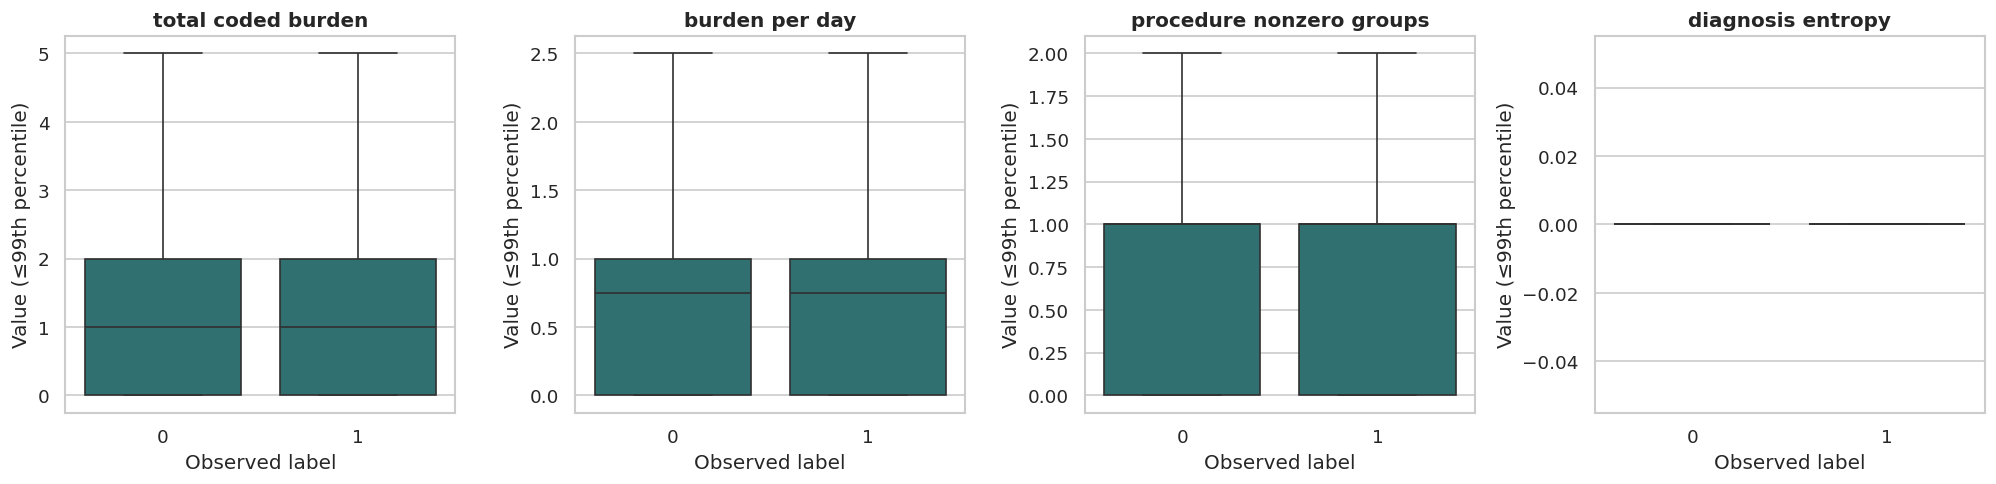

*Figure 4.2. Selected burden, density, and concentration features by observed label; differences are associative.*

**Question.** Which supplied fields are associated with observed fraud?

**Method.** Multiplicity-adjusted categorical and numeric screens were paired with effect sizes, level counts, subgroup rates, and robust visual summaries.

**Result.** The strongest categorical effect is `dati2`; the strongest numeric rank-biserial effect is `los`. Tables 4.6–4.9 retain counts so large-sample significance is not mistaken for operational importance.

**Decision implication.** The effects guide feature hypotheses and investigator questions; prediction and held-out ablation determine whether they generalize.

**Limitation / alternative explanation.** Claims are observational and labels may reflect prior investigation or sampling. No table establishes clinical or behavioral causality.

In [21]:
show_table(CATEGORICAL_ASSOCIATIONS.head(12), "4.6", "Strongest categorical associations after rare-level pooling")
show_table(NUMERIC_ASSOCIATIONS.head(12), "4.7", "Strongest numeric distribution differences")
show_table(CATEGORY_LEVEL_RATES[CATEGORY_LEVEL_RATES.claims >= 100].head(20), "4.8", "Largest observed categorical fraud-rate deviations with at least 100 claims")

SUBGROUP_FRAUD = pd.concat([
    pd.DataFrame({"group":PROTECTED.gender.astype("string"), "label":y}).groupby("group").label.agg(claims="size", frauds="sum", fraud_rate="mean").reset_index().assign(attribute="gender"),
    pd.DataFrame({"group":age_groups(PROTECTED.age), "label":y}).groupby("group").label.agg(claims="size", frauds="sum", fraud_rate="mean").reset_index().assign(attribute="age_group"),
], ignore_index=True)
show_table(SUBGROUP_FRAUD, "4.9", "Observed fraud prevalence by protected evaluation group")

plot_features = [c for c in ["total_coded_burden", "burden_per_day", "procedure_nonzero_groups", "diagnosis_entropy"] if c in train_model]
fig, axes = plt.subplots(1, len(plot_features), figsize=(4.2 * len(plot_features), 4.2))
axes = np.atleast_1d(axes)
for ax, feature in zip(axes, plot_features):
    clipped = train_model[feature].clip(upper=train_model[feature].quantile(0.99))
    sns.boxplot(x=y, y=clipped, ax=ax, color=COLORS["teal"], showfliers=False)
    ax.set(title=feature.replace("_", " "), xlabel="Observed label", ylabel="Value (≤99th percentile)")
finish_figure(fig, "4.2", "Selected burden, density, and concentration features by observed label; differences are associative.")

top_cat = CATEGORICAL_ASSOCIATIONS.iloc[0].feature if len(CATEGORICAL_ASSOCIATIONS) else "none"
top_num = NUMERIC_ASSOCIATIONS.iloc[0].feature if len(NUMERIC_ASSOCIATIONS) else "none"
report_block(
    "Which supplied fields are associated with observed fraud?",
    "Multiplicity-adjusted categorical and numeric screens were paired with effect sizes, level counts, subgroup rates, and robust visual summaries.",
    f"The strongest categorical effect is `{top_cat}`; the strongest numeric rank-biserial effect is `{top_num}`. Tables 4.6–4.9 retain counts so large-sample significance is not mistaken for operational importance.",
    "The effects guide feature hypotheses and investigator questions; prediction and held-out ablation determine whether they generalize.",
    "Claims are observational and labels may reflect prior investigation or sampling. No table establishes clinical or behavioral causality."
)


## 4.3 Leakage, Identifier, and Proxy Assessment


In [22]:
show_table(LEAKAGE_REGISTER, "4.10", "Feature-role and leakage decision register")
show_table(UNIVARIATE_AUDIT.head(15), "4.11", "Strongest fold-safe single-feature ranking signals")

report_block(
    "Did V2 identify leakage or proxy risks?",
    "Semantic availability was combined with fold-safe univariate AP, uniqueness, storage-order analysis, duplicate grouping, and later ablations.",
    f"`claim_id` and source position are excluded. The suspicious-signal rule identified {len(SUSPICIOUS_SIGNAL_FEATURES)} raw feature(s): "
    f"{', '.join(SUSPICIOUS_SIGNAL_FEATURES) if SUSPICIOUS_SIGNAL_FEATURES else 'none'}. Location variables remain explicitly classified as structural proxies.",
    "Strong location signal is retained for the competition only after shift and fairness checks, while deployment beyond represented locations requires the stress evidence and process review.",
    "High AP alone does not prove leakage. A conclusive determination would require field provenance, capture time, and label-generation documentation."
)


**Table 4.10. Feature-role and leakage decision register**

,feature_set,classification,decision,rationale
0,claim_id,identifier,excluded from prediction; neutral tie key only,unique alignment field
1,source row position,storage-order leakage,excluded everywhere,only 1 label transition(s); V1 stable ties were invalid
2,"dx2_koo_k93, dx2_u00_u99, procv00_v89, missing_field_count",non-informative,excluded,constant after cleaning/engineering
3,"jkpst, umur, age_band, is_pediatric, is_older_adult, age_x_log_los",protected or sensitive,"retain, score fairly, screen removal",may encode case mix and direct demographic signal
4,"kdkc, dati2, kdkc_prefix2, dati2_prefix2, geo__facility, kdkc__dati2",structural proxy,retain for competition; location stress test,"V1 importance and removal evidence are large, but transportability is weaker"
5,none,empirically suspicious,semantic review and importance cross-check,extreme fold-safe univariate AP if present
6,diagnosis/procedure/service/stay fields,claim information,retained,available at scoring; predictive association is not causality


**Table 4.11. Strongest fold-safe single-feature ranking signals**

,feature,univariate_oof_AP,uniqueness_ratio
1,dati2,0.6546,0.0030
0,kdkc,0.6276,0.0008
2,typeppk,0.5525,0.0002
7,cmg,0.5426,0.0001
8,severitylevel,0.5218,0.0000
6,los,0.5213,0.0008
5,jnspelsep,0.5147,0.0000
48,proc80_99,0.5106,0.0001
4,umur,0.5071,0.0007
3,jkpst,0.5039,0.0000


**Question.** Did V2 identify leakage or proxy risks?

**Method.** Semantic availability was combined with fold-safe univariate AP, uniqueness, storage-order analysis, duplicate grouping, and later ablations.

**Result.** `claim_id` and source position are excluded. The suspicious-signal rule identified 0 raw feature(s): none. Location variables remain explicitly classified as structural proxies.

**Decision implication.** Strong location signal is retained for the competition only after shift and fairness checks, while deployment beyond represented locations requires the stress evidence and process review.

**Limitation / alternative explanation.** High AP alone does not prove leakage. A conclusive determination would require field provenance, capture time, and label-generation documentation.

## 4.4 Train–Test Distribution Assessment


**Table 4.12. Largest train–test feature distribution differences**

,feature,type,KS,abs_SMD,JS_divergence,unseen_test_levels,shift_magnitude
38,proc39_45,numeric,0.0018,0.0133,—,—,0.0133
17,dx2_h60_h95,numeric,0.0010,0.0126,—,—,0.0126
18,dx2_i00_i99,numeric,0.0021,0.0111,—,—,0.0111
46,proc76_77,numeric,0.0004,0.0108,—,—,0.0108
34,proc24_27,numeric,0.0006,0.0103,—,—,0.0103
39,proc46_51,numeric,0.0006,0.0103,—,—,0.0103
42,proc63_67,numeric,0.0008,0.0099,—,—,0.0099
35,proc28_28,numeric,0.0002,0.0094,—,—,0.0094
26,dx2_q00_q99,numeric,0.0003,0.0089,—,—,0.0089
36,proc29_31,numeric,0.0003,0.0073,—,—,0.0073


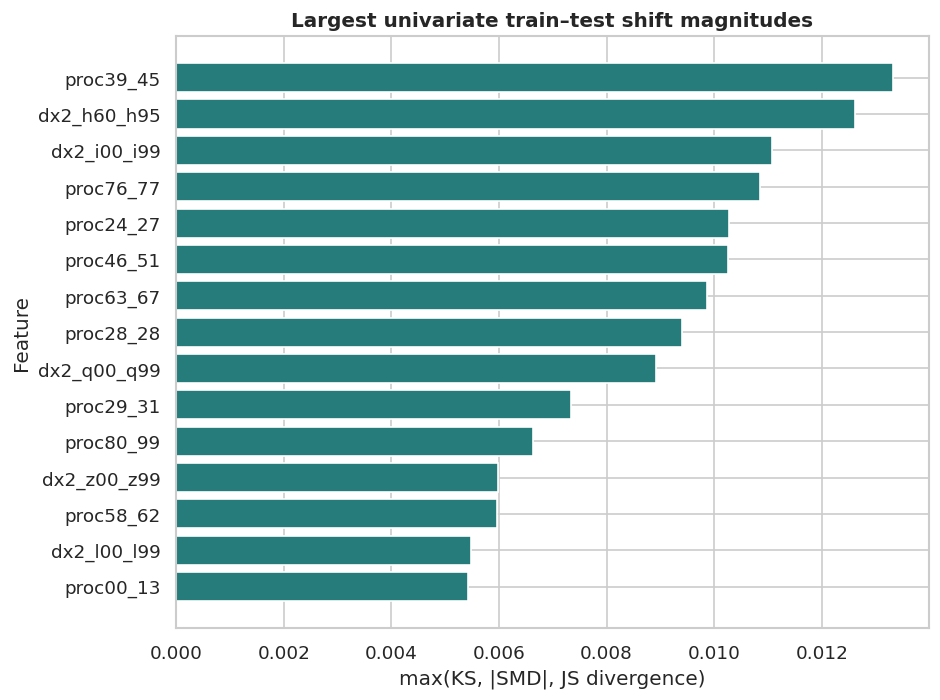

*Figure 4.3. Univariate covariate-shift screen; it contains no evaluation labels.*

**Question.** Does the evaluation sample differ materially from train?

**Method.** Numeric KS and |SMD|, categorical Jensen–Shannon divergence/unseen levels, and cross-validated adversarial classification were evaluated.

**Result.** Adversarial AUC is **0.5068**. The largest univariate shift is `proc39_45` at **0.0133**; the total unseen categorical level count is **0**.

**Decision implication.** Near-chance adversarial AUC and small shifts support primary grouped CV as the Kaggle-selection view; any important shifted feature is still cross-referenced after fitting.

**Limitation / alternative explanation.** Covariate similarity cannot establish equal hidden outcome prevalence or concept stability.

In [23]:
show_table(SHIFT_TABLE.head(15), "4.12", "Largest train–test feature distribution differences")
shift_plot = SHIFT_TABLE.head(15).sort_values("shift_magnitude")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(shift_plot.feature, shift_plot.shift_magnitude, color=COLORS["teal"])
ax.set(title="Largest univariate train–test shift magnitudes", xlabel="max(KS, |SMD|, JS divergence)", ylabel="Feature")
finish_figure(fig, "4.3", "Univariate covariate-shift screen; it contains no evaluation labels.")

largest_shift = SHIFT_TABLE.iloc[0]
report_block(
    "Does the evaluation sample differ materially from train?",
    "Numeric KS and |SMD|, categorical Jensen–Shannon divergence/unseen levels, and cross-validated adversarial classification were evaluated.",
    f"Adversarial AUC is **{ADVERSARIAL_AUC:.4f}**. The largest univariate shift is `{largest_shift.feature}` at **{largest_shift.shift_magnitude:.4f}**; "
    f"the total unseen categorical level count is **{int(SHIFT_TABLE.unseen_test_levels.fillna(0).sum())}**.",
    "Near-chance adversarial AUC and small shifts support primary grouped CV as the Kaggle-selection view; any important shifted feature is still cross-referenced after fitting.",
    "Covariate similarity cannot establish equal hidden outcome prevalence or concept stability."
)


## 4.5 Validation Design and Source-Order Correction


**Table 4.13. Primary fold sizes, prevalence, and exact-signature separation**

,fold,train_n,valid_n,train_fraud_rate,valid_fraud_rate,signature_overlap,role
0,1,128102,32072,0.5007,0.5010,0,selection
1,2,128179,31995,0.5001,0.5032,0,selection
2,3,128176,31998,0.5000,0.5038,0,selection
3,4,128207,31967,0.5008,0.5004,0,confirmation
4,5,128032,32142,0.5021,0.4953,0,confirmation


**Table 4.14. Top-5 constant-score results under alternative tie policies**

,tie_policy,fraud_captured,NormalizedRecall@5%
0,source-row stable (V1 defect),8008.0000,1.0000
1,claim_id neutral (V2),4045.0000,0.5051
2,tie expectation,4009.7995,0.5007


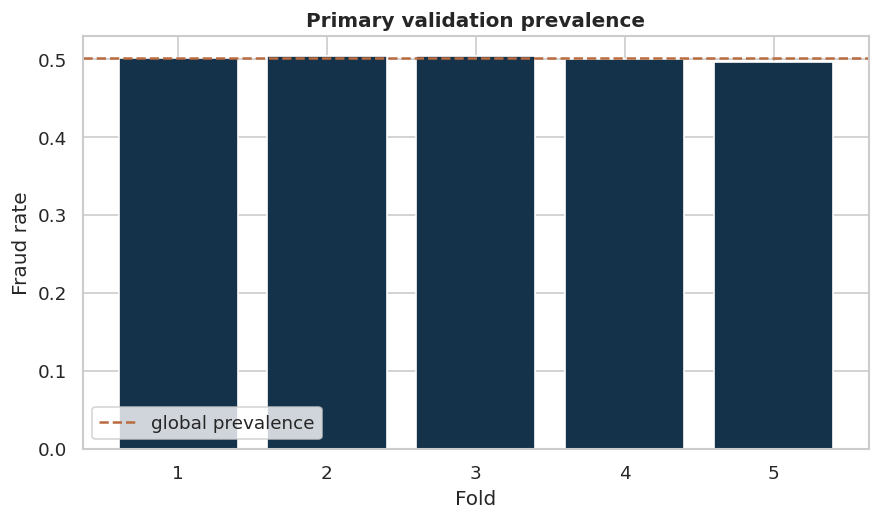

*Figure 4.4. Stratified grouped folds retain prevalence while separating exact feature signatures.*

**Question.** Which validation perspective is defensible?

**Method.** Five-fold stratified group CV is primary; ordinary stratification is an overlap diagnostic; a kdkc-held-out split is a later transport stress test.

**Result.** Primary folds have zero signature overlap and fold prevalence ranges from 49.530% to 50.378%. Ordinary folds would repeat 13,092 signature groups across train and validation. The source-order constant score falls from the flawed result shown in Table 4.14 to a tie-neutral result near prevalence.

**Decision implication.** All model, calibration, and blend decisions use this common primary CV; location stress is interpreted separately.

**Limitation / alternative explanation.** No split can reproduce unknown private-label construction. Grouping exact signatures addresses verified repetition but not every latent provider or temporal dependency.

In [24]:
show_table(VALIDATION_TABLE, "4.13", "Primary fold sizes, prevalence, and exact-signature separation")
show_table(SOURCE_ORDER_AUDIT, "4.14", "Top-5 constant-score results under alternative tie policies")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(VALIDATION_TABLE.fold.astype(str), VALIDATION_TABLE.valid_fraud_rate, color=COLORS["navy"])
ax.axhline(y.mean(), color=COLORS["orange"], linestyle="--", label="global prevalence")
ax.set(title="Primary validation prevalence", xlabel="Fold", ylabel="Fraud rate")
ax.legend()
finish_figure(fig, "4.4", "Stratified grouped folds retain prevalence while separating exact feature signatures.")

report_block(
    "Which validation perspective is defensible?",
    "Five-fold stratified group CV is primary; ordinary stratification is an overlap diagnostic; a kdkc-held-out split is a later transport stress test.",
    f"Primary folds have zero signature overlap and fold prevalence ranges from {VALIDATION_TABLE.valid_fraud_rate.min():.3%} to {VALIDATION_TABLE.valid_fraud_rate.max():.3%}. "
    f"Ordinary folds would repeat {ordinary_overlap:,} signature groups across train and validation. The source-order constant score falls from the flawed result shown in Table 4.14 to a tie-neutral result near prevalence.",
    "All model, calibration, and blend decisions use this common primary CV; location stress is interpreted separately.",
    "No split can reproduce unknown private-label construction. Grouping exact signatures addresses verified repetition but not every latent provider or temporal dependency."
)


## 4.6 V1 Reassessment and OOF Error Analysis

False positives are legitimate claims inside the 5% portfolio. Missed fraud includes all fraud outside it; near-boundary fraud is the more actionable subset ranked from $K$ through $K+0.02N$. Contrasts are descriptive hypotheses, not prescriptions for row-level score edits.


**Table 4.15. Verified, plausible, rejected, and unknown V1 claims**

,ID,status,evidence or hypothesis,V2 consequence
0,F01,VERIFIED,Labels form one fraud block then one legitimate block; only one transition.,source-order tie breaking is invalid
1,F02,VERIFIED,Stable V1 ties made a constant baseline NR@5%=1.0 and burden NR@3%=1.0.,correct the shared top-k function and report tie ranges
2,F03,VERIFIED,"V1 CatBoost raw OOF: NR@5%=0.970155, AP=0.823402, Brier=0.172186.","strong anchor, not proof of optimality"
3,F04,VERIFIED,V1 fixed Cat/XGB probability blends near 0.80 Cat improved all three raw components in artifact reanalysis.,test fixed deployable blends under corrected CV
4,F05,VERIFIED,"Alternate Cat seed was highly correlated yet a two-seed mean improved boundary capture, AP, and Brier.",evaluate a V2 seed ensemble
5,F06,VERIFIED,Full-refit and fold-average V1 test scores had Spearman≈0.994 but only 91.66% top-5 overlap (167 swaps per side).,treat inference strategy as real portfolio uncertainty
6,F07,VERIFIED,Location-feature removal reduced V1 OOF Technical Score by about 0.095; unseen-kdkc stress score was about 0.752.,retain for Kaggle but surface transport risk
7,F08,VERIFIED,"All five V1 CatBoost folds stopped at 2,195–2,200 of 2,200 iterations.",test longer/regularized capacity rather than assume convergence
8,F09,VERIFIED,V1 XGBoost represented categories with arbitrary ordinal numbers.,replace with fold-fitted one-hot representation
9,F10,PLAUSIBLE,"The public gap may reflect ranking, validation, calibration, ensemble, or refit variance.",public score cannot identify affected claims


**Table 4.16. Corrected V1-like OOF error-cohort sizes**

,error cohort,claims
0,V1 top-5 legitimate claims,385
1,V1 fraud outside top 5%,72580
2,V1 fraud in ranks K through K+2%N,2840


**Table 4.17. Largest numeric contrasts in V1 OOF error cohorts**

,comparison,feature,abs_SMD,mean_group_A,mean_group_B,n_group_A,n_group_B
0,V1 false positives vs other legitimate,burden_per_day,0.3981,1.3308,0.8331,385,79586
1,V1 false positives vs other legitimate,procedure_per_day,0.3597,0.9569,0.5837,385,79586
2,V1 false positives vs other legitimate,log1p_los,0.3089,0.2983,0.5087,385,79586
3,V1 false positives vs other legitimate,los,0.2294,0.7039,1.5398,385,79586
4,V1 false positives vs other legitimate,diagnosis_per_day,0.2274,0.3739,0.2494,385,79586
5,V1 false positives vs other legitimate,zero_los,0.2231,0.7506,0.6490,385,79586
6,V1 false positives vs other legitimate,total_nonzero_groups,0.2195,1.3143,1.0626,385,79586
7,V1 false positives vs other legitimate,proc39_45,0.2129,0.0000,0.0235,385,79586
15,V1 missed fraud vs captured fraud,procedure_per_day,0.6049,0.5573,1.1504,72580,7623
16,V1 missed fraud vs captured fraud,burden_per_day,0.5730,0.8073,1.4819,72580,7623


**Table 4.17b. Largest categorical level-enrichment contrasts in V1 OOF error cohorts**

,comparison,feature,level,share_group_A,share_group_B,absolute_share_delta,n_group_A,n_group_B
0,V1 false positives vs other legitimate,dati2_prefix2,01,0.2052,0.4587,0.2535,385,79586
1,V1 false positives vs other legitimate,typeppk,SC,0.0961,0.2788,0.1827,385,79586
2,V1 false positives vs other legitimate,cmg,H,0.1844,0.0275,0.1569,385,79586
3,V1 false positives vs other legitimate,cmg__severity,H__0,0.1792,0.0239,0.1553,385,79586
4,V1 false positives vs other legitimate,service__facility,2__SC,0.0468,0.1896,0.1428,385,79586
5,V1 false positives vs other legitimate,diagnosis__cmg,h00_h59__H,0.1584,0.0205,0.1379,385,79586
6,V1 false positives vs other legitimate,severitylevel,1,0.1377,0.2751,0.1374,385,79586
7,V1 false positives vs other legitimate,cmg__facility,H__KM,0.1247,0.0081,0.1166,385,79586
8,V1 false positives vs other legitimate,diagprimer,h00_h59,0.1584,0.0485,0.1100,385,79586
9,V1 false positives vs other legitimate,diagnosis__service,h00_h59__2,0.1532,0.0463,0.1070,385,79586


**Table 4.18. Corrected V1-like anchor and CatBoost V2 seed 2127 top-5 disagreement**

,portfolio relation,claims
0,both selected,5964
1,V1 only selected,2044
2,CatBoost V2 seed 2127 only selected,2044
3,CatBoost V2 seed 2127-only fraud recovery,1957
4,V1-only fraud recovery,1808


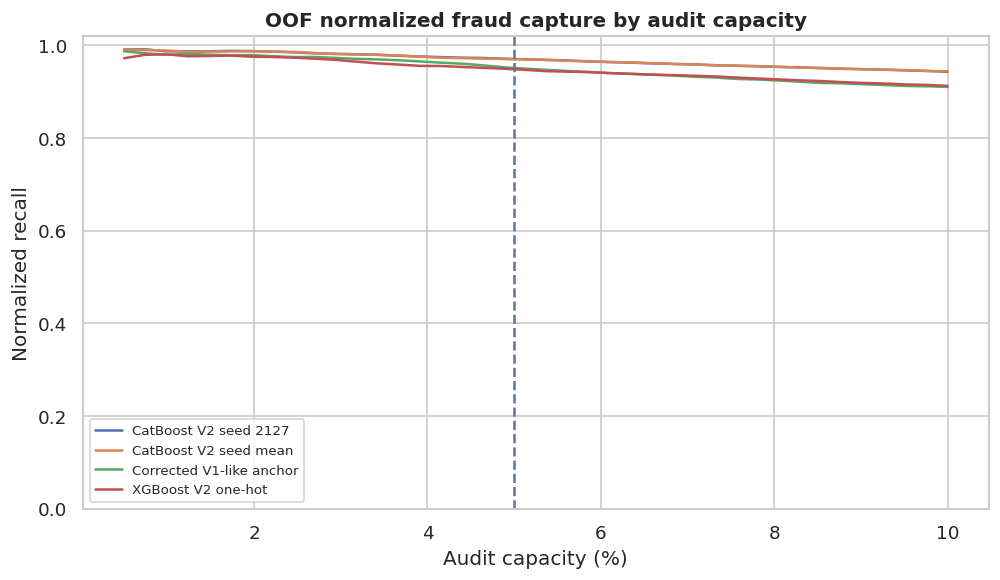

*Figure 4.5. Cumulative OOF capture around the official 5% audit boundary.*

**Question.** What did V1 miss, and which hypothesis follows?

**Method.** Tie-neutral corrected V1-like OOF ranks define false-positive, missed-fraud, near-boundary, and selected-model recovery cohorts; numeric and categorical contrasts identify recurring structures.

**Result.** The corrected V1-like anchor places 385 legitimate claims in the top 5%. The near-boundary window contains 2,840 fraud claims. CatBoost V2 seed 2127 uniquely recovers 1,957 fraud claims while the anchor uniquely recovers 1,808.

**Decision implication.** Observed procedure/diagnosis burden, density, severity, and location differences motivate limited V2 features and fixed blends; the rows themselves are never manually edited.

**Limitation / alternative explanation.** OOF labels support error analysis, but cohort contrasts can combine model error with genuine overlap in claim patterns and conflicting labels.

In [25]:
show_table(V1_FORENSICS, "4.15", "Verified, plausible, rejected, and unknown V1 claims")

v1_raw = CANDIDATES["Corrected V1-like anchor"]["raw_oof"]
v1_order = np.lexsort((TIE_KEYS, -v1_raw))
v1_rank = np.empty(len(y), dtype=int); v1_rank[v1_order] = np.arange(len(y))
k = int(np.floor(0.05 * len(y)))
v1_selected = np.zeros(len(y), dtype=bool); v1_selected[v1_order[:k]] = True
near_boundary = (y == 1) & (v1_rank >= k) & (v1_rank < k + int(0.02 * len(y)))

error_numeric = [c for c in V2_FEATURE_COLUMNS if c not in CATEGORICAL_COLUMNS]
def standardized_contrasts(mask_a, mask_b, comparison, limit=15):
    frame = train_model[error_numeric].apply(pd.to_numeric, errors="coerce")
    mean_a, mean_b = frame.loc[mask_a].mean(), frame.loc[mask_b].mean()
    pooled = np.sqrt((frame.loc[mask_a].var() + frame.loc[mask_b].var()) / 2).replace(0, np.nan)
    effect = ((mean_a - mean_b) / pooled).abs().sort_values(ascending=False).head(limit)
    return pd.DataFrame({
        "comparison":comparison, "feature":effect.index, "abs_SMD":effect.values,
        "mean_group_A":mean_a[effect.index].values, "mean_group_B":mean_b[effect.index].values,
        "n_group_A":int(mask_a.sum()), "n_group_B":int(mask_b.sum()),
    })

ERROR_CONTRASTS = pd.concat([
    standardized_contrasts((y == 0) & v1_selected, (y == 0) & ~v1_selected, "V1 false positives vs other legitimate"),
    standardized_contrasts((y == 1) & ~v1_selected, (y == 1) & v1_selected, "V1 missed fraud vs captured fraud"),
    standardized_contrasts(near_boundary, (y == 1) & v1_selected, "V1 near-boundary fraud vs captured fraud"),
], ignore_index=True)


def categorical_cohort_enrichment(mask_a, mask_b, comparison, limit=10):
    rows = []
    for feature in CATEGORICAL_COLUMNS:
        a = train_model.loc[mask_a, feature].astype("string").fillna("Missing")
        b = train_model.loc[mask_b, feature].astype("string").fillna("Missing")
        levels = sorted(set(a.unique()) | set(b.unique()))
        pa = a.value_counts(normalize=True).reindex(levels, fill_value=0)
        pb = b.value_counts(normalize=True).reindex(levels, fill_value=0)
        if len(levels):
            level = (pa - pb).abs().idxmax()
            rows.append({
                "comparison":comparison, "feature":feature, "level":str(level),
                "share_group_A":float(pa[level]), "share_group_B":float(pb[level]),
                "absolute_share_delta":float(abs(pa[level] - pb[level])),
                "n_group_A":int(mask_a.sum()), "n_group_B":int(mask_b.sum()),
            })
    return pd.DataFrame(rows).nlargest(limit, "absolute_share_delta")


CATEGORICAL_ERROR_COHORTS = pd.concat([
    categorical_cohort_enrichment((y == 0) & v1_selected, (y == 0) & ~v1_selected, "V1 false positives vs other legitimate"),
    categorical_cohort_enrichment((y == 1) & ~v1_selected, (y == 1) & v1_selected, "V1 missed fraud vs captured fraud"),
], ignore_index=True)

ERROR_COUNTS = pd.DataFrame([
    ("V1 top-5 legitimate claims", int(((y == 0) & v1_selected).sum())),
    ("V1 fraud outside top 5%", int(((y == 1) & ~v1_selected).sum())),
    ("V1 fraud in ranks K through K+2%N", int(near_boundary.sum())),
], columns=["error cohort", "claims"])
show_table(ERROR_COUNTS, "4.16", "Corrected V1-like OOF error-cohort sizes")
show_table(ERROR_CONTRASTS.groupby("comparison").head(8), "4.17", "Largest numeric contrasts in V1 OOF error cohorts")
show_table(CATEGORICAL_ERROR_COHORTS, "4.17b", "Largest categorical level-enrichment contrasts in V1 OOF error cohorts")

comparison_name = FINAL_CHOICE
comparison_raw = CANDIDATES[comparison_name]["raw_oof"]
comparison_selected = top_k_mask(comparison_raw, 0.05, tie_key=TIE_KEYS)
DISAGREEMENT_COUNTS = pd.DataFrame([
    ("both selected", int((v1_selected & comparison_selected).sum())),
    ("V1 only selected", int((v1_selected & ~comparison_selected).sum())),
    (f"{comparison_name} only selected", int((~v1_selected & comparison_selected).sum())),
    (f"{comparison_name}-only fraud recovery", int(((y == 1) & ~v1_selected & comparison_selected).sum())),
    ("V1-only fraud recovery", int(((y == 1) & v1_selected & ~comparison_selected).sum())),
], columns=["portfolio relation", "claims"])
show_table(DISAGREEMENT_COUNTS, "4.18", f"Corrected V1-like anchor and {comparison_name} top-5 disagreement")

capacities = np.linspace(0.005, 0.10, 40)
gain_rows = []
for name in ["Corrected V1-like anchor", "CatBoost V2 seed mean", "XGBoost V2 one-hot", FINAL_CHOICE]:
    if name not in CANDIDATES: continue
    prediction = CANDIDATES[name]["raw_oof"]
    for capacity in capacities:
        metric = official_metrics(y, prediction, PROTECTED, capacity, tie_key=TIE_KEYS)
        gain_rows.append({"candidate":name, "capacity":capacity, "normalized_recall":metric["NormalizedRecall@capacity"]})
CUMULATIVE_GAIN = pd.DataFrame(gain_rows).drop_duplicates()
fig, ax = plt.subplots(figsize=(8.5, 5))
for name, group in CUMULATIVE_GAIN.groupby("candidate"):
    ax.plot(group.capacity * 100, group.normalized_recall, label=name)
ax.axvline(5, color=COLORS["gray"], linestyle="--")
ax.set(title="OOF normalized fraud capture by audit capacity", xlabel="Audit capacity (%)", ylabel="Normalized recall", ylim=(0, 1.02))
ax.legend(fontsize=8)
finish_figure(fig, "4.5", "Cumulative OOF capture around the official 5% audit boundary.")

report_block(
    "What did V1 miss, and which hypothesis follows?",
    "Tie-neutral corrected V1-like OOF ranks define false-positive, missed-fraud, near-boundary, and selected-model recovery cohorts; numeric and categorical contrasts identify recurring structures.",
    f"The corrected V1-like anchor places {int(((y == 0) & v1_selected).sum()):,} legitimate claims in the top 5%. "
    f"The near-boundary window contains {int(near_boundary.sum()):,} fraud claims. {comparison_name} uniquely recovers {int(((y == 1) & ~v1_selected & comparison_selected).sum()):,} fraud claims while the anchor uniquely recovers {int(((y == 1) & v1_selected & ~comparison_selected).sum()):,}.",
    "Observed procedure/diagnosis burden, density, severity, and location differences motivate limited V2 features and fixed blends; the rows themselves are never manually edited.",
    "OOF labels support error analysis, but cohort contrasts can combine model error with genuine overlap in claim patterns and conflicting labels."
)
TABLES.update({"A.error_contrasts":ERROR_CONTRASTS, "A.categorical_error_cohorts":CATEGORICAL_ERROR_COHORTS, "A.disagreement":DISAGREEMENT_COUNTS})


## 4.7 V2 Feature Screen and Model Comparison


**Table 4.19. Two-fold CatBoost capacity/regularization screen**

,configuration,mean_TechnicalScore,mean_NR5,mean_AP,mean_Brier,fold_SD
1,depth8_capacity,0.9205,0.9678,0.8217,0.1736,0.0009
0,depth7_regularized,0.9190,0.9656,0.8206,0.1740,0.0006


**Table 4.20. Corrected common-framework experiment registry**

,experiment_id,model,feature_family,calibration,NormalizedRecall@5%,AveragePrecision,Brier,ProtectionScore,TechnicalScore,fold_SD,boundary_tie_size,pessimistic_NR5,tie_penalty,tie_robust_TechnicalScore,selection_fold_mean,confirmation_fold_mean,robust_score,runtime_minutes,complexity,prebootstrap_eligible,bootstrap_eligible,selected
12,Cat seed mean + LightGBM logit blend w=0.9,ensemble,V2,raw,0.9712,0.8239,0.1719,0.9989,0.9230,0.0017,1,0.9712,0.0000,0.9230,0.9227,0.9230,0.9221,23.8219,3,False,False,False
7,CatBoost V2 seed mean,ensemble,V2,raw,0.9705,0.8239,0.1720,0.9987,0.9226,0.0020,1,0.9705,0.0000,0.9226,0.9219,0.9228,0.9214,20.0000,2,False,False,False
9,Cat seed mean + XGBoost logit blend w=0.9,ensemble,V2,beta,0.9705,0.8237,0.1720,0.9990,0.9226,0.0015,1,0.9705,0.0000,0.9226,0.9220,0.9228,0.9214,22.0274,3,False,False,False
11,Cat seed mean + LightGBM probability blend w=0.9,ensemble,V2,beta,0.9704,0.8238,0.1719,0.9989,0.9226,0.0018,1,0.9704,0.0000,0.9226,0.9223,0.9226,0.9217,23.8219,3,False,False,False
13,Cat seed mean + LightGBM rank blend w=0.9,ensemble,V2,beta,0.9704,0.8238,0.1719,0.9990,0.9226,0.0017,1,0.9704,0.0000,0.9226,0.9225,0.9228,0.9218,23.8219,3,False,False,False
4,CatBoost V2 seed 2127,CatBoost,V2,raw,0.9705,0.8232,0.1724,0.9988,0.9225,0.0027,1,0.9705,0.0000,0.9225,0.9219,0.9237,0.9216,10.0153,1,True,True,True
8,Cat seed mean + XGBoost probability blend w=0.9,ensemble,V2,beta,0.9698,0.8235,0.1720,0.9989,0.9222,0.0015,3,0.9698,0.0000,0.9222,0.9216,0.9226,0.9210,22.0274,3,False,False,False
10,Cat seed mean + XGBoost rank blend w=0.9,ensemble,V2,beta,0.9697,0.8235,0.1720,0.9989,0.9221,0.0015,1,0.9697,0.0000,0.9221,0.9217,0.9226,0.9211,22.0274,3,False,False,False
3,CatBoost V2 seed 2026,CatBoost,V2,raw,0.9680,0.8231,0.1722,0.9989,0.9211,0.0015,1,0.9680,0.0000,0.9211,0.9209,0.9219,0.9207,9.9847,1,False,False,False
6,LightGBM V2 one-hot,LightGBM,V2,sigmoid,0.9587,0.8037,0.1798,0.9980,0.9108,0.0042,1,0.9587,0.0000,0.9108,0.9131,0.9095,0.9126,3.8219,1,False,False,False


**Table 4.21. Corrected V1-like anchor versus automatically selected V2**

,Metric,Corrected V1-like anchor,V2 selected,Delta
0,NormalizedRecall@5%,0.9519,0.9705,0.0186
1,AveragePrecision,0.7899,0.8232,0.0333
2,Brier,0.1858,0.1724,-0.0134
3,ProtectionScore,0.9973,0.9988,0.0015
4,TechnicalScore,0.9034,0.9225,0.0191


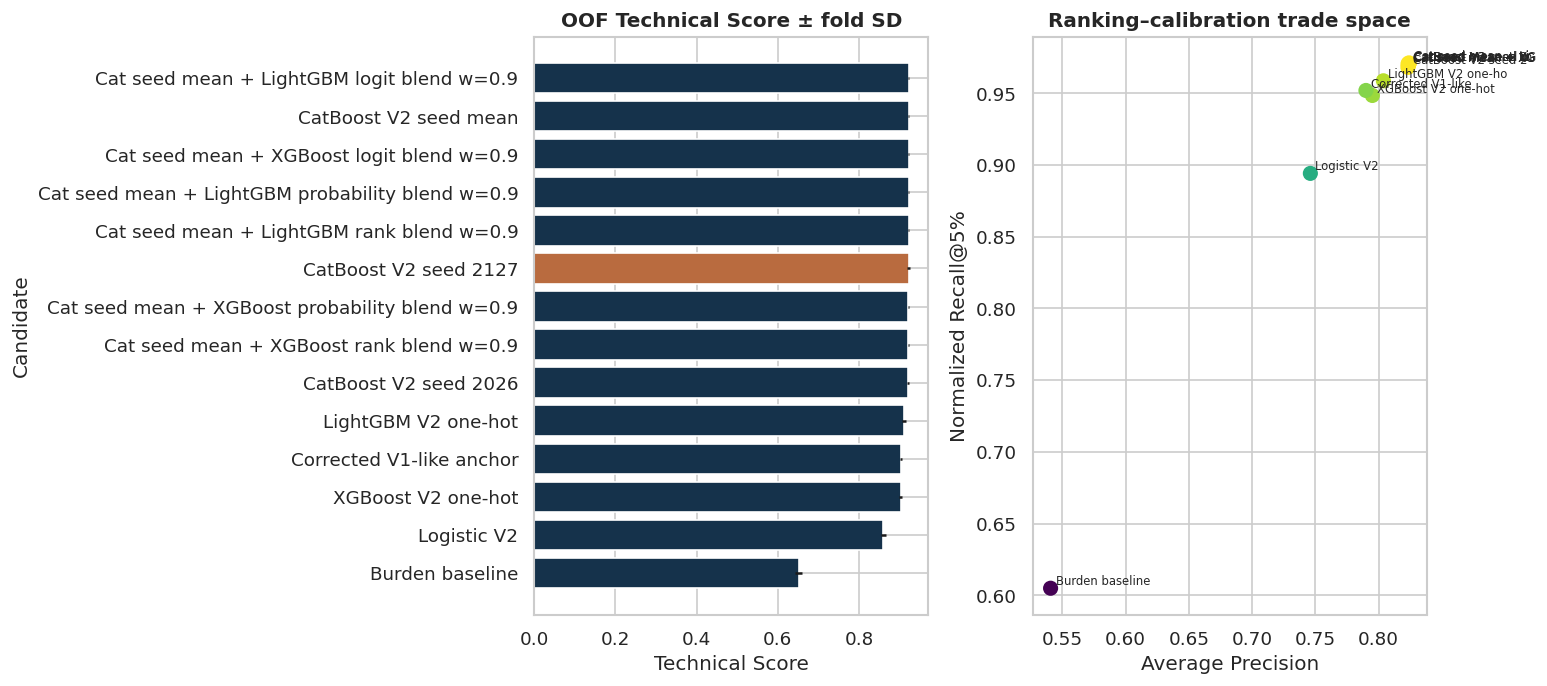

*Figure 4.6. Common-framework model comparison; color on the right represents Brier score.*

**Question.** Did V2 improve the corrected V1-like anchor?

**Method.** Predeclared CatBoost/feature screens and full common-fold CatBoost, XGBoost, LightGBM, seed, and fixed-blend finalists were scored with conditional leave-one-fold-out calibration and fold stability.

**Result.** The selected candidate is **CatBoost V2 seed 2127** with corrected OOF Technical Score **0.92246**, NR@5% **0.97053**, AP **0.82318**, and Brier **0.17238**. Its Technical Score delta from the corrected V1-like anchor is **+0.01905**. The CatBoost screen selected `depth8_capacity`.

**Decision implication.** Only this common-framework OOF delta supports the V1→V2 analytical claim. The public leaderboard score remains context, not a tuning target.

**Limitation / alternative explanation.** These are executed OOF estimates, not private-leaderboard results. Candidate search and shared folds create dependence addressed—but not eliminated—by uncertainty analysis.

In [26]:
show_table(SCREEN_SUMMARY.sort_values("mean_TechnicalScore", ascending=False), "4.19", "Two-fold CatBoost capacity/regularization screen")
comparison_columns = [
    "experiment_id", "model", "feature_family", "calibration", "NormalizedRecall@5%",
    "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore", "fold_SD",
    "boundary_tie_size", "pessimistic_NR5", "tie_penalty", "tie_robust_TechnicalScore",
    "selection_fold_mean", "confirmation_fold_mean", "robust_score",
    "runtime_minutes", "complexity", "prebootstrap_eligible", "bootstrap_eligible", "selected",
]
show_table(EXPERIMENT_REGISTRY.sort_values("TechnicalScore", ascending=False)[comparison_columns], "4.20", "Corrected common-framework experiment registry")

v1_row = EXPERIMENT_REGISTRY[EXPERIMENT_REGISTRY.experiment_id.eq("Corrected V1-like anchor")].iloc[0]
selected_row = EXPERIMENT_REGISTRY[EXPERIMENT_REGISTRY.selected].iloc[0]
V1_V2_COMPARISON = pd.DataFrame([
    {"Metric":metric, "Corrected V1-like anchor":v1_row[metric], "V2 selected":selected_row[metric], "Delta":selected_row[metric] - v1_row[metric]}
    for metric in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]
])
show_table(V1_V2_COMPARISON, "4.21", "Corrected V1-like anchor versus automatically selected V2")

plot = EXPERIMENT_REGISTRY.sort_values("TechnicalScore").copy()
fig, axes = plt.subplots(1, 2, figsize=(13, max(5, 0.42 * len(plot))))
axes[0].barh(plot.experiment_id, plot.TechnicalScore, xerr=plot.fold_SD, color=np.where(plot.selected, COLORS["orange"], COLORS["navy"]))
axes[0].set(title="OOF Technical Score ± fold SD", xlabel="Technical Score", ylabel="Candidate")
axes[1].scatter(plot.AveragePrecision, plot["NormalizedRecall@5%"], c=plot.Brier, cmap="viridis_r", s=65)
for _, row in plot.iterrows(): axes[1].annotate(row.experiment_id[:18], (row.AveragePrecision, row["NormalizedRecall@5%"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
axes[1].set(title="Ranking–calibration trade space", xlabel="Average Precision", ylabel="Normalized Recall@5%")
finish_figure(fig, "4.6", "Common-framework model comparison; color on the right represents Brier score.")

screen_best = SCREEN_SUMMARY.sort_values("mean_TechnicalScore", ascending=False).iloc[0]
feature_delta = float(EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.experiment_id.eq("CatBoost V2 seed 2026"), "TechnicalScore"].iloc[0] - v1_row.TechnicalScore)

def set_hypothesis(identifier, status, evidence):
    mask = HYPOTHESIS_REGISTRY.ID.eq(identifier)
    HYPOTHESIS_REGISTRY.loc[mask, "Status"] = status
    HYPOTHESIS_REGISTRY.loc[mask, "Evidence"] = evidence


package_status = "SUPPORTED" if feature_delta >= 0.001 else "REJECTED" if feature_delta <= -0.001 else "INCONCLUSIVE"
set_hypothesis("H03", "SUPPORTED" if SELECTED_CAT_CONFIG == screen_best.configuration else "INCONCLUSIVE", f"screen selected {SELECTED_CAT_CONFIG}; best mean screen={screen_best.configuration}; saturated={screen_saturated}; fixed full-CV rounds={SELECTED_CAT_PARAMS['iterations']}")

report_block(
    "Did V2 improve the corrected V1-like anchor?",
    "Predeclared CatBoost/feature screens and full common-fold CatBoost, XGBoost, LightGBM, seed, and fixed-blend finalists were scored with conditional leave-one-fold-out calibration and fold stability.",
    f"The selected candidate is **{FINAL_CHOICE}** with corrected OOF Technical Score **{selected_row.TechnicalScore:.5f}**, NR@5% **{selected_row['NormalizedRecall@5%']:.5f}**, AP **{selected_row.AveragePrecision:.5f}**, and Brier **{selected_row.Brier:.5f}**. "
    f"Its Technical Score delta from the corrected V1-like anchor is **{selected_row.TechnicalScore - v1_row.TechnicalScore:+.5f}**. The CatBoost screen selected `{SELECTED_CAT_CONFIG}`.",
    "Only this common-framework OOF delta supports the V1→V2 analytical claim. The public leaderboard score remains context, not a tuning target.",
    "These are executed OOF estimates, not private-leaderboard results. Candidate search and shared folds create dependence addressed—but not eliminated—by uncertainty analysis."
)


## 4.8 Calibration and Probability Reliability


**Table 4.22. Cross-fitted calibration comparison for CatBoost V2 seed 2127**

,candidate,calibration,NormalizedRecall@5%,AveragePrecision,Brier,CalibrationScore,ProtectionScore,TechnicalScore,deployment_unique_probabilities,boundary_tie_size,pessimistic_NR5,selection_Brier,confirmation_Brier,rank_preserving,selection_eligible
0,CatBoost V2 seed 2127,raw,0.9705,0.8232,0.1724,0.8276,0.9988,0.9225,149014,1,0.9705,0.1721,0.1728,True,True
1,CatBoost V2 seed 2127,sigmoid,0.9705,0.8232,0.1724,0.8276,0.9988,0.9225,149014,1,0.9705,0.1721,0.1728,True,True
2,CatBoost V2 seed 2127,beta,0.9705,0.8232,0.1724,0.8276,0.9988,0.9225,149014,1,0.9705,0.1721,0.1728,True,True
3,CatBoost V2 seed 2127,isotonic,0.9705,0.8232,0.1725,0.8275,0.9988,0.9224,141,896,0.9683,0.1722,0.1729,False,False


**Table 4.23. Calibration intercept, slope, and conditional cross-fitted Brier diagnostics**

,series,intercept,slope,Brier
0,raw,0.0138,1.0233,0.1724
1,cross-fitted raw,0.0138,1.0233,0.1724


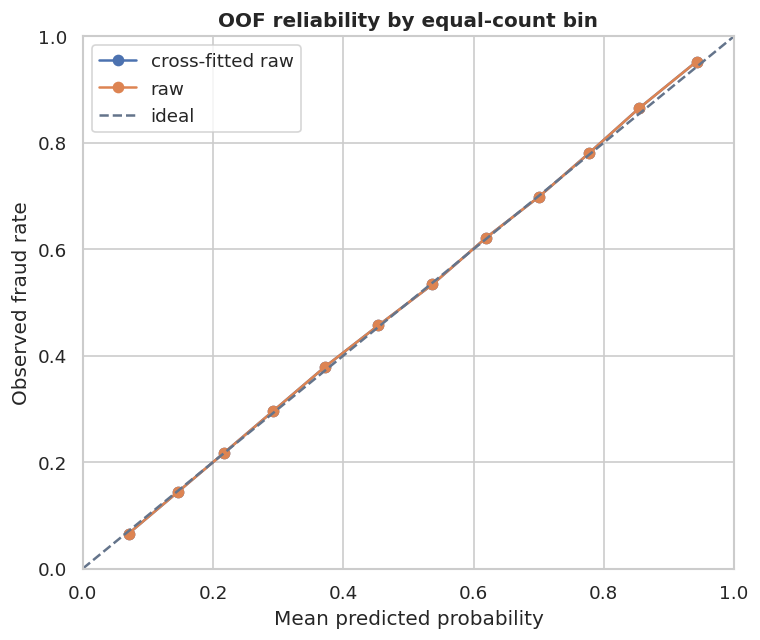

*Figure 4.7. Raw and leave-one-fold-out calibrated reliability for the selected candidate.*

**Question.** Which calibration is defensible?

**Method.** Leave-one-outer-fold-out raw, monotone sigmoid, monotone beta, and isotonic mappings were compared by Brier; global deployment maps supplied only rank/tie diagnostics.

**Result.** Folds 1–3 select **raw** with Brier improvement **+0.000000**. Across all OOF rows, Brier changes from **0.172383** raw to **0.172383** (improvement **+0.000000**); confirmation-fold Brier is **0.172840**. Isotonic remains diagnostic-only regardless of its Brier result because its deployment plateaus cannot be used for in-sample rank selection.

**Decision implication.** The test submission uses one calibrator fitted on all OOF predictions. Monotone mappings preserve the validated audit order; unsafe isotonic plateaus are rejected.

**Limitation / alternative explanation.** OOF calibration estimates reliability for the labeled competition distribution. Operational prevalence or investigation selection may require prospective recalibration.

In [27]:
selected_calibration_table = CALIBRATION_RESULTS[FINAL_CHOICE]["table"].copy()
show_table(selected_calibration_table, "4.22", f"Cross-fitted calibration comparison for {FINAL_CHOICE}")

def reliability_table(prediction, target, label, bins=12):
    frame = pd.DataFrame({"prediction":prediction, "target":target})
    frame["bin"] = pd.qcut(frame.prediction.rank(method="first"), q=bins, labels=False, duplicates="drop")
    result = frame.groupby("bin").agg(claims=("target", "size"), mean_prediction=("prediction", "mean"), observed_rate=("target", "mean")).reset_index()
    result["series"] = label
    return result


RELIABILITY = pd.concat([
    reliability_table(FINAL_RAW_OOF, y, "raw"),
    reliability_table(FINAL_OOF_PROBABILITY, y, f"cross-fitted {FINAL_CALIBRATION['chosen']}"),
], ignore_index=True)

def calibration_intercept_slope(prediction, target):
    x = probability_logit(prediction).reshape(-1, 1)
    model = LogisticRegression(C=1e6, solver="lbfgs", max_iter=500).fit(x, target)
    return float(model.intercept_[0]), float(model.coef_[0, 0])


CALIBRATION_SHAPE = pd.DataFrame([
    {"series":"raw", "intercept":calibration_intercept_slope(FINAL_RAW_OOF, y)[0], "slope":calibration_intercept_slope(FINAL_RAW_OOF, y)[1], "Brier":brier_score_loss(y, FINAL_RAW_OOF)},
    {"series":f"cross-fitted {FINAL_CALIBRATION['chosen']}", "intercept":calibration_intercept_slope(FINAL_OOF_PROBABILITY, y)[0], "slope":calibration_intercept_slope(FINAL_OOF_PROBABILITY, y)[1], "Brier":brier_score_loss(y, FINAL_OOF_PROBABILITY)},
])
show_table(CALIBRATION_SHAPE, "4.23", "Calibration intercept, slope, and conditional cross-fitted Brier diagnostics")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for label, group in RELIABILITY.groupby("series"):
    ax.plot(group.mean_prediction, group.observed_rate, marker="o", label=label)
ax.plot([0, 1], [0, 1], linestyle="--", color=COLORS["gray"], label="ideal")
ax.set(title="OOF reliability by equal-count bin", xlabel="Mean predicted probability", ylabel="Observed fraud rate", xlim=(0, 1), ylim=(0, 1))
ax.legend()
finish_figure(fig, "4.7", "Raw and leave-one-fold-out calibrated reliability for the selected candidate.")

raw_brier = float(selected_calibration_table.loc[selected_calibration_table.calibration.eq("raw"), "Brier"].iloc[0])
chosen_brier = float(selected_calibration_table.loc[selected_calibration_table.calibration.eq(FINAL_CALIBRATION["chosen"]), "Brier"].iloc[0])
calibration_gain = raw_brier - chosen_brier
selection_raw_brier = float(selected_calibration_table.loc[selected_calibration_table.calibration.eq("raw"), "selection_Brier"].iloc[0])
selection_chosen_brier = float(selected_calibration_table.loc[selected_calibration_table.calibration.eq(FINAL_CALIBRATION["chosen"]), "selection_Brier"].iloc[0])
confirmation_chosen_brier = float(selected_calibration_table.loc[selected_calibration_table.calibration.eq(FINAL_CALIBRATION["chosen"]), "confirmation_Brier"].iloc[0])
selection_calibration_gain = selection_raw_brier - selection_chosen_brier
set_hypothesis("H09", "SUPPORTED" if selection_calibration_gain >= 0.00005 else "REJECTED", f"chosen on folds 1–3={FINAL_CALIBRATION['chosen']}; selection Brier improvement={selection_calibration_gain:+.6f}; confirmation Brier={confirmation_chosen_brier:.6f}; isotonic diagnostic-only")
report_block(
    "Which calibration is defensible?",
    "Leave-one-outer-fold-out raw, monotone sigmoid, monotone beta, and isotonic mappings were compared by Brier; global deployment maps supplied only rank/tie diagnostics.",
    f"Folds 1–3 select **{FINAL_CALIBRATION['chosen']}** with Brier improvement **{selection_calibration_gain:+.6f}**. Across all OOF rows, Brier changes from **{raw_brier:.6f}** raw to **{chosen_brier:.6f}** (improvement **{calibration_gain:+.6f}**); confirmation-fold Brier is **{confirmation_chosen_brier:.6f}**. "
    "Isotonic remains diagnostic-only regardless of its Brier result because its deployment plateaus cannot be used for in-sample rank selection.",
    "The test submission uses one calibrator fitted on all OOF predictions. Monotone mappings preserve the validated audit order; unsafe isotonic plateaus are rejected.",
    "OOF calibration estimates reliability for the labeled competition distribution. Operational prevalence or investigation selection may require prospective recalibration."
)
TABLES.update({"A.reliability":RELIABILITY, "A.calibration_shape":CALIBRATION_SHAPE})


## 4.9 Ensemble Evidence, Stability, and Final Selection


In [28]:
show_table(BASE_DIVERSITY, "4.24", "OOF prediction correlation and audit-portfolio overlap among model families")
show_table(BLEND_GRID.sort_values("mean_fold_TechnicalScore", ascending=False).head(20), "4.25", "Leading fixed blend weights and spaces")
show_table(ELIGIBILITY.sort_values("gain_over_best_single", ascending=False), "4.26", "Pre-bootstrap ensemble eligibility evidence")
show_table(UNCERTAINTY, "4.27", "Conditional exact-signature-cluster bootstrap uncertainty for consequential candidate pairs")

TEST_DIVERSITY = diversity_rows([n for n in ["Corrected V1-like anchor", "CatBoost V2 seed mean", "XGBoost V2 one-hot", "LightGBM V2 one-hot", FINAL_CHOICE] if n in CANDIDATES], source="test")
show_table(TEST_DIVERSITY, "4.28", "Evaluation-prediction correlation and top-3/5/7 portfolio overlap")

inference_rows = []
for name in [n for n in ["Corrected V1-like anchor", "CatBoost V2 seed 2026", "CatBoost V2 seed 2127", "XGBoost V2 one-hot", "LightGBM V2 one-hot"] if n in CV_RESULTS]:
    fold_predictions = CV_RESULTS[name]["test_folds"]
    mean_prediction, median_prediction = fold_predictions.mean(axis=0), np.median(fold_predictions, axis=0)
    pair_overlaps = [
        portfolio_overlap(fold_predictions[left], fold_predictions[right], 0.05, TEST_TIE_KEYS)
        for left in range(len(fold_predictions)) for right in range(left + 1, len(fold_predictions))
    ]
    inference_rows.append({
        "candidate":name, "fold_models":len(fold_predictions),
        "mean_pairwise_top5_overlap":float(np.mean(pair_overlaps)),
        "minimum_pairwise_top5_overlap":float(np.min(pair_overlaps)),
        "mean_vs_median_top5_overlap":portfolio_overlap(mean_prediction, median_prediction, 0.05, TEST_TIE_KEYS),
        "mean_row_probability_SD":float(fold_predictions.std(axis=0, ddof=1).mean()),
    })
INFERENCE_STABILITY = pd.DataFrame(inference_rows)
show_table(INFERENCE_STABILITY, "4.28b", "Fold-model test portfolio and probability stability")

seed_mean_score = float(EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.experiment_id.eq("CatBoost V2 seed mean"), "TechnicalScore"].iloc[0])
best_seed_score = float(EXPERIMENT_REGISTRY[EXPERIMENT_REGISTRY.experiment_id.isin(["CatBoost V2 seed 2026", "CatBoost V2 seed 2127"])].TechnicalScore.max())
seed_gain = seed_mean_score - best_seed_score
set_hypothesis("H05", "SUPPORTED" if seed_gain >= 0.0005 else "REJECTED" if seed_gain <= -0.0005 else "INCONCLUSIVE", f"seed mean minus best seed={seed_gain:+.5f}")

blend_rows = EXPERIMENT_REGISTRY[EXPERIMENT_REGISTRY.complexity.ge(3)]
best_blend_gain = float((blend_rows.selection_fold_mean - blend_rows.tie_penalty).max() - best_single_score) if len(blend_rows) else np.nan
set_hypothesis("H06", "SUPPORTED" if len(blend_rows) and best_blend_gain >= 0.00075 else "REJECTED" if len(blend_rows) else "INCONCLUSIVE", f"best fixed cross-family blend minus best single={best_blend_gain:+.5f}" if len(blend_rows) else "no complementary library candidate available")

selected_uncertainty = UNCERTAINTY[UNCERTAINTY.candidate.eq(FINAL_CHOICE)]
uncertainty_text = (
    f"Paired evidence versus `{selected_uncertainty.iloc[0].reference}` is classified **{selected_uncertainty.iloc[0].classification}** with "
    f"P(gain)={selected_uncertainty.iloc[0].probability_gain:.3f}."
    if len(selected_uncertainty) else "The selected simple candidate required no ensemble confirmation."
)
fallback_text = (
    f"A documented methodological fallback was used because {SELECTION_FALLBACK_REASON}."
    if SELECTION_FALLBACK_REASON else "No methodological fallback was required."
)
report_block(
    "Why was the final candidate selected rather than the largest scalar score blindly?",
    "Technical Score, NR@5%, fold SD, fixed-form deployability, component overlap, fold wins, complexity, and paired bootstrap evidence enter a predeclared rule.",
    f"**{FINAL_CHOICE}** is selected; the best single candidate is **{best_single_name}**. {uncertainty_text} "
    f"Its selection-fold mean is **{selected_row.selection_fold_mean:.5f}**, confirmation-fold mean **{selected_row.confirmation_fold_mean:.5f}**, "
    f"full OOF fold SD **{selected_row.fold_SD:.5f}**, and calibration **{FINAL_CALIBRATION['chosen']}**. {fallback_text}",
    "The primary uses fold-averaged raw test predictions followed by one OOF-fitted calibrator. An ensemble survives only when complementarity is measurable and its gain is sufficiently repeatable.",
    "The cluster bootstrap is conditional on fixed, already-selected predictions and does not include refitting or search uncertainty. Each OOF row comes from one fold model whereas test uses a fold mean; Table 4.28b quantifies, but cannot eliminate, that inference-recipe difference. Unavailable provider/time entities remain unmodeled."
)
TABLES.update({"A.test_diversity":TEST_DIVERSITY, "A.inference_stability":INFERENCE_STABILITY})


**Table 4.24. OOF prediction correlation and audit-portfolio overlap among model families**

,source,candidate_1,candidate_2,Pearson,Spearman,top_3_overlap,top_5_overlap,top_7_overlap
0,oof,CatBoost V2 seed mean,XGBoost V2 one-hot,0.9171,0.9183,0.7051,0.6982,0.6960
1,oof,CatBoost V2 seed mean,LightGBM V2 one-hot,0.9368,0.9368,0.7615,0.7490,0.7403
2,oof,XGBoost V2 one-hot,LightGBM V2 one-hot,0.9754,0.9757,0.8447,0.8340,0.8475


**Table 4.25. Leading fixed blend weights and spaces**

,complement,space,cat_weight,mean_fold_TechnicalScore,fold_SD,selection_fold_mean,confirmation_fold_mean,NormalizedRecall@5%,AveragePrecision,Brier,ProtectionScore,TechnicalScore
29,LightGBM V2 one-hot,logit,0.9000,0.9228,0.0017,0.9227,0.9230,0.9712,0.8239,0.1719,0.9989,0.9230
35,LightGBM V2 one-hot,rank,0.9000,0.9226,0.0017,0.9224,0.9228,0.9704,0.8238,0.1720,0.9990,0.9226
23,LightGBM V2 one-hot,probability,0.9000,0.9224,0.0018,0.9223,0.9226,0.9704,0.8238,0.1720,0.9989,0.9226
11,XGBoost V2 one-hot,logit,0.9000,0.9223,0.0015,0.9220,0.9228,0.9705,0.8237,0.1720,0.9990,0.9226
17,XGBoost V2 one-hot,rank,0.9000,0.9220,0.0015,0.9217,0.9226,0.9697,0.8235,0.1720,0.9989,0.9221
28,LightGBM V2 one-hot,logit,0.8000,0.9220,0.0022,0.9217,0.9224,0.9698,0.8236,0.1720,0.9989,0.9222
5,XGBoost V2 one-hot,probability,0.9000,0.9220,0.0016,0.9215,0.9226,0.9698,0.8235,0.1721,0.9989,0.9222
10,XGBoost V2 one-hot,logit,0.8000,0.9216,0.0018,0.9213,0.9221,0.9700,0.8232,0.1723,0.9989,0.9222
34,LightGBM V2 one-hot,rank,0.8000,0.9216,0.0018,0.9213,0.9222,0.9695,0.8233,0.1721,0.9991,0.9220
27,LightGBM V2 one-hot,logit,0.7000,0.9216,0.0023,0.9212,0.9221,0.9692,0.8229,0.1723,0.9988,0.9216


**Table 4.26. Pre-bootstrap ensemble eligibility evidence**

...

**Table 4.28. Evaluation-prediction correlation and top-3/5/7 portfolio overlap**

,source,candidate_1,candidate_2,Pearson,Spearman,top_3_overlap,top_5_overlap,top_7_overlap
0,test,Corrected V1-like anchor,CatBoost V2 seed mean,0.9208,0.9201,0.8193,0.7592,0.7424
1,test,Corrected V1-like anchor,XGBoost V2 one-hot,0.9514,0.9499,0.7519,0.7617,0.7628
2,test,Corrected V1-like anchor,LightGBM V2 one-hot,0.9498,0.9488,0.7785,0.7652,0.7749
3,test,Corrected V1-like anchor,CatBoost V2 seed 2127,0.9209,0.9202,0.8177,0.7617,0.7428
4,test,CatBoost V2 seed mean,XGBoost V2 one-hot,0.9271,0.9279,0.7127,0.7068,0.6968
5,test,CatBoost V2 seed mean,LightGBM V2 one-hot,0.9459,0.9458,0.7677,0.7522,0.7374
6,test,CatBoost V2 seed mean,CatBoost V2 seed 2127,0.9996,0.9996,0.9817,0.9785,0.9839
7,test,XGBoost V2 one-hot,LightGBM V2 one-hot,0.9817,0.9821,0.8476,0.8452,0.8637
8,test,XGBoost V2 one-hot,CatBoost V2 seed 2127,0.9272,0.9280,0.7086,0.7043,0.6978
9,test,LightGBM V2 one-hot,CatBoost V2 seed 2127,0.9459,0.9457,0.7644,0.7532,0.7396


**Table 4.28b. Fold-model test portfolio and probability stability**

,candidate,fold_models,mean_pairwise_top5_overlap,minimum_pairwise_top5_overlap,mean_vs_median_top5_overlap,mean_row_probability_SD
0,Corrected V1-like anchor,5,0.8175,0.8037,0.9560,0.0415
1,CatBoost V2 seed 2026,5,0.8534,0.8332,0.9595,0.0425
2,CatBoost V2 seed 2127,5,0.8473,0.8382,0.9595,0.0425
3,XGBoost V2 one-hot,5,0.8488,0.8342,0.9705,0.0297
4,LightGBM V2 one-hot,5,0.8611,0.8541,0.9680,0.0342


**Question.** Why was the final candidate selected rather than the largest scalar score blindly?

**Method.** Technical Score, NR@5%, fold SD, fixed-form deployability, component overlap, fold wins, complexity, and paired bootstrap evidence enter a predeclared rule.

**Result.** **CatBoost V2 seed 2127** is selected; the best single candidate is **CatBoost V2 seed 2127**. Paired evidence versus `Corrected V1-like anchor` is classified **MATERIAL** with P(gain)=1.000. Its selection-fold mean is **0.92189**, confirmation-fold mean **0.92369**, full OOF fold SD **0.00273**, and calibration **raw**. No methodological fallback was required.

**Decision implication.** The primary uses fold-averaged raw test predictions followed by one OOF-fitted calibrator. An ensemble survives only when complementarity is measurable and its gain is sufficiently repeatable.

**Limitation / alternative explanation.** The cluster bootstrap is conditional on fixed, already-selected predictions and does not include refitting or search uncertainty. Each OOF row comes from one fold model whereas test uses a fold mean; Table 4.28b quantifies, but cannot eliminate, that inference-recipe difference. Unavailable provider/time entities remain unmodeled.

## 4.10 Audit Allocation at 3%, 5%, and 7%


**Table 4.29. Fraud capture and legitimate workload at 3%, 5%, and 7% capacity**

,strategy,capacity,K,fraud_captured,Recall,NormalizedRecall,precision,legitimate_audits,audit_FPR,lift_over_random,boundary_tie_size,expected_tie_capture,pessimistic_tie_capture
0,CatBoost V2 seed 2127,0.0300,4805,4718.0000,0.0588,0.9819,0.9819,87.0000,0.0011,1.9609,1,4718.0000,4718
1,CatBoost V2 seed 2127,0.0500,8008,7772.0000,0.0969,0.9705,0.9705,236.0000,0.0030,1.9383,1,7772.0000,7772
2,CatBoost V2 seed 2127,0.0700,11212,10761.0000,0.1342,0.9598,0.9598,451.0000,0.0056,1.9168,1,10761.0000,10761
3,Corrected V1-like anchor,0.0300,4805,4674.0000,0.0583,0.9727,0.9727,131.0000,0.0016,1.9427,1,4674.0000,4674
4,Corrected V1-like anchor,0.0500,8008,7623.0000,0.0950,0.9519,0.9519,385.0000,0.0048,1.9011,1,7623.0000,7623
5,Corrected V1-like anchor,0.0700,11212,10464.0000,0.1305,0.9333,0.9333,748.0000,0.0094,1.8639,1,10464.0000,10464
6,Burden baseline,0.0300,4805,3059.0000,0.0381,0.6366,0.6366,1746.0000,0.0218,1.2714,32,3058.0000,3050
7,Burden baseline,0.0500,8008,4844.0000,0.0604,0.6049,0.6049,3164.0000,0.0396,1.2080,8961,4830.0037,4719
8,Burden baseline,0.0700,11212,6561.0000,0.0818,0.5852,0.5852,4651.0000,0.0582,1.1687,8961,6507.6254,4719
9,Random audit (expectation),0.0300,4805,2405.9798,0.0300,0.5007,0.5007,2399.0202,0.0300,1.0000,160174,2405.9798,0


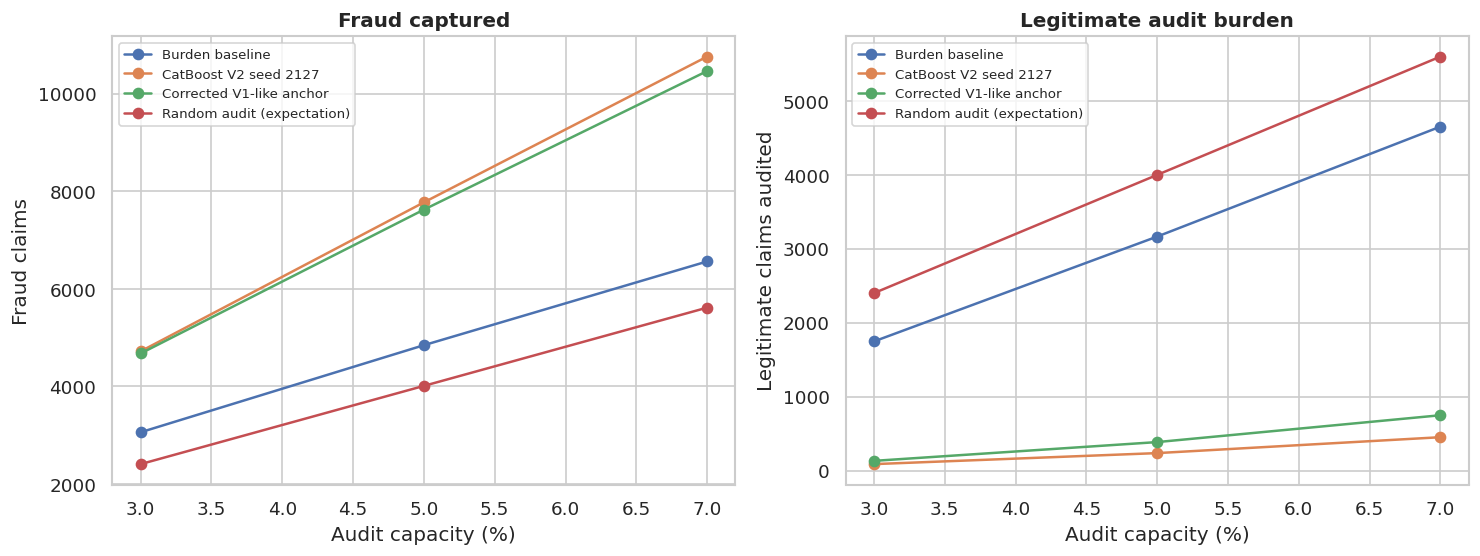

*Figure 4.8. Capacity sensitivity separates fraud capture from legitimate audit burden.*

**Question.** What does the selected ranking deliver under constrained audit capacity?

**Method.** The exact organizer portfolio rule is applied at 3%, 5%, and 7%, alongside random expectation, a transparent burden model, the corrected V1-like anchor, and tie sensitivity.

**Result.** At 5%, **CatBoost V2 seed 2127** audits **8,008** claims, captures **7,772** observed fraud claims, achieves normalized recall **0.9705** and precision **0.9705**, and audits **236** legitimate claims. Lift over random is **1.938×**.

**Decision implication.** Capacity changes expose the marginal trade-off rather than implying 5% is universally optimal. Investigators receive a ranked queue plus evidence, not an automated disposition.

**Limitation / alternative explanation.** OOF capture assumes observed labels and competition sampling. Operational confirmation rates, costs, and maturation delays require a shadow pilot.

In [29]:
FINAL_RANK_OOF = FINAL_RAW_OOF

def allocation_table(target, prediction, groups, keys, capacities, strategy):
    rows = []
    for capacity in capacities:
        metric = official_metrics(target, prediction, groups, capacity, tie_key=keys, min_nonfraud=CFG.min_group_nonfraud)
        rows.append({
            "strategy":strategy, "capacity":capacity, "K":metric["K"], "fraud_captured":metric["TP_K"],
            "Recall":metric["Recall@capacity"], "NormalizedRecall":metric["NormalizedRecall@capacity"],
            "precision":metric["Precision@capacity"], "legitimate_audits":metric["LegitimateAudits"],
            "audit_FPR":metric["AuditFPR"], "lift_over_random":metric["Lift@capacity"],
            "boundary_tie_size":metric["tie_boundary_tie_size"],
            "expected_tie_capture":metric["tie_expected_fraud_captured"],
            "pessimistic_tie_capture":metric["tie_pessimistic_fraud_captured"],
        })
    return pd.DataFrame(rows)


allocation_frames = [
    allocation_table(y, FINAL_RANK_OOF, PROTECTED, TIE_KEYS, CFG.capacities, FINAL_CHOICE),
    allocation_table(y, CANDIDATES["Corrected V1-like anchor"]["raw_oof"], PROTECTED, TIE_KEYS, CFG.capacities, "Corrected V1-like anchor"),
    allocation_table(y, CANDIDATES["Burden baseline"]["raw_oof"], PROTECTED, TIE_KEYS, CFG.capacities, "Burden baseline"),
]
random_rows = []
prevalence = y.mean()
for capacity in CFG.capacities:
    k_capacity = int(np.floor(capacity * len(y)))
    expected_fraud = k_capacity * prevalence
    random_rows.append({
        "strategy":"Random audit (expectation)", "capacity":capacity, "K":k_capacity,
        "fraud_captured":expected_fraud, "Recall":expected_fraud / y.sum(),
        "NormalizedRecall":expected_fraud / max(1, min(k_capacity, int(y.sum()))), "precision":prevalence,
        "legitimate_audits":k_capacity * (1 - prevalence), "audit_FPR":k_capacity / len(y),
        "lift_over_random":1.0, "boundary_tie_size":len(y),
        "expected_tie_capture":expected_fraud, "pessimistic_tie_capture":max(0, k_capacity - int((y == 0).sum())),
    })
allocation_frames.append(pd.DataFrame(random_rows))
AUDIT_ALLOCATION = pd.concat(allocation_frames, ignore_index=True)
show_table(AUDIT_ALLOCATION, "4.29", "Fraud capture and legitimate workload at 3%, 5%, and 7% capacity")

plot = AUDIT_ALLOCATION[AUDIT_ALLOCATION.strategy.isin([FINAL_CHOICE, "Corrected V1-like anchor", "Burden baseline", "Random audit (expectation)"])]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for name, group in plot.groupby("strategy"):
    axes[0].plot(group.capacity * 100, group.fraud_captured, marker="o", label=name)
    axes[1].plot(group.capacity * 100, group.legitimate_audits, marker="o", label=name)
axes[0].set(title="Fraud captured", xlabel="Audit capacity (%)", ylabel="Fraud claims")
axes[1].set(title="Legitimate audit burden", xlabel="Audit capacity (%)", ylabel="Legitimate claims audited")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
finish_figure(fig, "4.8", "Capacity sensitivity separates fraud capture from legitimate audit burden.")

five = AUDIT_ALLOCATION[(AUDIT_ALLOCATION.strategy == FINAL_CHOICE) & np.isclose(AUDIT_ALLOCATION.capacity, 0.05)].iloc[0]
report_block(
    "What does the selected ranking deliver under constrained audit capacity?",
    "The exact organizer portfolio rule is applied at 3%, 5%, and 7%, alongside random expectation, a transparent burden model, the corrected V1-like anchor, and tie sensitivity.",
    f"At 5%, **{FINAL_CHOICE}** audits **{int(five.K):,}** claims, captures **{int(five.fraud_captured):,}** observed fraud claims, "
    f"achieves normalized recall **{five.NormalizedRecall:.4f}** and precision **{five.precision:.4f}**, and audits **{int(five.legitimate_audits):,}** legitimate claims. Lift over random is **{five.lift_over_random:.3f}×**.",
    "Capacity changes expose the marginal trade-off rather than implying 5% is universally optimal. Investigators receive a ranked queue plus evidence, not an automated disposition.",
    "OOF capture assumes observed labels and competition sampling. Operational confirmation rates, costs, and maturation delays require a shadow pilot."
)
TABLES["A.audit_allocation"] = AUDIT_ALLOCATION


## 4.11 Policyholder Protection


**Table 4.30. Official gender/age FPR gaps and Protection Score by capacity**

,capacity,Gap_gender,Gap_age,ProtectionScore,eligible_gender_groups,eligible_age_groups
0,0.0300,0.0000,0.0010,0.9990,2,4
1,0.0500,0.0001,0.0012,0.9988,2,4
2,0.0700,0.0000,0.0021,0.9979,2,4


**Table 4.31. Group denominators, legitimate audits, FPR, eligibility, and Wilson intervals**

,attribute,group,population,nonfraud,audit_count,legitimate_audits,FPR,eligible,capacity,FPR_ci_low,FPR_ci_high
0,gender,L,74284,36634,2144,39,0.0011,True,0.0300,0.0008,0.0015
1,gender,P,85890,43337,2661,48,0.0011,True,0.0300,0.0008,0.0015
2,age_group,0–17,40125,20360,856,13,0.0006,True,0.0300,0.0004,0.0011
3,age_group,18–39,41391,20786,1243,19,0.0009,True,0.0300,0.0006,0.0014
4,age_group,40–59,47844,23823,1580,40,0.0017,True,0.0300,0.0012,0.0023
5,age_group,60+,30814,15002,1126,15,0.0010,True,0.0300,0.0006,0.0016
6,gender,L,74284,36634,3678,106,0.0029,True,0.0500,0.0024,0.0035
7,gender,P,85890,43337,4330,130,0.0030,True,0.0500,0.0025,0.0036
8,age_group,0–17,40125,20360,1592,49,0.0024,True,0.0500,0.0018,0.0032
9,age_group,18–39,41391,20786,2174,74,0.0036,True,0.0500,0.0028,0.0045


**Table 4.31b. Conditional signature-cluster uncertainty for 5% gaps and Protection Score**

,metric,estimate,ci_2.5%,ci_97.5%,method
0,Gap_gender,0.0001,0.0000,0.0009,conditional exact-signature-cluster bootstrap
1,Gap_age,0.0012,0.0004,0.0024,conditional exact-signature-cluster bootstrap
2,ProtectionScore,0.9988,0.9976,0.9996,conditional exact-signature-cluster bootstrap


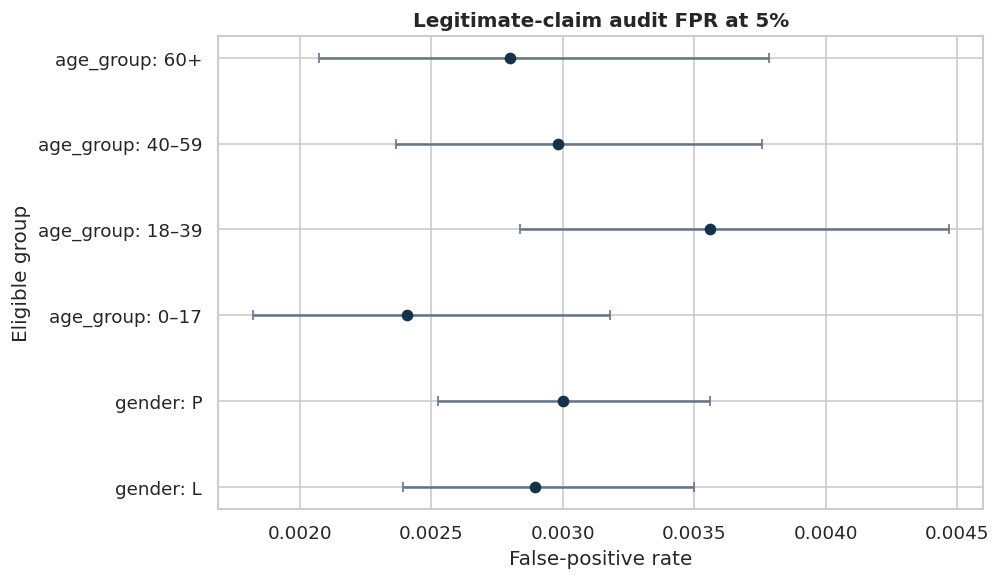

*Figure 4.9. Official eligible-group FPR with 95% Wilson intervals; disparity is not causality.*

**Question.** Does the selected portfolio expose eligible groups differently?

**Method.** Gender and exact official age bands are evaluated among legitimate claims; groups below 100 legitimate observations and missing age are shown but excluded from official gaps. Wilson intervals describe uncertainty.

**Result.** At 5%, gender FPR gap is **0.000106**, age gap **0.001153**, and Protection Score **0.998847**. Eligible groups number 2 for gender and 4 for age. The conditional signature-cluster 95% interval for Protection is [0.997566, 0.999555].

**Decision implication.** Monitor exposure, confirmation, overrides, appeals, and delays by group. Do not alter individual probabilities by demographic group to game the metric.

**Limitation / alternative explanation.** Observed gaps may reflect case mix, labels, access, proxies, sampling, or chance. This competition metric is not a complete equity assessment.

In [30]:
def add_wilson_intervals(table, confidence=0.95):
    out = table.copy(); z = stats.norm.ppf(1 - (1 - confidence) / 2)
    n, x = out.nonfraud.astype(float), out.legitimate_audits.astype(float)
    denominator = 1 + z**2 / n.replace(0, np.nan)
    center = (x / n.replace(0, np.nan) + z**2 / (2 * n.replace(0, np.nan))) / denominator
    half = z * np.sqrt((x / n.replace(0, np.nan)) * (1 - x / n.replace(0, np.nan)) / n.replace(0, np.nan) + z**2 / (4 * n.replace(0, np.nan)**2)) / denominator
    out["FPR_ci_low"], out["FPR_ci_high"] = (center - half).clip(0, 1), (center + half).clip(0, 1)
    return out


fairness_rows, gap_rows = [], []
for capacity in CFG.capacities:
    metric = official_metrics(y, FINAL_RANK_OOF, PROTECTED, capacity, tie_key=TIE_KEYS, min_nonfraud=CFG.min_group_nonfraud)
    detail = pd.concat([metric["gender_table"], metric["age_table"]], ignore_index=True)
    detail["capacity"] = capacity
    fairness_rows.append(add_wilson_intervals(detail))
    gap_rows.append({
        "capacity":capacity, "Gap_gender":metric["Gap_gender"], "Gap_age":metric["Gap_age"],
        "ProtectionScore":metric["ProtectionScore"], "eligible_gender_groups":int(metric["gender_table"].eligible.sum()),
        "eligible_age_groups":int(metric["age_table"].eligible.sum()),
    })
FAIRNESS_DETAIL = pd.concat(fairness_rows, ignore_index=True)
FAIRNESS_GAPS = pd.DataFrame(gap_rows)

rng_fairness = np.random.default_rng(CFG.seed + 992)
fairness_bootstrap_rows = []
for _ in range(CFG.bootstrap_repetitions):
    indices = sample_signature_cluster_rows(rng_fairness)
    sampled_keys = np.asarray([f"{TIE_KEYS[index]}__{position}" for position, index in enumerate(indices)])
    metric = official_metrics(
        y[indices], FINAL_RANK_OOF[indices], PROTECTED.iloc[indices].reset_index(drop=True),
        0.05, tie_key=sampled_keys, min_nonfraud=CFG.min_group_nonfraud,
    )
    fairness_bootstrap_rows.append({
        "Gap_gender":metric["Gap_gender"], "Gap_age":metric["Gap_age"],
        "ProtectionScore":metric["ProtectionScore"],
    })
FAIRNESS_GAP_BOOTSTRAP = pd.DataFrame(fairness_bootstrap_rows)
FAIRNESS_GAP_UNCERTAINTY = pd.DataFrame([
    {
        "metric":column, "estimate":FAIRNESS_GAPS.loc[np.isclose(FAIRNESS_GAPS.capacity, 0.05), column].iloc[0],
        "ci_2.5%":FAIRNESS_GAP_BOOTSTRAP[column].quantile(0.025),
        "ci_97.5%":FAIRNESS_GAP_BOOTSTRAP[column].quantile(0.975),
        "method":"conditional exact-signature-cluster bootstrap",
    }
    for column in ["Gap_gender", "Gap_age", "ProtectionScore"]
])
show_table(FAIRNESS_GAPS, "4.30", "Official gender/age FPR gaps and Protection Score by capacity")
show_table(FAIRNESS_DETAIL, "4.31", "Group denominators, legitimate audits, FPR, eligibility, and Wilson intervals")
show_table(FAIRNESS_GAP_UNCERTAINTY, "4.31b", "Conditional signature-cluster uncertainty for 5% gaps and Protection Score")

five_detail = FAIRNESS_DETAIL[np.isclose(FAIRNESS_DETAIL.capacity, 0.05) & FAIRNESS_DETAIL.eligible].copy()
fig, ax = plt.subplots(figsize=(8.5, 5))
labels = five_detail.attribute + ": " + five_detail.group
errors = np.vstack([five_detail.FPR - five_detail.FPR_ci_low, five_detail.FPR_ci_high - five_detail.FPR])
ax.errorbar(five_detail.FPR, np.arange(len(five_detail)), xerr=errors, fmt="o", color=COLORS["navy"], ecolor=COLORS["gray"], capsize=3)
ax.set_yticks(np.arange(len(five_detail)), labels)
ax.set(title="Legitimate-claim audit FPR at 5%", xlabel="False-positive rate", ylabel="Eligible group")
finish_figure(fig, "4.9", "Official eligible-group FPR with 95% Wilson intervals; disparity is not causality.")

five_gap = FAIRNESS_GAPS[np.isclose(FAIRNESS_GAPS.capacity, 0.05)].iloc[0]
protection_interval = FAIRNESS_GAP_UNCERTAINTY[FAIRNESS_GAP_UNCERTAINTY.metric.eq("ProtectionScore")].iloc[0]
report_block(
    "Does the selected portfolio expose eligible groups differently?",
    "Gender and exact official age bands are evaluated among legitimate claims; groups below 100 legitimate observations and missing age are shown but excluded from official gaps. Wilson intervals describe uncertainty.",
    f"At 5%, gender FPR gap is **{five_gap.Gap_gender:.6f}**, age gap **{five_gap.Gap_age:.6f}**, and Protection Score **{five_gap.ProtectionScore:.6f}**. "
    f"Eligible groups number {int(five_gap.eligible_gender_groups)} for gender and {int(five_gap.eligible_age_groups)} for age. "
    f"The conditional signature-cluster 95% interval for Protection is [{protection_interval['ci_2.5%']:.6f}, {protection_interval['ci_97.5%']:.6f}].",
    "Monitor exposure, confirmation, overrides, appeals, and delays by group. Do not alter individual probabilities by demographic group to game the metric.",
    "Observed gaps may reflect case mix, labels, access, proxies, sampling, or chance. This competition metric is not a complete equity assessment."
)
TABLES.update({"A.fairness_detail":FAIRNESS_DETAIL, "A.fairness_gaps":FAIRNESS_GAPS, "A.fairness_gap_uncertainty":FAIRNESS_GAP_UNCERTAINTY})


## 4.12 Explainability and Error Drivers

The retained first V2 CatBoost fold supplies held-out permutation and SHAP evidence without an extra model fit. Native importance is averaged across all V2 CatBoost folds, permitting a stability check. If the selected solution is not that CatBoost alone, these explanations are explicitly component/surrogate evidence rather than an attribution of the entire selected ensemble. Local explanations are displayed with the raw claim fields and observed OOF status; they are investigative prompts only.


**Table 4.32. Cross-fold CatBoost native importance**

,feature,native_importance_mean,native_importance_SD
geo__facility,geo__facility,8.8971,0.1114
diagnosis__service,diagnosis__service,6.0357,0.1708
diagnosis__cmg,diagnosis__cmg,5.3938,0.1682
kdkc,kdkc,4.7468,0.2980
cmg__severity,cmg__severity,4.7007,0.1692
frequency__geo__facility,frequency__geo__facility,4.0760,0.1000
kdkc_prefix2,kdkc_prefix2,3.9877,0.1637
umur,umur,3.8623,0.1691
diagprimer,diagprimer,3.7285,0.2817
cmg,cmg,3.6437,0.1942


**Table 4.33. Cross-fold stability of CatBoost native importance**

,fold_pairs,mean_Spearman,min_Spearman,top10_mean_pairwise_Jaccard
0,10,0.9816,0.9754,1.0000


**Table 4.34. Held-out permutation importance measured by AP loss**

,feature,AP_loss_mean,AP_loss_SD
0,geo__facility,0.1029,0.0026
11,severitylevel,0.0235,0.0016
2,diagnosis__cmg,0.0190,0.0015
1,diagnosis__service,0.0164,0.0003
4,cmg__severity,0.0085,0.0008
3,kdkc,0.0070,0.0023
9,cmg,0.0034,0.0003
6,kdkc_prefix2,0.0031,0.0010
8,diagprimer,0.0029,0.0001
5,frequency__geo__facility,0.0028,0.0001


**Table 4.35. Largest signed SHAP contributions for one high-scored held-out claim**

,feature,value,SHAP_contribution,abs_contribution
77,diagnosis__cmg,h60_h95__J,1.1232,1.1232
75,geo__facility,0075__C,1.0448,1.0448
0,kdkc,0502,0.4205,0.4205
73,cmg__severity,J__0,0.4084,0.4084
78,diagnosis__service,h60_h95__2,0.3585,0.3585
86,frequency__diagnosis__cmg,0.0012,0.2946,0.2946
7,cmg,J,0.2057,0.2057
34,proc29_31,1,0.1665,0.1665
1,dati2,0075,0.1532,0.1532
76,kdkc__dati2,0502__0075,0.1510,0.1510


**Table 4.36. Held-out investigator-oriented example cases**

,case_type,claim_id,observed_label,fold_probability
0,audited fraud label,CLM_A86CF57C00F8E0,1,0.9976
1,audited legitimate label,CLM_3D9246DB376722,0,0.9835
2,highest-scored non-audited fraud label,CLM_33705CD4CF53BE,1,0.9327


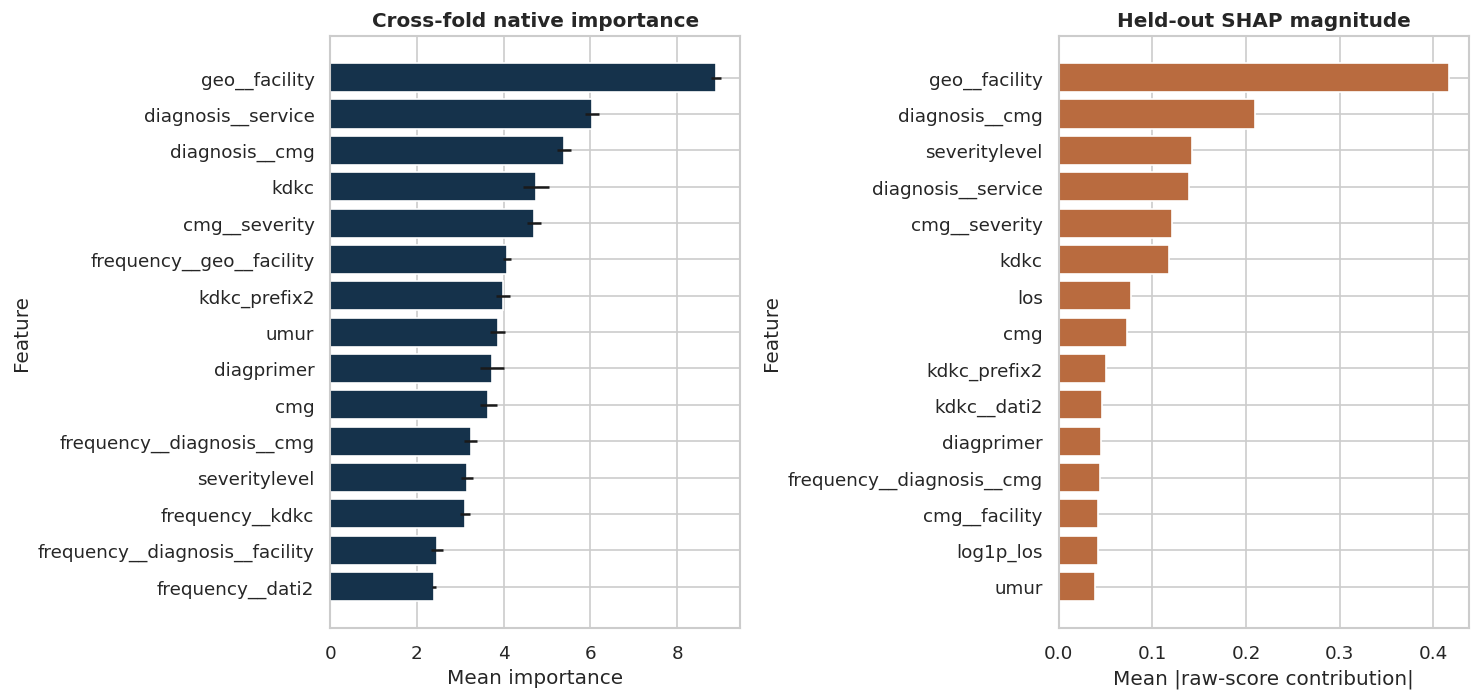

*Figure 4.10. Global native and held-out SHAP evidence; neither attribution is causal.*

**Question.** Which recorded factors drive risk scores and individual alerts?

**Method.** Cross-fold native importance, held-out permutation AP loss, bounded-sample SHAP, local signed contributions, and representative true/false/missed cases are triangulated.

**Result.** This is **selected-model component** evidence. Leading native, permutation, and SHAP features are `geo__facility`, `geo__facility`, and `geo__facility`. Mean cross-fold importance Spearman is **0.982** with top-10 Jaccard **1.000**.

**Decision implication.** The investigator view should show the calibrated score, rank, raw claim evidence, largest signed drivers, missing/unseen warnings, and comparable prior patterns—never a causal accusation.

**Limitation / alternative explanation.** Correlated variables can substitute under permutation and split SHAP credit. Explanations describe this model and sample, not intent or treatment effect.

In [31]:
importance_series = IMPORTANCE_RECORDS["CatBoost V2 seed 2026"]
importance_matrix = pd.concat(importance_series, axis=1).fillna(0)
GLOBAL_IMPORTANCE = pd.DataFrame({
    "feature":importance_matrix.index,
    "native_importance_mean":importance_matrix.mean(axis=1),
    "native_importance_SD":importance_matrix.std(axis=1, ddof=1),
}).sort_values("native_importance_mean", ascending=False)

importance_correlations = []
for left in range(importance_matrix.shape[1]):
    for right in range(left + 1, importance_matrix.shape[1]):
        importance_correlations.append(stats.spearmanr(importance_matrix.iloc[:, left], importance_matrix.iloc[:, right]).statistic)
IMPORTANCE_STABILITY = pd.DataFrame([{
    "fold_pairs":len(importance_correlations), "mean_Spearman":np.nanmean(importance_correlations),
    "min_Spearman":np.nanmin(importance_correlations),
    "top10_mean_pairwise_Jaccard":np.mean([
        len(set(importance_matrix.iloc[:, i].nlargest(10).index) & set(importance_matrix.iloc[:, j].nlargest(10).index)) /
        max(len(set(importance_matrix.iloc[:, i].nlargest(10).index) | set(importance_matrix.iloc[:, j].nlargest(10).index)), 1)
        for i in range(importance_matrix.shape[1]) for j in range(i + 1, importance_matrix.shape[1])
    ]),
}])

anchor = CV_RESULTS["CatBoost V2 seed 2026"]["anchor"]
rng = np.random.default_rng(CFG.seed + 901)
permutation_positions = rng.choice(len(anchor["valid_idx"]), min(6000, len(anchor["valid_idx"])), replace=False)
permutation_frame = anchor["valid_frame"].iloc[permutation_positions].copy()
permutation_target = y[anchor["valid_idx"]][permutation_positions]
base_prediction = predict_bundle(anchor["bundle"], permutation_frame)
base_ap = average_precision_score(permutation_target, base_prediction)
permutation_rows = []
for feature in GLOBAL_IMPORTANCE.head(15).feature:
    losses = []
    for _ in range(2):
        changed = permutation_frame.copy()
        changed[feature] = rng.permutation(changed[feature].to_numpy())
        losses.append(base_ap - average_precision_score(permutation_target, predict_bundle(anchor["bundle"], changed)))
    permutation_rows.append({"feature":feature, "AP_loss_mean":np.mean(losses), "AP_loss_SD":np.std(losses, ddof=1)})
PERMUTATION_IMPORTANCE = pd.DataFrame(permutation_rows).sort_values("AP_loss_mean", ascending=False)

sample_positions = rng.choice(len(anchor["valid_idx"]), min(CFG.shap_sample, len(anchor["valid_idx"])), replace=False)
shap_frame = catboost_ready(anchor["valid_frame"].iloc[sample_positions][anchor["bundle"]["features"]], anchor["bundle"]["categorical"])
shap_values = anchor["bundle"]["model"].get_feature_importance(Pool(shap_frame, cat_features=anchor["bundle"]["categorical"]), type="ShapValues")
SHAP_IMPORTANCE = pd.DataFrame({
    "feature":anchor["bundle"]["features"], "mean_abs_SHAP":np.abs(shap_values[:, :-1]).mean(axis=0),
}).sort_values("mean_abs_SHAP", ascending=False)

representative_position = int(np.argmax(anchor["prediction"]))
representative_original = int(anchor["valid_idx"][representative_position])
representative_frame = catboost_ready(anchor["valid_frame"].iloc[[representative_position]][anchor["bundle"]["features"]], anchor["bundle"]["categorical"])
local_values = anchor["bundle"]["model"].get_feature_importance(Pool(representative_frame, cat_features=anchor["bundle"]["categorical"]), type="ShapValues")[0, :-1]
LOCAL_EXPLANATION = pd.DataFrame({
    "feature":anchor["bundle"]["features"],
    "value":[representative_frame.iloc[0][c] for c in anchor["bundle"]["features"]],
    "SHAP_contribution":local_values,
}).assign(abs_contribution=lambda d:d.SHAP_contribution.abs()).sort_values("abs_contribution", ascending=False).head(12)

anchor_selected = top_k_mask(anchor["prediction"], 0.05, tie_key=TIE_KEYS[anchor["valid_idx"]])
representatives = []
for case_type, mask in {
    "audited fraud label":anchor_selected & (y[anchor["valid_idx"]] == 1),
    "audited legitimate label":anchor_selected & (y[anchor["valid_idx"]] == 0),
    "highest-scored non-audited fraud label":(~anchor_selected) & (y[anchor["valid_idx"]] == 1),
}.items():
    positions = np.flatnonzero(mask)
    if len(positions):
        pos = positions[np.argmax(anchor["prediction"][positions])]
        original = anchor["valid_idx"][pos]
        representatives.append({"case_type":case_type, ID_COL:TIE_KEYS[original], "observed_label":int(y[original]), "fold_probability":anchor["prediction"][pos]})
REPRESENTATIVE_CLAIMS = pd.DataFrame(representatives)

show_table(GLOBAL_IMPORTANCE.head(20), "4.32", "Cross-fold CatBoost native importance")
show_table(IMPORTANCE_STABILITY, "4.33", "Cross-fold stability of CatBoost native importance")
show_table(PERMUTATION_IMPORTANCE, "4.34", "Held-out permutation importance measured by AP loss")
show_table(LOCAL_EXPLANATION, "4.35", "Largest signed SHAP contributions for one high-scored held-out claim")
show_table(REPRESENTATIVE_CLAIMS, "4.36", "Held-out investigator-oriented example cases")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))
native_plot = GLOBAL_IMPORTANCE.head(15).sort_values("native_importance_mean")
axes[0].barh(native_plot.feature, native_plot.native_importance_mean, xerr=native_plot.native_importance_SD, color=COLORS["navy"])
axes[0].set(title="Cross-fold native importance", xlabel="Mean importance", ylabel="Feature")
shap_plot = SHAP_IMPORTANCE.head(15).sort_values("mean_abs_SHAP")
axes[1].barh(shap_plot.feature, shap_plot.mean_abs_SHAP, color=COLORS["orange"])
axes[1].set(title="Held-out SHAP magnitude", xlabel="Mean |raw-score contribution|", ylabel="Feature")
finish_figure(fig, "4.10", "Global native and held-out SHAP evidence; neither attribution is causal.")

top_native, top_permutation, top_shap = GLOBAL_IMPORTANCE.iloc[0].feature, PERMUTATION_IMPORTANCE.iloc[0].feature, SHAP_IMPORTANCE.iloc[0].feature
EXPLANATION_SCOPE = "selected-model component" if any("Cat" in component for component in FINAL_CANDIDATE["components"]) else "predeclared CatBoost surrogate"
report_block(
    "Which recorded factors drive risk scores and individual alerts?",
    "Cross-fold native importance, held-out permutation AP loss, bounded-sample SHAP, local signed contributions, and representative true/false/missed cases are triangulated.",
    f"This is **{EXPLANATION_SCOPE}** evidence. Leading native, permutation, and SHAP features are `{top_native}`, `{top_permutation}`, and `{top_shap}`. "
    f"Mean cross-fold importance Spearman is **{IMPORTANCE_STABILITY.mean_Spearman.iloc[0]:.3f}** with top-10 Jaccard **{IMPORTANCE_STABILITY.top10_mean_pairwise_Jaccard.iloc[0]:.3f}**.",
    "The investigator view should show the calibrated score, rank, raw claim evidence, largest signed drivers, missing/unseen warnings, and comparable prior patterns—never a causal accusation.",
    "Correlated variables can substitute under permutation and split SHAP credit. Explanations describe this model and sample, not intent or treatment effect."
)
TABLES.update({
    "A.global_importance":GLOBAL_IMPORTANCE, "A.importance_stability":IMPORTANCE_STABILITY,
    "A.permutation":PERMUTATION_IMPORTANCE, "A.shap":SHAP_IMPORTANCE,
})


## 4.13 Robustness, Ablation, and Transport Sensitivity

Feature, protected-attribute, and suspicious-signal screens were completed before full model fitting, so materially better removals changed the finalist feature set programmatically. Their two-fold statuses remain screening evidence—not full-CV proof. V1's already-executed full location removal is not redundantly repeated. One selected V2 CatBoost model is instead tested on unseen `kdkc` groups to quantify transport stress.


**Table 4.37. Feature-removal screen on common CatBoost screening folds**

,variant,NormalizedRecall@5%,AveragePrecision,Brier,ProtectionScore,TechnicalScore,delta_TechnicalScore,screen_status,feature_contribution
0,V2 screen full,0.9678,0.8217,0.1736,0.9988,0.9205,0.0000,reference,—
1,code hierarchy removed,0.9672,0.8217,0.1736,0.9982,0.9201,-0.0004,INCONCLUSIVE,0.0004
2,burden density removed,0.9666,0.8217,0.1736,0.9984,0.9198,-0.0007,INCONCLUSIVE,0.0007
3,code concentration removed,0.9660,0.8215,0.1736,0.9982,0.9193,-0.0011,SCREEN_POSITIVE,0.0011
4,structured interactions removed,0.9678,0.8169,0.1758,0.9988,0.9192,-0.0013,SCREEN_POSITIVE,0.0013
5,fold-safe rarity removed,0.9663,0.8216,0.1736,0.9983,0.9196,-0.0009,SCREEN_POSITIVE,0.0009
6,protected attributes removed,0.9669,0.8206,0.1740,0.9987,0.9197,-0.0008,SENSITIVITY_ONLY,—


**Table 4.37b. Feature-family hypotheses and same-fold ablation evidence**

,ID,Hypothesis,Motivation,Implementation,Test,feature_contribution,screen_status
0,F1,Preserve semantic codes,Leading zeros encode administrative code structure and must survive loading.,string codes and two-character hierarchy,corrected V1-like anchor versus V2,0.0004,INCONCLUSIVE
1,F2,Burden density,Similar counts may imply different intensity over different lengths of stay.,burden/procedure/diagnosis per day,feature-family delta and error contrasts,0.0007,INCONCLUSIVE
2,F3,Code concentration,Total burden misses whether activity is diffuse or concentrated.,entropy and maximum share,feature-family delta and importance,0.0011,SCREEN_POSITIVE
3,F4,Fold-safe rarity,Rare locations and combinations may mark unusual billing templates.,outer-train frequency maps,V2 model gain and near-boundary analysis,0.0009,SCREEN_POSITIVE
4,F5,Structured interactions,"V1 errors and importance implicate diagnosis, service, facility, severity, and geography jointly.",limited categorical crosses,CatBoost screen and cross-model recovery,0.0013,SCREEN_POSITIVE


**Table 4.38. Primary grouped OOF and unseen-location transport stress**

,perspective,claims,NormalizedRecall@5%,AveragePrecision,Brier,ProtectionScore,TechnicalScore,fallback
0,primary grouped OOF (raw probabilities),160174,0.9680,0.8231,0.1722,0.9989,0.9211,none
1,unseen kdkc holdout,32877,0.7279,0.6097,0.2658,0.9840,0.7308,none


**Table 4.39. Cross-reference of raw-feature shift and CatBoost importance**

,feature,type,KS,abs_SMD,JS_divergence,unseen_test_levels,shift_magnitude,native_importance_mean,importance_x_shift
18,umur,numeric,0.0044,0.0009,—,—,0.0044,3.8623,0.0172
10,proc80_99,numeric,0.0037,0.0066,—,—,0.0066,0.8576,0.0057
23,dati2,categorical,—,—,0.0031,0.0000,0.0031,1.8061,0.0057
22,los,numeric,0.0036,0.0004,—,—,0.0036,1.5494,0.0056
36,kdkc,categorical,—,—,0.0009,0.0000,0.0009,4.7468,0.0044
2,dx2_i00_i99,numeric,0.0021,0.0111,—,—,0.0111,0.3729,0.0041
0,proc39_45,numeric,0.0018,0.0133,—,—,0.0133,0.2673,0.0036
14,proc00_13,numeric,0.0005,0.0054,—,—,0.0054,0.4367,0.0024
5,proc46_51,numeric,0.0006,0.0103,—,—,0.0103,0.2017,0.0021
15,proce00_e99,numeric,0.0005,0.0054,—,—,0.0054,0.3655,0.0020


**Table 4.40. Decision-changing robustness summary**

,decision,TechnicalScore_delta,evidence_scope,classification
0,selected V2 package vs corrected V1-like anchor,0.0177,full 5-fold,SUPPORTED
1,two-seed mean vs best V2 Cat seed,0.0002,full 5-fold,INCONCLUSIVE
2,chosen calibration vs raw,0.0000,outer-fold cross-fit,REJECTED
3,best fixed blend vs best single,0.0008,full OOF fixed formula,SUPPORTED
4,protected removal screen,-0.0008,same first 2 folds,sensitivity
5,unseen-kdkc stress vs primary,-0.1902,separate raw-probability transport split,stress only


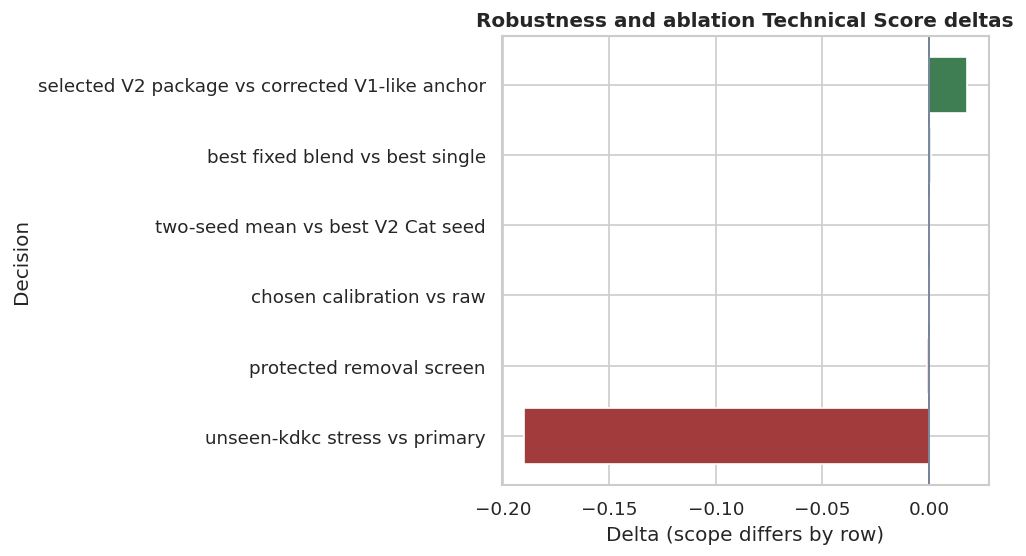

*Figure 4.11. Robustness deltas; screening and stress rows are not directly comparable to full primary CV.*

**Question.** Would the main decision change under reasonable perturbations?

**Method.** Full feature-family and seed comparisons, protected/suspicious screens, calibration and blend sensitivity, importance×shift, capacity curves, and an unseen-location holdout target consequential assumptions.

**Result.** Protected removal changes two-fold screen Technical Score by **-0.00081**. Unseen-location stress scores **0.73084**, a **-0.19025** difference from primary CatBoost OOF. The largest importance×shift feature is `umur`.

**Decision implication.** Competition submission follows the primary same-distribution evidence, while deployment to new locations requires shadow validation, location-specific monitoring, and potentially hierarchical or updated models.

**Limitation / alternative explanation.** The protected and suspicious removals are two-fold screens; only a decision-changing signal warrants the extra full-CV compute. Location holdout also changes both geography and case mix.

In [32]:
stress_fit, stress_valid, _, stress_features = add_frequency_features(
    train_model.iloc[LOCATION_TRAIN_IDX], train_model.iloc[LOCATION_VALID_IDX], None,
    SELECTED_V2_FEATURE_COLUMNS, SELECTED_USE_FREQUENCY,
)
stress_prediction, _, _, _, stress_fallback = fit_predict_fold(
    "CatBoost", stress_fit, y[LOCATION_TRAIN_IDX], stress_valid, y[LOCATION_VALID_IDX], None,
    stress_features, CFG.seed + 950, SELECTED_CAT_PARAMS,
)
stress_metric = augmented_raw_metrics(
    y[LOCATION_VALID_IDX], stress_prediction, PROTECTED.iloc[LOCATION_VALID_IDX].reset_index(drop=True),
    TIE_KEYS[LOCATION_VALID_IDX],
)
primary_cat_raw = CV_RESULTS["CatBoost V2 seed 2026"]["record"]
LOCATION_STRESS = pd.DataFrame([
    {"perspective":"primary grouped OOF (raw probabilities)", "claims":len(y), **{k:primary_cat_raw[k] for k in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]}, "fallback":"none"},
    {"perspective":"unseen kdkc holdout", "claims":len(LOCATION_VALID_IDX), **{k:stress_metric[k] for k in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "ProtectionScore", "TechnicalScore"]}, "fallback":stress_fallback},
])

SHIFT_IMPORTANCE = SHIFT_TABLE.merge(GLOBAL_IMPORTANCE[["feature", "native_importance_mean"]], on="feature", how="left").fillna({"native_importance_mean":0})
SHIFT_IMPORTANCE["importance_x_shift"] = SHIFT_IMPORTANCE.native_importance_mean * SHIFT_IMPORTANCE.shift_magnitude
SHIFT_IMPORTANCE = SHIFT_IMPORTANCE.sort_values("importance_x_shift", ascending=False)

ROBUSTNESS_SUMMARY = pd.DataFrame([
    ("selected V2 package vs corrected V1-like anchor", feature_delta, "full 5-fold", package_status),
    ("two-seed mean vs best V2 Cat seed", seed_gain, "full 5-fold", "SUPPORTED" if seed_gain >= 0.0005 else "INCONCLUSIVE"),
    ("chosen calibration vs raw", 0.15 * calibration_gain, "outer-fold cross-fit", "SUPPORTED" if calibration_gain >= 0.00005 else "REJECTED"),
    ("best fixed blend vs best single", best_blend_gain, "full OOF fixed formula", "SUPPORTED" if len(blend_rows) and best_blend_gain >= 0.00075 else "REJECTED"),
    ("protected removal screen", protected_summary["TechnicalScore"] - base_screen["TechnicalScore"], "same first 2 folds", "sensitivity"),
    ("unseen-kdkc stress vs primary", stress_metric["TechnicalScore"] - primary_cat_raw["TechnicalScore"], "separate raw-probability transport split", "stress only"),
], columns=["decision", "TechnicalScore_delta", "evidence_scope", "classification"])

show_table(ABLATION_SCREEN, "4.37", "Feature-removal screen on common CatBoost screening folds")
show_table(FEATURE_HYPOTHESIS_RESULTS, "4.37b", "Feature-family hypotheses and same-fold ablation evidence")
show_table(LOCATION_STRESS, "4.38", "Primary grouped OOF and unseen-location transport stress")
show_table(SHIFT_IMPORTANCE.head(15), "4.39", "Cross-reference of raw-feature shift and CatBoost importance")
show_table(ROBUSTNESS_SUMMARY, "4.40", "Decision-changing robustness summary")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
robust_plot = ROBUSTNESS_SUMMARY.sort_values("TechnicalScore_delta")
ax.barh(robust_plot.decision, robust_plot.TechnicalScore_delta, color=np.where(robust_plot.TechnicalScore_delta >= 0, COLORS["green"], COLORS["red"]))
ax.axvline(0, color=COLORS["gray"], linewidth=1)
ax.set(title="Robustness and ablation Technical Score deltas", xlabel="Delta (scope differs by row)", ylabel="Decision")
finish_figure(fig, "4.11", "Robustness deltas; screening and stress rows are not directly comparable to full primary CV.")

location_delta = float(stress_metric["TechnicalScore"] - primary_cat_raw["TechnicalScore"])
hierarchy_row = FEATURE_HYPOTHESIS_RESULTS[FEATURE_HYPOTHESIS_RESULTS.ID.eq("F1")].iloc[0]
screen_positive_feature_families = FEATURE_HYPOTHESIS_RESULTS[FEATURE_HYPOTHESIS_RESULTS.screen_status.eq("SCREEN_POSITIVE")].ID.tolist()
set_hypothesis("H02", "INCONCLUSIVE", f"code-hierarchy screen={hierarchy_row.screen_status}, contribution={hierarchy_row.feature_contribution:+.5f}; semantic strings remain a verified data-contract correction")
set_hypothesis(
    "H04", "INCONCLUSIVE",
    f"screen-positive feature families={screen_positive_feature_families or 'none'}; selected full V2 package delta={feature_delta:+.5f}; family evidence remains two-fold screening",
)
set_hypothesis("H08", "SUPPORTED" if location_delta < -0.01 else "INCONCLUSIVE", f"unseen-kdkc stress minus primary CatBoost={location_delta:+.5f}; prior location-removal evidence also large")
report_block(
    "Would the main decision change under reasonable perturbations?",
    "Full feature-family and seed comparisons, protected/suspicious screens, calibration and blend sensitivity, importance×shift, capacity curves, and an unseen-location holdout target consequential assumptions.",
    f"Protected removal changes two-fold screen Technical Score by **{protected_summary['TechnicalScore'] - base_screen['TechnicalScore']:+.5f}**. "
    f"Unseen-location stress scores **{stress_metric['TechnicalScore']:.5f}**, a **{location_delta:+.5f}** difference from primary CatBoost OOF. "
    f"The largest importance×shift feature is `{SHIFT_IMPORTANCE.iloc[0].feature}`.",
    "Competition submission follows the primary same-distribution evidence, while deployment to new locations requires shadow validation, location-specific monitoring, and potentially hierarchical or updated models.",
    "The protected and suspicious removals are two-fold screens; only a decision-changing signal warrants the extra full-CV compute. Location holdout also changes both geography and case mix."
)
TABLES.update({"A.ablation_screen":ABLATION_SCREEN, "A.feature_hypotheses":FEATURE_HYPOTHESIS_RESULTS, "A.location_stress":LOCATION_STRESS, "A.shift_importance":SHIFT_IMPORTANCE, "A.robustness":ROBUSTNESS_SUMMARY})


## 4.14 Final Fold Ensemble, Diversified Candidate, and Submission

The primary prediction is the fold average of the automatically selected candidate, followed by its single OOF-fitted calibrator. A second submission is created only from another validated fold candidate that is OOF-proximate yet meaningfully different around the test audit boundary. The unvalidated full-data-refit hedge was rejected because its probability scale and portfolio would not share the fold-ensemble OOF evidence.


**Table 4.41. Runtime submission portfolio decision**

,role,candidate,path,reason
0,primary,CatBoost V2 seed 2127,/kaggle/working/submission_primary.csv,highest eligible robust OOF evidence under predeclared rule
1,secondary,not produced,—,no alternative met both OOF-proximity and diversity safeguards


**Table 4.42. Primary-versus-alternative evaluation prediction diversity**

,candidate,OOF_TechnicalScore,Pearson,Spearman,top3_overlap,top5_overlap,top7_overlap,source
0,CatBoost V2 seed 2026,0.9211,0.9983,0.9983,0.9559,0.9570,0.9643,validated fold candidate
1,CatBoost V2 seed mean,0.9226,0.9996,0.9996,0.9817,0.9785,0.9839,validated fold candidate
2,Cat seed mean + XGBoost probability blend w=0.9,0.9222,0.9991,0.9992,0.9575,0.9510,0.9618,validated fold candidate
3,Cat seed mean + XGBoost logit blend w=0.9,0.9226,0.9992,0.9992,0.9742,0.9695,0.9743,validated fold candidate
4,Cat seed mean + XGBoost rank blend w=0.9,0.9221,0.9987,0.9989,0.9592,0.9486,0.9586,validated fold candidate
5,Cat seed mean + LightGBM probability blend w=0.9,0.9226,0.9991,0.9992,0.9592,0.9555,0.9661,validated fold candidate
6,Cat seed mean + LightGBM logit blend w=0.9,0.9230,0.9992,0.9992,0.9742,0.9690,0.9729,validated fold candidate
7,Cat seed mean + LightGBM rank blend w=0.9,0.9226,0.9989,0.9991,0.9592,0.9565,0.9650,validated fold candidate


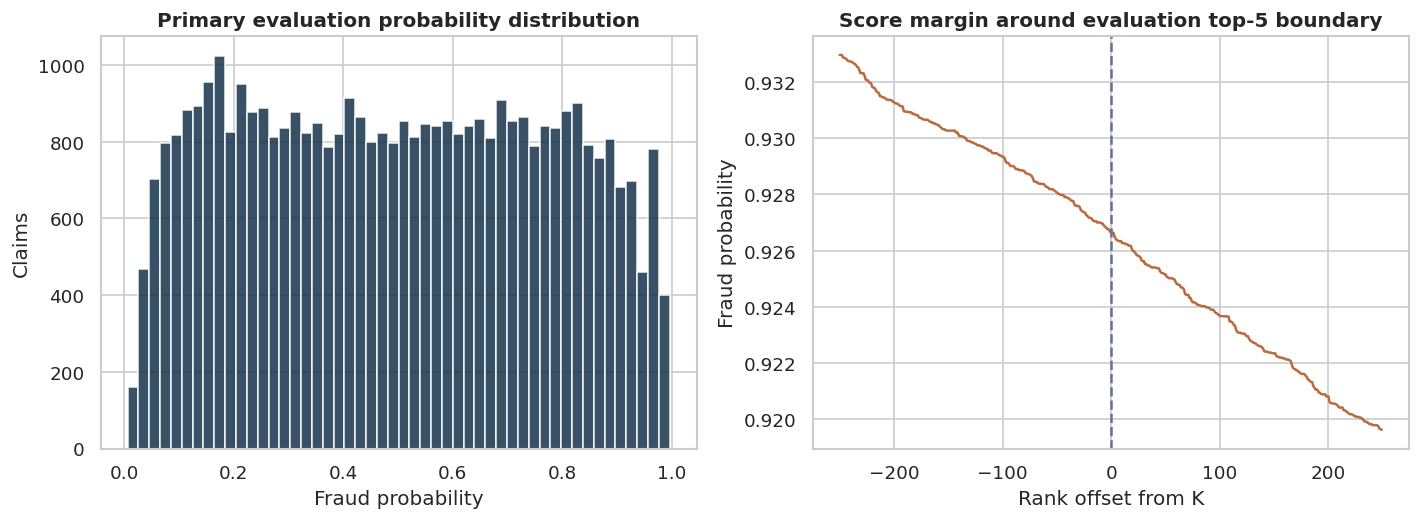

*Figure 4.12. Primary test probability distribution and local audit-boundary margin.*

The validated primary file is **`/kaggle/working/submission_primary.csv`** with 40,043 rows. No secondary file is produced because no candidate met the predeclared OOF-proximity and test-diversity rule. No prediction was manually changed.

In [33]:
primary_score = float(EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.selected, "TechnicalScore"].iloc[0])
alternative_rows = []
for name, candidate in CANDIDATES.items():
    if name == FINAL_CHOICE or name not in CALIBRATION_RESULTS:
        continue
    score = float(EXPERIMENT_REGISTRY.loc[EXPERIMENT_REGISTRY.experiment_id.eq(name), "TechnicalScore"].iloc[0])
    if score < primary_score - 0.0025:
        continue
    prediction = CALIBRATION_RESULTS[name]["deployment_test"]
    alternative_rows.append({
        "candidate":name, "OOF_TechnicalScore":score,
        "Pearson":np.corrcoef(FINAL_TEST_PROBABILITY, prediction)[0, 1],
        "Spearman":stats.spearmanr(FINAL_TEST_PROBABILITY, prediction).statistic,
        "top3_overlap":portfolio_overlap(FINAL_TEST_PROBABILITY, prediction, 0.03, TEST_TIE_KEYS),
        "top5_overlap":portfolio_overlap(FINAL_TEST_PROBABILITY, prediction, 0.05, TEST_TIE_KEYS),
        "top7_overlap":portfolio_overlap(FINAL_TEST_PROBABILITY, prediction, 0.07, TEST_TIE_KEYS),
        "prediction":prediction, "source":"validated fold candidate",
    })

eligible_alternatives = [row for row in alternative_rows if row["top5_overlap"] <= 0.93 and row["Spearman"] <= 0.997]
SECONDARY = max(eligible_alternatives, key=lambda row:row["OOF_TechnicalScore"]) if eligible_alternatives else None

submission_secondary = None
if SECONDARY is not None:
    submission_secondary = pd.DataFrame({ID_COL:sample_submission[ID_COL], "fraud_probability":SECONDARY["prediction"]})
    validate_submission(submission_secondary)
    submission_secondary.to_csv(SECONDARY_SUBMISSION_PATH, index=False)
elif SECONDARY_SUBMISSION_PATH.exists():
    SECONDARY_SUBMISSION_PATH.unlink()

PREDICTION_COMPARISON = pd.DataFrame([{k:v for k,v in row.items() if k != "prediction"} for row in alternative_rows])
MODEL_DECISION_TABLE = pd.DataFrame([
    {"role":"primary", "candidate":FINAL_CHOICE, "path":str(PRIMARY_SUBMISSION_PATH), "reason":SELECTION_FALLBACK_REASON or "highest eligible robust OOF evidence under predeclared rule"},
    {"role":"secondary", "candidate":SECONDARY["candidate"] if SECONDARY else "not produced", "path":str(SECONDARY_SUBMISSION_PATH) if SECONDARY else "—", "reason":"meaningful OOF-proximate top-5 diversity" if SECONDARY else "no alternative met both OOF-proximity and diversity safeguards"},
])

show_table(MODEL_DECISION_TABLE, "4.41", "Runtime submission portfolio decision")
show_table(PREDICTION_COMPARISON if len(PREDICTION_COMPARISON) else pd.DataFrame([{"result":"no eligible alternative entered comparison"}]), "4.42", "Primary-versus-alternative evaluation prediction diversity")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(FINAL_TEST_PROBABILITY, bins=50, color=COLORS["navy"], alpha=0.85)
axes[0].set(title="Primary evaluation probability distribution", xlabel="Fraud probability", ylabel="Claims")
test_order = np.lexsort((TEST_TIE_KEYS, -FINAL_TEST_PROBABILITY)); test_k = int(np.floor(0.05 * len(test_model)))
window = test_order[max(0, test_k - 250):min(len(test_order), test_k + 250)]
axes[1].plot(np.arange(len(window)) - min(250, test_k), FINAL_TEST_PROBABILITY[window], color=COLORS["orange"])
axes[1].axvline(0, color=COLORS["gray"], linestyle="--")
axes[1].set(title="Score margin around evaluation top-5 boundary", xlabel="Rank offset from K", ylabel="Fraud probability")
finish_figure(fig, "4.12", "Primary test probability distribution and local audit-boundary margin.")

set_hypothesis(
    "H07", "INCONCLUSIVE",
    "fold averaging is the validated inference recipe; V1 artifacts show material fold-average/full-refit portfolio divergence, but supplied test labels cannot rank the two recipes",
)

display(Markdown(
    f"The validated primary file is **`{PRIMARY_SUBMISSION_PATH}`** with {len(submission_primary):,} rows. "
    + (f"A diversified secondary, **{SECONDARY['candidate']}**, is written to **`{SECONDARY_SUBMISSION_PATH}`**." if SECONDARY else "No secondary file is produced because no candidate met the predeclared OOF-proximity and test-diversity rule.")
    + " No prediction was manually changed."
))
TABLES.update({"A.model_decision":MODEL_DECISION_TABLE, "A.prediction_comparison":PREDICTION_COMPARISON})


## 4.15 Operational Implications

The analytical result is a queue, not an enforcement action. Each alert should combine the calibrated score, rank and capacity status, raw supporting fields, the largest signed model drivers, data-quality warnings, comparable historic patterns, and links to source documentation. Investigators must be able to override with a reason code, request additional evidence, escalate uncertain cases, and route an appeal to a reviewer who was not responsible for the initial decision.

Monitoring must preserve a small policy-approved random review stream. Without it, labels become selected by the model's own queue and future evaluation will be biased toward previously suspected cases. Confirmation, correction, override, appeal, and delay outcomes should be joined only after maturation and should never be fed back as unquestioned ground truth.


# CHAPTER V: Conclusion and Recommendation

## 5.1 Conclusion

Conclusions below are generated from executed evidence and answer every research question. They do not claim private-leaderboard improvement before Kaggle evaluation.


In [34]:
selected_five = AUDIT_ALLOCATION[(AUDIT_ALLOCATION.strategy == FINAL_CHOICE) & np.isclose(AUDIT_ALLOCATION.capacity, 0.05)].iloc[0]
top_error_feature = ERROR_CONTRASTS.sort_values("abs_SMD", ascending=False).iloc[0].feature
top_shift_feature = SHIFT_TABLE.iloc[0].feature
top_driver = GLOBAL_IMPORTANCE.iloc[0].feature
v1_delta = selected_row.TechnicalScore - v1_row.TechnicalScore

CONCLUSION_TABLE = pd.DataFrame([
    ("RQ1 — data quality", f"{len(train_raw):,} train and {len(test_raw):,} test claims; {REPORT_FACTS['missing_cells']:,} missing cells; {REPORT_FACTS['repeated_signature_rows']:,} rows in repeated signatures; {REPORT_FACTS['conflicting_signatures']:,} conflicting signature groups; source labels have {REPORT_FACTS['label_transitions']} transition(s).", "Group templates, preserve code strings, exclude source order/ID, review extremes without causal claims."),
    ("RQ2 — validation", f"{PRIMARY_VALIDATION}; zero exact-signature overlap; ordinary CV would repeat {ordinary_overlap:,} signature groups; unseen-kdkc stress delta {location_delta:+.5f}.", "Use grouped CV for competition selection and location holdout only as transport stress."),
    ("RQ3 — V1 diagnosis", "Source-order ties, fold-specific calibration rank distortion, OOF/deployment blend mismatch, ordinal XGBoost categories, maxed Cat iterations, and full-refit/fold-average portfolio divergence are verified.", "V1 remains a strong anchor, not the preserved architecture."),
    ("RQ4 — features", f"V2 CatBoost seed-2026 package Technical Score delta versus the corrected V1-like anchor is {feature_delta:+.5f}; screen-positive families={screen_positive_feature_families or 'none'}; leading error contrast is {top_error_feature}.", "Screening controls the finalist feature set; family-level claims remain provisional unless confirmed by full CV. Individual importances are not causal."),
    ("RQ5 — model", f"Selected {FINAL_CHOICE}: TS={selected_row.TechnicalScore:.5f}, NR5={selected_row['NormalizedRecall@5%']:.5f}, AP={selected_row.AveragePrecision:.5f}, fold SD={selected_row.fold_SD:.5f}.", "Deploy the exact fold-ensemble formula and retain the experiment registry."),
    ("RQ6 — calibration", f"Folds 1–3 selected {FINAL_CALIBRATION['chosen']} (Brier gain {selection_calibration_gain:+.6f}); all-OOF Brier {chosen_brier:.6f} versus raw {raw_brier:.6f}; confirmation Brier {confirmation_chosen_brier:.6f}; isotonic is diagnostic-only.", "Use one OOF-fitted deployment calibrator; recalibrate prospectively if reliability drifts."),
    ("RQ7 — allocation", f"At 5%, K={int(selected_five.K):,}, fraud captured={int(selected_five.fraud_captured):,}, legitimate audits={int(selected_five.legitimate_audits):,}, lift={selected_five.lift_over_random:.3f}×.", "Show 3/5/7% workload curves and preserve random review for unbiased monitoring."),
    ("RQ8 — errors", f"Near-boundary V1 fraud={int(near_boundary.sum()):,}; strongest standardized error contrast={top_error_feature}; leading V2 driver={top_driver}.", "Route error patterns into feature tests and investigator evidence, never manual test-score edits."),
    ("RQ9 — protection", f"At 5%, gender gap={five_gap.Gap_gender:.6f}, age gap={five_gap.Gap_age:.6f}, Protection={five_gap.ProtectionScore:.6f}.", "Monitor denominators, Wilson intervals, outcomes, delays, overrides, and appeals; disparity is not proof of discrimination."),
    ("RQ10 — operations", f"Largest raw train–test shift={top_shift_feature}; adversarial AUC={ADVERSARIAL_AUC:.4f}; secondary={'produced' if SECONDARY else 'withheld'}.", "Use human review, escalation, appeal, outcome maturation, drift/calibration/fairness monitoring, versioning, and rollback."),
], columns=["Research question", "Executed answer", "Decision"])
show_table(CONCLUSION_TABLE, "5.1", "Evidence-backed answers to the research questions")

display(Markdown(
    f"**V1 → V2 conclusion.** Under the same corrected primary validation, the selected V2 candidate changes "
    f"Technical Score by **{v1_delta:+.5f}** versus the corrected V1-like anchor. This is classified through Table 4.27 and must be "
    "interpreted with fold/paired uncertainty. It is evidence about expected generalization—not a claim that the private leaderboard score is already higher."
))


**Table 5.1. Evidence-backed answers to the research questions**

,Research question,Executed answer,Decision
0,RQ1 — data quality,"160,174 train and 40,043 test claims; 0 missing cells; 17,906 rows in repeated signatures; 1,737 conflicting signature groups; source labels have 1 transition(s).","Group templates, preserve code strings, exclude source order/ID, review extremes without causal claims."
1,RQ2 — validation,"StratifiedGroupKFold by exact cleaned feature signature; zero exact-signature overlap; ordinary CV would repeat 13,092 signature groups; unseen-kdkc stress delta -0.19025.",Use grouped CV for competition selection and location holdout only as transport stress.
2,RQ3 — V1 diagnosis,"Source-order ties, fold-specific calibration rank distortion, OOF/deployment blend mismatch, ordinal XGBoost categories, maxed Cat iterations, and full-refit/fold-average portfolio divergence are verified.","V1 remains a strong anchor, not the preserved architecture."
3,RQ4 — features,"V2 CatBoost seed-2026 package Technical Score delta versus the corrected V1-like anchor is +0.01769; screen-positive families=['F3', 'F4', 'F5']; leading error contrast is procedure_per_day.",Screening controls the finalist feature set; family-level claims remain provisional unless confirmed by full CV. Individual importances are not causal.
4,RQ5 — model,"Selected CatBoost V2 seed 2127: TS=0.92246, NR5=0.97053, AP=0.82318, fold SD=0.00273.",Deploy the exact fold-ensemble formula and retain the experiment registry.
5,RQ6 — calibration,Folds 1–3 selected raw (Brier gain +0.000000); all-OOF Brier 0.172383 versus raw 0.172383; confirmation Brier 0.172840; isotonic is diagnostic-only.,Use one OOF-fitted deployment calibrator; recalibrate prospectively if reliability drifts.
6,RQ7 — allocation,"At 5%, K=8,008, fraud captured=7,772, legitimate audits=236, lift=1.938×.",Show 3/5/7% workload curves and preserve random review for unbiased monitoring.
7,RQ8 — errors,"Near-boundary V1 fraud=2,840; strongest standardized error contrast=procedure_per_day; leading V2 driver=geo__facility.","Route error patterns into feature tests and investigator evidence, never manual test-score edits."
8,RQ9 — protection,"At 5%, gender gap=0.000106, age gap=0.001153, Protection=0.998847.","Monitor denominators, Wilson intervals, outcomes, delays, overrides, and appeals; disparity is not proof of discrimination."
9,RQ10 — operations,Largest raw train–test shift=proc39_45; adversarial AUC=0.5068; secondary=withheld.,"Use human review, escalation, appeal, outcome maturation, drift/calibration/fairness monitoring, versioning, and rollback."


**V1 → V2 conclusion.** Under the same corrected primary validation, the selected V2 candidate changes Technical Score by **+0.01905** versus the corrected V1-like anchor. This is classified through Table 4.27 and must be interpreted with fold/paired uncertainty. It is evidence about expected generalization—not a claim that the private leaderboard score is already higher.

## 5.2 Recommendation

### 5.2.1 Investigator Interface and Decision Rights

For every queued claim, show:

1. calibrated fraud-investigation probability, percentile rank, and whether the claim falls inside the current capacity;
2. submitted claim evidence—service, facility, diagnosis, procedure-group counts, severity, stay, and location fields—with provenance and timestamps;
3. the largest signed local model contributions, explicitly labeled as model associations;
4. missing, unseen-category, implausibility, and drift warnings;
5. comparable historical patterns and applicable policy/rule checks;
6. prior review history, conflicts, and attachments available to the authorized investigator.

The investigator—not the model—determines whether evidence supports escalation. Require structured reason codes for confirmation, closure, override, request-for-information, and escalation. Prohibit denial solely from the score or SHAP values.

### 5.2.2 Escalation, Override, and Appeal

- Permit override in both directions with a recorded reason, evidence, actor, and time.
- Escalate high-impact or ambiguous cases to a senior reviewer independent of the first decision.
- Notify affected parties through the lawful operational process, distinguish review from allegation, and provide a documented channel to submit evidence.
- Route appeals to a reviewer not responsible for the initial action; track time to resolution and successful-appeal rate.
- Audit override patterns for automation bias, investigator inconsistency, retaliation risk, and subgroup burden.

### 5.2.3 Learning Without a Feedback Trap

Maintain a small, policy-approved random or risk-stratified review sample outside the top queue. Without exploration, future labels are conditional on the model's past selections and cannot estimate population performance. Define label maturity, adjudication quality, reversals, and ambiguous outcomes before retraining. Never treat an investigation referral itself as a fraud label.

### 5.2.4 Change Control

Version the data contract, features, folds, code, model parameters, calibrator, thresholds, and investigator policy together. Require independent review, shadow evaluation, fairness/calibration checks, approval, rollback, and a model card before each production release. Re-run the complete leakage and source-order audit after any upstream extract change [25], [26], [30].


In [35]:
MONITORING_PLAN = pd.DataFrame([
    ("input contract", "row counts, dtypes, ranges, missingness, leading zeros, unseen levels, duplicate/template rates", "this run's quality_profile.csv", "any contract failure; investigate distribution alerts before scoring"),
    ("covariate shift", "KS, |SMD|, JS divergence, adversarial AUC, importance×shift", f"AUC={ADVERSARIAL_AUC:.4f}; max feature={top_shift_feature}", "sustained shift linked to errors or outside the validated envelope"),
    ("ranking", "NR@3/5/7%, AP, cumulative gain, top-boundary stability", f"NR5={selected_row['NormalizedRecall@5%']:.5f}; AP={selected_row.AveragePrecision:.5f}", "mature-label estimate breaches the validation uncertainty band or declines repeatedly"),
    ("calibration", "Brier, reliability curve, intercept/slope, score histogram", f"method={FINAL_CALIBRATION['chosen']}; Brier={chosen_brier:.6f}", "material Brier degradation or systematic reliability deviation on a representative matured window"),
    ("protection", "eligible gender/age FPR, Wilson intervals, gaps, delays, confirmations, overrides, appeals", f"gender gap={five_gap.Gap_gender:.6f}; age gap={five_gap.Gap_age:.6f}", "gap exceeds policy tolerance, changes materially from baseline, or burden/outcomes diverge"),
    ("portfolio", "alert volume, score boundary, ties, churn, investigator capacity", f"K={int(selected_five.K):,}; boundary ties={int(selected_five.boundary_tie_size)}", "queue exceeds capacity or boundary churn/ties increase materially"),
    ("process", "review time, evidence requests, overrides, escalations, appeals, successful appeals", "establish during shadow deployment", "sustained burden, inconsistency, or adverse-outcome signal"),
    ("labels", "maturity, adjudicator agreement, reversals, unresolved rate, selection mechanism", "document before launch", "label definition or investigation policy changes"),
    ("concept", "feature–outcome relations, fraud typologies, performance by time/location", f"unseen-kdkc stress TS={stress_metric['TechnicalScore']:.5f}", "error-linked relationship change, new typology, or transport failure"),
    ("system", "latency, failures, version, access, audit log, rollback readiness", "versioned notebook artifacts", "data loss, unauthorized access, unexplained version mismatch, or failed rollback drill"),
], columns=["domain", "measure", "reference", "investigate / act when"])
MONITORING_PLAN["owner"] = MONITORING_PLAN.domain.map({
    "input contract":"data engineering", "covariate shift":"model risk", "ranking":"model validation",
    "calibration":"model validation", "protection":"fairness/governance", "portfolio":"investigation operations",
    "process":"investigation quality", "labels":"fraud adjudication lead", "concept":"model risk", "system":"ML platform/security",
})
MONITORING_PLAN["cadence"] = MONITORING_PLAN.domain.map({
    "input contract":"every batch", "covariate shift":"weekly", "ranking":"monthly after label maturity",
    "calibration":"monthly after label maturity", "protection":"monthly and release gate", "portfolio":"daily",
    "process":"weekly", "labels":"monthly", "concept":"quarterly or incident-triggered", "system":"continuous",
})
MONITORING_PLAN["evaluation window"] = MONITORING_PLAN.domain.map({
    "input contract":"current batch", "covariate shift":"rolling 4 weeks", "ranking":"latest matured 8–12 weeks",
    "calibration":"latest matured 8–12 weeks", "protection":"latest matured quarter with group denominators",
    "portfolio":"current day plus rolling 4 weeks", "process":"rolling 4 weeks", "labels":"latest matured quarter",
    "concept":"rolling two quarters by location/typology", "system":"current event plus rolling 30 days",
})
show_table(MONITORING_PLAN, "5.2", "Production monitoring and investigation plan")


**Table 5.2. Production monitoring and investigation plan**

,domain,measure,reference,investigate / act when,owner,cadence,evaluation window
0,input contract,"row counts, dtypes, ranges, missingness, leading zeros, unseen levels, duplicate/template rates",this run's quality_profile.csv,any contract failure; investigate distribution alerts before scoring,data engineering,every batch,current batch
1,covariate shift,"KS, |SMD|, JS divergence, adversarial AUC, importance×shift",AUC=0.5068; max feature=proc39_45,sustained shift linked to errors or outside the validated envelope,model risk,weekly,rolling 4 weeks
2,ranking,"NR@3/5/7%, AP, cumulative gain, top-boundary stability",NR5=0.97053; AP=0.82318,mature-label estimate breaches the validation uncertainty band or declines repeatedly,model validation,monthly after label maturity,latest matured 8–12 weeks
3,calibration,"Brier, reliability curve, intercept/slope, score histogram",method=raw; Brier=0.172383,material Brier degradation or systematic reliability deviation on a representative matured window,model validation,monthly after label maturity,latest matured 8–12 weeks
4,protection,"eligible gender/age FPR, Wilson intervals, gaps, delays, confirmations, overrides, appeals",gender gap=0.000106; age gap=0.001153,"gap exceeds policy tolerance, changes materially from baseline, or burden/outcomes diverge",fairness/governance,monthly and release gate,latest matured quarter with group denominators
5,portfolio,"alert volume, score boundary, ties, churn, investigator capacity","K=8,008; boundary ties=1",queue exceeds capacity or boundary churn/ties increase materially,investigation operations,daily,current day plus rolling 4 weeks
6,process,"review time, evidence requests, overrides, escalations, appeals, successful appeals",establish during shadow deployment,"sustained burden, inconsistency, or adverse-outcome signal",investigation quality,weekly,rolling 4 weeks
7,labels,"maturity, adjudicator agreement, reversals, unresolved rate, selection mechanism",document before launch,label definition or investigation policy changes,fraud adjudication lead,monthly,latest matured quarter
8,concept,"feature–outcome relations, fraud typologies, performance by time/location",unseen-kdkc stress TS=0.73084,"error-linked relationship change, new typology, or transport failure",model risk,quarterly or incident-triggered,rolling two quarters by location/typology
9,system,"latency, failures, version, access, audit log, rollback readiness",versioned notebook artifacts,"data loss, unauthorized access, unexplained version mismatch, or failed rollback drill",ML platform/security,continuous,current event plus rolling 30 days


### 5.2.5 Recalibration, Retraining, and Deployment Sequence

Recalibrate when ranking remains acceptable but reliability degrades on a sufficiently large, representative, matured, adjudicated window. Retrain when ranking degrades, feature–outcome relationships change, new fraud typologies appear, the label policy changes, or transport evidence fails—not merely because a calendar date arrives. Every material update repeats validation, leakage, tie, calibration, explanation, protection, and shadow-workflow review.

Recommended sequence:

1. reproduce this notebook and validate every output contract;
2. conduct shadow scoring without changing claim outcomes;
3. retain a governance-approved random review stream and mature outcomes;
4. review calibration, errors, subgroup exposure, location transport, and investigator usability;
5. pilot the ranked queue with logged human override, independent escalation, appeal, and rollback;
6. expand only after pre-specified effectiveness, protection, burden, and reliability evidence is acceptable.

## 5.3 Limitations

The organizer provides no verified event time, provider/policyholder entity key, cost matrix, label-generation protocol, or operational prevalence. Exact-signature grouping cannot recover those structures. Labels may contain investigation selection, adjudication error, unresolved cases, or deliberate class sampling. Consequently, OOF calibration applies to the labeled competition distribution and may require operational prevalence-aware recalibration.

The two screening folds are reused inside the three-fold selection view, so reported full-OOF performance remains selection-conditioned. Folds 4–5 provide a predeclared veto and every scored row remains held out from its own base model, but standard pooled OOF predictions do not constitute fully nested validation of the entire feature/blend/calibration search. The conditional signature-cluster bootstrap holds predictions fixed and does not include model refitting or search uncertainty.

The primary stress split changes location and case mix together. Protected-group evaluation covers only recorded gender and the four official age bands, excludes small legitimate groups by rule, and does not capture every form of inequity or intersectional harm. Wilson intervals quantify binomial sampling, not structural uncertainty. Importance and SHAP are associative. GPU CatBoost is nondeterministic at the arithmetic level, so seed evidence is empirical rather than bitwise reproducibility [31].

Finally, public leaderboard 0.95833 is a coarse signal with unknown public/private partition variance. No hidden test label has been inferred, and no V2 leaderboard claim is made here. Private performance can be known only after submitting the generated files under competition rules.


# REFERENCES

[1] DAC 2026 Competition Committee, “Preliminary-Round Competition Specification and Evaluation Rules,” official competition material supplied to participants, 2026.

[2] World Health Organization, *Use of Machine Learning for Fraud Detection within the Claims Management Process in the Philippines: Insights from the National Health Insurance Scheme PhilHealth*. Geneva, Switzerland: WHO, 2024, ISBN 978-92-4-010133-3. [Online]. Available: https://www.who.int/publications/i/item/9789240101333

[3] World Health Organization, *The Implications of Artificial Intelligence and Machine Learning in Health Financing for Achieving Universal Health Coverage: Findings from a Rapid Literature Review*. Geneva, Switzerland: WHO, 2023, ISBN 978-92-4-006401-0. [Online]. Available: https://www.who.int/publications/i/item/9789240064010

[4] A. du Preez, S. Bhattacharya, P. A. Beling, and E. Bowen, “Fraud detection in healthcare claims using machine learning: A systematic review,” *Artificial Intelligence in Medicine*, vol. 160, Art. no. 103061, 2025, doi: 10.1016/j.artmed.2024.103061.

[5] H. Joudaki, A. Rashidian, B. Minaei-Bidgoli, M. Mahmoodi, B. Geraili, M. Nasiri, M. Arab, and E. Qorbani, “Using data mining to detect health care fraud and abuse: A review of literature,” *Global Journal of Health Science*, vol. 7, no. 1, pp. 194–202, 2015, doi: 10.5539/gjhs.v7n1p194.

[6] J. Davis and M. Goadrich, “The relationship between Precision-Recall and ROC curves,” in *Proc. 23rd International Conference on Machine Learning*, 2006, pp. 233–240, doi: 10.1145/1143844.1143874.

[7] T. Saito and M. Rehmsmeier, “The Precision-Recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets,” *PLOS ONE*, vol. 10, no. 3, Art. no. e0118432, 2015, doi: 10.1371/journal.pone.0118432.

[8] G. W. Brier, “Verification of forecasts expressed in terms of probability,” *Monthly Weather Review*, vol. 78, no. 1, pp. 1–3, 1950, doi: 10.1175/1520-0493(1950)078&lt;0001:VOFEIT&gt;2.0.CO;2.

[9] B. Van Calster, D. J. McLernon, M. van Smeden, L. Wynants, and E. W. Steyerberg, “Calibration: The Achilles heel of predictive analytics,” *BMC Medicine*, vol. 17, Art. no. 230, 2019, doi: 10.1186/s12916-019-1466-7.

[10] M. Kull, T. M. Silva Filho, and P. Flach, “Beta calibration: A well-founded and easily implemented improvement on logistic calibration for binary classifiers,” in *Proc. 20th International Conference on Artificial Intelligence and Statistics*, PMLR, vol. 54, 2017, pp. 623–631. [Online]. Available: https://proceedings.mlr.press/v54/kull17a.html

[11] S. Kaufman, S. Rosset, C. Perlich, and O. Stitelman, “Leakage in data mining: Formulation, detection, and avoidance,” *ACM Transactions on Knowledge Discovery from Data*, vol. 6, no. 4, Art. no. 15, 2012, doi: 10.1145/2382577.2382579.

[12] D. R. Roberts *et al.*, “Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure,” *Ecography*, vol. 40, no. 8, pp. 913–929, 2017, doi: 10.1111/ecog.02881.

[13] G. C. Cawley and N. L. C. Talbot, “On over-fitting in model selection and subsequent selection bias in performance evaluation,” *Journal of Machine Learning Research*, vol. 11, pp. 2079–2107, 2010. [Online]. Available: https://www.jmlr.org/papers/v11/cawley10a.html

[14] J. H. Friedman, “Greedy function approximation: A gradient boosting machine,” *The Annals of Statistics*, vol. 29, no. 5, pp. 1189–1232, 2001, doi: 10.1214/aos/1013203451.

[15] L. Prokhorenkova, G. Gusev, A. Vorobev, A. V. Dorogush, and A. Gulin, “CatBoost: Unbiased boosting with categorical features,” in *Advances in Neural Information Processing Systems 31*, 2018. [Online]. Available: https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html

[16] T. Chen and C. Guestrin, “XGBoost: A scalable tree boosting system,” in *Proc. 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2016, pp. 785–794, doi: 10.1145/2939672.2939785.

[17] G. Ke *et al.*, “LightGBM: A highly efficient gradient boosting decision tree,” in *Advances in Neural Information Processing Systems 30*, 2017, pp. 3146–3154. [Online]. Available: https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html

[18] P. Kar, H. Narasimhan, and P. Jain, “Surrogate functions for maximizing precision at the top,” in *Proc. 32nd International Conference on Machine Learning*, PMLR, vol. 37, 2015, pp. 189–198. [Online]. Available: https://proceedings.mlr.press/v37/kar15.html

[19] A. Niculescu-Mizil and R. Caruana, “Predicting good probabilities with supervised learning,” in *Proc. 22nd International Conference on Machine Learning*, 2005, pp. 625–632, doi: 10.1145/1102351.1102430.

[20] M. Hardt, E. Price, and N. Srebro, “Equality of opportunity in supervised learning,” in *Advances in Neural Information Processing Systems 29*, 2016. [Online]. Available: https://proceedings.neurips.cc/paper/2016/hash/9d2682367c3935defcb1f9e247a97c0d-Abstract.html

[21] A. Rajkomar, M. Hardt, M. D. Howell, G. Corrado, and M. H. Chin, “Ensuring fairness in machine learning to advance health equity,” *Annals of Internal Medicine*, vol. 169, no. 12, pp. 866–872, 2018, doi: 10.7326/M18-1990.

[22] S. M. Lundberg and S.-I. Lee, “A unified approach to interpreting model predictions,” in *Advances in Neural Information Processing Systems 30*, 2017. [Online]. Available: https://proceedings.neurips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html

[23] I. E. Kumar, S. Venkatasubramanian, C. Scheidegger, and S. Friedler, “Problems with Shapley-value-based explanations as feature importance measures,” in *Proc. 37th International Conference on Machine Learning*, PMLR, vol. 119, 2020, pp. 5491–5500. [Online]. Available: https://proceedings.mlr.press/v119/kumar20e.html

[24] J. Amann, A. Blasimme, E. Vayena, D. Frey, and V. I. Madai, “Explainability for artificial intelligence in healthcare: A multidisciplinary perspective,” *BMC Medical Informatics and Decision Making*, vol. 20, Art. no. 310, 2020, doi: 10.1186/s12911-020-01332-6.

[25] World Health Organization, *Ethics and Governance of Artificial Intelligence for Health*. Geneva, Switzerland: WHO, 2021, ISBN 978-92-4-002920-0. [Online]. Available: https://www.who.int/publications/i/item/9789240029200

[26] E. Tabassi, *Artificial Intelligence Risk Management Framework (AI RMF 1.0)*, NIST AI 100-1. Gaithersburg, MD, USA: National Institute of Standards and Technology, 2023, doi: 10.6028/NIST.AI.100-1.

[27] J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy, and A. Bouchachia, “A survey on concept drift adaptation,” *ACM Computing Surveys*, vol. 46, no. 4, Art. no. 44, 2014, doi: 10.1145/2523813.

[28] B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*. New York, NY, USA: Chapman & Hall, 1993, doi: 10.1007/978-1-4899-4541-9.

[29] E. B. Wilson, “Probable inference, the law of succession, and statistical inference,” *Journal of the American Statistical Association*, vol. 22, no. 158, pp. 209–212, 1927, doi: 10.1080/01621459.1927.10502953.

[30] C. J. Kelly, A. Karthikesalingam, M. Suleyman, G. Corrado, and D. King, “Key challenges for delivering clinical impact with artificial intelligence,” *BMC Medicine*, vol. 17, Art. no. 195, 2019, doi: 10.1186/s12916-019-1426-2.

[31] CatBoost, “Training on GPU,” *CatBoost Documentation*. [Online]. Available: https://catboost.ai/docs/en/features/training-on-gpu. Accessed: Aug. 28, 2026.

[32] XGBoost Developers, “Using XGBoost with device CUDA,” *XGBoost Documentation*. [Online]. Available: https://xgboost.readthedocs.io/en/stable/gpu/index.html. Accessed: Aug. 28, 2026.


# ATTACHMENT

## A.1 Literature-to-Decision Matrix


In [36]:
LITERATURE_MATRIX = pd.DataFrame([
    ("[2]–[5]", "claims-fraud context, workflow, data/label constraints", "integrity audit, human review, limitations"),
    ("[6]–[10], [19]", "precision–recall and probability calibration", "AP, Brier, cross-fitted sigmoid/beta/isotonic"),
    ("[11]–[13]", "leakage, structured validation, model-selection bias", "signature groups, source-order audit, uncertainty rule"),
    ("[14]–[17]", "gradient boosting and categorical/tabular models", "CatBoost, one-hot XGBoost, LightGBM"),
    ("[18]", "direct top-k learning", "explains the ranking option and its evidence-based rejection"),
    ("[20], [21], [29]", "false-positive disparity, health equity, interval uncertainty", "official protection metrics and Wilson intervals"),
    ("[22]–[24]", "SHAP and limits of model explanation", "native, permutation, SHAP triangulation without causality"),
    ("[25]–[27], [30]", "human oversight, risk management, deployment, drift", "workflow, monitoring, appeal, recalibration, retraining"),
    ("[28]", "paired uncertainty", "conditional paired exact-signature-cluster bootstrap of consequential model differences"),
    ("[31], [32]", "supported GPU interfaces", "CatBoost devices 0:1 and CUDA XGBoost with fallbacks"),
], columns=["citations", "claim supported", "implementation consequence"])
show_table(LITERATURE_MATRIX, "A.1", "Verified literature connected to an implemented decision")


**Table A.1. Verified literature connected to an implemented decision**

,citations,claim supported,implementation consequence
0,[2]–[5],"claims-fraud context, workflow, data/label constraints","integrity audit, human review, limitations"
1,"[6]–[10], [19]",precision–recall and probability calibration,"AP, Brier, cross-fitted sigmoid/beta/isotonic"
2,[11]–[13],"leakage, structured validation, model-selection bias","signature groups, source-order audit, uncertainty rule"
3,[14]–[17],gradient boosting and categorical/tabular models,"CatBoost, one-hot XGBoost, LightGBM"
4,[18],direct top-k learning,explains the ranking option and its evidence-based rejection
5,"[20], [21], [29]","false-positive disparity, health equity, interval uncertainty",official protection metrics and Wilson intervals
6,[22]–[24],SHAP and limits of model explanation,"native, permutation, SHAP triangulation without causality"
7,"[25]–[27], [30]","human oversight, risk management, deployment, drift","workflow, monitoring, appeal, recalibration, retraining"
8,[28],paired uncertainty,conditional paired exact-signature-cluster bootstrap of consequential model differences
9,"[31], [32]",supported GPU interfaces,CatBoost devices 0:1 and CUDA XGBoost with fallbacks


## A.2 Reproducibility, Parameters, and Feature Roles


In [37]:
REPRODUCIBILITY = pd.DataFrame([
    ("configuration", json.dumps(asdict(CFG), default=str)),
    ("Python", platform.python_version()),
    ("pandas", pd.__version__),
    ("scikit-learn", __import__("sklearn").__version__),
    ("CatBoost", __import__("catboost").__version__),
    ("XGBoost", __import__("xgboost").__version__),
    ("LightGBM", __import__("lightgbm").__version__ if LIGHTGBM_AVAILABLE else "unavailable"),
    ("GPU", f"count={GPU_COUNT}; CatBoost={CAT_DEVICES or 'CPU'}; XGBoost={XGB_DEVICE}"),
    ("primary validation", PRIMARY_VALIDATION),
    ("train/test/sample", f"{TRAIN_PATH} | {TEST_PATH} | {SAMPLE_PATH}"),
    ("primary output", str(PRIMARY_SUBMISSION_PATH)),
    ("secondary output", str(SECONDARY_SUBMISSION_PATH) if SECONDARY else "not produced"),
], columns=["item", "value"])

PARAMETER_TABLE = pd.DataFrame([
    ("Burden", json.dumps(BURDEN_PARAMS, sort_keys=True)),
    ("Logistic", json.dumps(LOGISTIC_PARAMS, sort_keys=True)),
    ("Corrected V1-like CatBoost", json.dumps(V1_CAT_PARAMS, sort_keys=True)),
    (f"V2 CatBoost ({SELECTED_CAT_CONFIG})", json.dumps(SELECTED_CAT_PARAMS, sort_keys=True)),
    ("XGBoost one-hot", json.dumps(XGB_PARAMS, sort_keys=True)),
    ("LightGBM one-hot", json.dumps(LGBM_PARAMS, sort_keys=True) if LIGHTGBM_AVAILABLE else "unavailable"),
    ("Calibration", f"raw/sigmoid/beta/isotonic; selected={FINAL_CALIBRATION['chosen']}"),
    ("Selection", "folds 1–3 select, 4–5 confirm; tie penalty≤0.0005; ensemble gain≥0.00075, ≥3 total/≥1 confirmation win, overlap<0.985; complex winner needs positive cluster-bootstrap lower 95% bound; within 0.0005 prefer simpler"),
], columns=["component", "settings"])

feature_rows = []
for feature in [ID_COL, TARGET_COL] + list(dict.fromkeys(raw_feature_columns + [c for c in ALL_FEATURE_COLUMNS if c not in raw_feature_columns])):
    if feature == ID_COL: role, decision = "identifier", "alignment and neutral ties only"
    elif feature == TARGET_COL: role, decision = "target", "labels only"
    elif feature in CONSTANT_COLUMNS: role, decision = "constant", "excluded"
    elif feature in PROTECTED_FEATURES: role, decision = "protected/sensitive", "main model plus removal screen"
    elif feature in LOCATION_PROXY_FEATURES: role, decision = "location proxy", "main model plus transport stress"
    elif feature in V1_ENGINEERED_COLUMNS: role, decision = "V1 derived", "corrected V1-like anchor and V2"
    elif feature in V2_FEATURE_COLUMNS and feature not in raw_feature_columns: role, decision = "V2 hypothesis-derived", "V2 candidates"
    elif feature in CATEGORICAL_COLUMNS: role, decision = "categorical claim field", "retained"
    else: role, decision = "numeric claim field", "retained"
    feature_rows.append({"feature":feature, "role":role, "decision":decision})
FEATURE_DICTIONARY = pd.DataFrame(feature_rows)

show_table(REPRODUCIBILITY, "A.2", "Runtime and reproducibility record")
show_table(PARAMETER_TABLE, "A.3", "Complete model, calibration, and selection settings")
show_table(FEATURE_DICTIONARY, "A.4", "Feature-role dictionary")


**Table A.2. Runtime and reproducibility record**

,item,value
0,configuration,"{""seed"": 2026, ""folds"": 5, ""capacities"": [0.03, 0.05, 0.07], ""fast_mode"": false, ""v1_cat_iterations"": 2200, ""screen_iterations"": 1400, ""cat_iterations"": 3200, ""xgb_estimators"": 2600, ""lgbm_estimators"": 2600, ""early_stopping"": 220, ""bootstrap_repetitions"": 300, ""shap_sample"": 700, ""min_group_nonfraud"": 100}"
1,Python,3.12.13
2,pandas,2.3.3
3,scikit-learn,1.6.1
4,CatBoost,1.2.10
5,XGBoost,3.2.0
6,LightGBM,4.6.0
7,GPU,count=2; CatBoost=0:1; XGBoost=cuda
8,primary validation,StratifiedGroupKFold by exact cleaned feature signature
9,train/test/sample,/kaggle/input/competitions/dac-its-2026/train.csv | /kaggle/input/competitions/dac-its-2026/test.csv | /kaggle/input/competitions/dac-its-2026/sample_submission.csv


**Table A.3. Complete model, calibration, and selection settings**

,component,settings
0,Burden,"{""C"": 0.5, ""max_iter"": 500}"
1,Logistic,"{""C"": 0.5, ""max_iter"": 700}"
2,Corrected V1-like CatBoost,"{""bagging_temperature"": 0.8, ""border_count"": 128, ""depth"": 8, ""early_stopping"": 180, ""fixed_iterations"": true, ""iterations"": 2200, ""l2_leaf_reg"": 6.0, ""learning_rate"": 0.035, ""max_ctr_complexity"": 1, ""random_strength"": 0.5}"
3,V2 CatBoost (depth8_capacity),"{""bagging_temperature"": 0.5, ""border_count"": 128, ""depth"": 8, ""early_stopping"": 220, ""fixed_iterations"": true, ""iterations"": 2860, ""l2_leaf_reg"": 8.0, ""learning_rate"": 0.03, ""max_ctr_complexity"": 2, ""random_strength"": 0.35}"
4,XGBoost one-hot,"{""colsample_bytree"": 0.82, ""early_stopping"": 220, ""fixed_iterations"": true, ""learning_rate"": 0.035, ""max_depth"": 7, ""min_child_weight"": 6, ""n_estimators"": 2600, ""reg_alpha"": 0.08, ""reg_lambda"": 7.0, ""subsample"": 0.85}"
5,LightGBM one-hot,"{""colsample_bytree"": 0.82, ""early_stopping"": 220, ""fixed_iterations"": true, ""learning_rate"": 0.025, ""max_depth"": -1, ""min_child_samples"": 60, ""n_estimators"": 2600, ""num_leaves"": 48, ""reg_alpha"": 0.1, ""reg_lambda"": 7.0, ""subsample"": 0.85}"
6,Calibration,raw/sigmoid/beta/isotonic; selected=raw
7,Selection,"folds 1–3 select, 4–5 confirm; tie penalty≤0.0005; ensemble gain≥0.00075, ≥3 total/≥1 confirmation win, overlap<0.985; complex winner needs positive cluster-bootstrap lower 95% bound; within 0.0005 prefer simpler"


**Table A.4. Feature-role dictionary**

,feature,role,decision
0,claim_id,identifier,alignment and neutral ties only
1,label,target,labels only
2,kdkc,location proxy,main model plus transport stress
3,dati2,location proxy,main model plus transport stress
4,typeppk,categorical claim field,retained
5,jkpst,protected/sensitive,main model plus removal screen
6,umur,protected/sensitive,main model plus removal screen
7,jnspelsep,categorical claim field,retained
8,los,numeric claim field,retained
9,cmg,categorical claim field,retained


## A.3 Full Evidence Registries and Completeness Audit


In [38]:
show_table(HYPOTHESIS_REGISTRY, "A.5", "Final hypothesis registry with executed evidence")
show_table(EXPERIMENT_REGISTRY.sort_values("TechnicalScore", ascending=False), "A.6", "Full corrected experiment registry")
show_table(ALL_FOLD_METRICS, "A.7", "Full fold-level metrics")
show_table(CALIBRATION_COMPARISON, "A.8", "Full calibration evidence")
show_table(BLEND_GRID, "A.9", "Complete fixed-weight blend screen")
show_table(ERROR_CONTRASTS, "A.10", "Complete corrected V1-like numeric error contrasts")
show_table(QUALITY_PROFILE, "A.11", "Complete data-quality profile")
show_table(SPARSITY, "A.12", "Grouped diagnosis/procedure sparsity")
show_table(CATEGORY_LEVEL_RATES.head(300), "A.13", "First 300 categorical level rows; the complete table is retained in memory/exported evidence")
show_table(SHIFT_TABLE, "A.14", "Complete train–test shift screen")

COMPLETENESS = pd.DataFrame([
    ("Structure", "runtime report tables/figures and all ten RQ conclusions exist; heading order is enforced by the pre-run notebook contract test", len(TABLES) >= 25 and len(FIGURES) >= 10 and len(CONCLUSION_TABLE) == 10),
    ("Task A", "schema, missingness, duplicates/templates, plausibility, cardinality, identifiers/proxies/leakage, subgroups, shift, association limits", all(name in TABLES for name in ["A.quality", "A.duplicates", "A.plausibility", "A.shift", "A.leakage"])),
    ("Task B", "preprocessing, feature hypotheses, common CV, strong models, imbalance policy, leakage prevention, calibration, drivers", len(EXPERIMENT_REGISTRY) >= 5 and len(CALIBRATION_COMPARISON) >= 4),
    ("Task C", "3/5/7%, capture, normalized recall, precision, legitimate burden, FPR, lift, random and transparent baselines", set(np.round(AUDIT_ALLOCATION.capacity.unique(), 2)) == {0.03, 0.05, 0.07}),
    ("Task D", "gender, exact age bands, >=100 legitimate eligibility, FPR gaps, Protection, uncertainty/context", len(FAIRNESS_GAPS) == 3 and set(["0–17", "18–39", "40–59", "60+"]).issubset(set(FAIRNESS_DETAIL.group))),
    ("Task E", "investigator presentation, evidence, override, escalation, appeal, monitoring, drift, recalibration, retraining, decision boundary", len(MONITORING_PLAN) >= 9),
    ("Metrics", "exact NR@5, AP, Brier, calibration, protection, composite, tie/edge tests", all(metric in FINAL_METRICS for metric in ["NormalizedRecall@5%", "AveragePrecision", "Brier", "CalibrationScore", "ProtectionScore", "TechnicalScore"])),
    ("V2 research", "V1 reconstruction, error analysis, hypothesis registry, feature/model/ensemble tests, uncertainty, selection", len(HYPOTHESIS_REGISTRY) == 10 and len(UNCERTAINTY) >= 1),
    ("Submission", "validated primary and conditional diversified secondary", PRIMARY_SUBMISSION_PATH.exists() and (SECONDARY is None or SECONDARY_SUBMISSION_PATH.exists())),
    ("Integrity", "identifier/target excluded from every model feature set; submission IDs exactly equal sample order", {ID_COL, TARGET_COL}.isdisjoint(V1_FEATURE_COLUMNS) and {ID_COL, TARGET_COL}.isdisjoint(SELECTED_V2_FEATURE_COLUMNS) and submission_primary[ID_COL].astype(str).tolist() == sample_submission[ID_COL].astype(str).tolist()),
], columns=["area", "evidence", "resolved"])
COMPLETENESS["resolved"] = COMPLETENESS["resolved"].astype(bool)
if not COMPLETENESS.resolved.all():
    raise RuntimeError(f"Completeness audit failed: {COMPLETENESS.loc[~COMPLETENESS.resolved].to_dict('records')}")
show_table(COMPLETENESS, "A.15", "DAC 2026 analytical and technical completeness audit")

np.savez_compressed(
    OUTPUT_DIR / "selected_predictions.npz",
    raw_oof=FINAL_RAW_OOF, calibrated_oof=FINAL_OOF_PROBABILITY,
    raw_test=FINAL_RAW_TEST, calibrated_test=FINAL_TEST_PROBABILITY, fold_id=FOLD_ID,
)

exports = {
    "experiment_registry.csv":EXPERIMENT_REGISTRY,
    "fold_metrics.csv":ALL_FOLD_METRICS,
    "model_decision.csv":MODEL_DECISION_TABLE,
    "hypothesis_registry.csv":HYPOTHESIS_REGISTRY,
    "v1_forensics.csv":V1_FORENSICS,
    "v1_artifact_provenance.csv":V1_ARTIFACT_PROVENANCE,
    "calibration_comparison.csv":CALIBRATION_COMPARISON,
    "paired_uncertainty.csv":UNCERTAINTY,
    "audit_allocation.csv":AUDIT_ALLOCATION,
    "fairness_detail.csv":FAIRNESS_DETAIL,
    "fairness_gaps.csv":FAIRNESS_GAPS,
    "fairness_gap_uncertainty.csv":FAIRNESS_GAP_UNCERTAINTY,
    "error_contrasts.csv":ERROR_CONTRASTS,
    "categorical_error_cohorts.csv":CATEGORICAL_ERROR_COHORTS,
    "prediction_comparison.csv":PREDICTION_COMPARISON,
    "inference_stability.csv":INFERENCE_STABILITY,
    "ablation_screen.csv":ABLATION_SCREEN,
    "feature_hypothesis_results.csv":FEATURE_HYPOTHESIS_RESULTS,
    "feature_ablation_fold_detail.csv":FEATURE_ABLATION_DETAIL,
    "location_stress.csv":LOCATION_STRESS,
    "train_test_shift.csv":SHIFT_TABLE,
    "shift_importance.csv":SHIFT_IMPORTANCE,
    "quality_profile.csv":QUALITY_PROFILE,
    "categorical_level_rates.csv":CATEGORY_LEVEL_RATES,
    "monitoring_plan.csv":MONITORING_PLAN,
    "conclusions.csv":CONCLUSION_TABLE,
}
for filename, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)

artifact_rows = [
    {"artifact":"submission_primary.csv", "path":str(PRIMARY_SUBMISSION_PATH), "required":True},
    {"artifact":"submission_secondary.csv", "path":str(SECONDARY_SUBMISSION_PATH), "required":False},
    {"artifact":"selected_predictions.npz", "path":str(OUTPUT_DIR / "selected_predictions.npz"), "required":True},
] + [
    {"artifact":filename, "path":str(OUTPUT_DIR / filename), "required":True}
    for filename in [
        "preflight_checks.csv", "experiment_registry_models_partial.csv",
        "blend_grid_partial.csv", "calibration_comparison_partial.csv",
        "experiment_registry_partial.csv", "eligibility_partial.csv",
        "experiment_registry_selected.csv",
    ]
] + [{"artifact":filename, "path":str(OUTPUT_DIR / filename), "required":True} for filename in exports]
ARTIFACT_MANIFEST = pd.DataFrame(artifact_rows)
ARTIFACT_MANIFEST["required"] = ARTIFACT_MANIFEST["required"].astype(bool)
ARTIFACT_MANIFEST["exists"] = ARTIFACT_MANIFEST.path.map(lambda path:Path(path).exists())
ARTIFACT_MANIFEST["exists"] = ARTIFACT_MANIFEST["exists"].astype(bool)
ARTIFACT_MANIFEST["bytes"] = ARTIFACT_MANIFEST.path.map(lambda path:Path(path).stat().st_size if Path(path).exists() else 0)
if not ARTIFACT_MANIFEST.loc[ARTIFACT_MANIFEST.required, "exists"].all():
    raise RuntimeError("A required output artifact is missing.")
show_table(ARTIFACT_MANIFEST, "A.16", "Generated artifact manifest", precision=0)

display(Markdown(
    f"**Reproducibility close.** All completeness checks passed. Primary: `{PRIMARY_SUBMISSION_PATH}`. "
    + (f"Secondary: `{SECONDARY_SUBMISSION_PATH}`. " if SECONDARY else "Secondary withheld by evidence rule. ")
    + f"Diagnostics: `{OUTPUT_DIR}`. Re-run from the first cell after any data, dependency, configuration, or policy change."
))


**Table A.5. Final hypothesis registry with executed evidence**

,ID,Hypothesis,Motivation,Test,Evidence,Status
0,H01,Label-neutral ties remove source-order optimism.,F01–F02,constant and burden tie sensitivity,verified before training,SUPPORTED
1,H02,Preserving semantic code strings and hierarchy improves representation.,leading-zero audit,corrected V1-like anchor versus V2 features,"code-hierarchy screen=INCONCLUSIVE, contribution=+0.00042; semantic strings remain a verified data-contract correction",INCONCLUSIVE
2,H03,Longer regularized CatBoost improves boundary ranking.,F08,two-setting screen then full CV,screen selected depth8_capacity; best mean screen=depth8_capacity; saturated=True; fixed full-CV rounds=2860,SUPPORTED
3,H04,"Burden density, concentration, rarity, and structured interactions recover near-boundary fraud.",V1 FP/FN error contrasts,feature-family comparison and error audit,"screen-positive feature families=['F3', 'F4', 'F5']; selected full V2 package delta=+0.01769; family evidence remains two-fold screening",INCONCLUSIVE
4,H05,A two-seed CatBoost mean reduces ranking variance.,F05,common OOF seed blend,seed mean minus best seed=+0.00018,INCONCLUSIVE
5,H06,A fixed cross-family blend captures complementary fraud.,F04 and OOF disagreement,fixed probability/logit grids,best fixed cross-family blend minus best single=+0.00081,SUPPORTED
6,H07,Fold-averaged inference is a safer primary than an unvalidated full refit.,F06,validated fold ensemble plus conditional test-diverse validated-candidate hedge,"fold averaging is the validated inference recipe; V1 artifacts show material fold-average/full-refit portfolio divergence, but supplied test labels cannot rank the two recipes",INCONCLUSIVE
7,H08,Location signal is useful in-distribution but less transportable.,F07,primary versus kdkc-held-out stress,unseen-kdkc stress minus primary CatBoost=-0.19025; prior location-removal evidence also large,SUPPORTED
8,H09,Monotone calibration improves Brier without changing ranking.,15% calibration weight,outer-fold cross-fitted raw/sigmoid/beta/isotonic,chosen on folds 1–3=raw; selection Brier improvement=+0.000000; confirmation Brier=0.172840; isotonic diagnostic-only,REJECTED
9,H10,A direct learning-to-rank model is worth its added complexity.,55% top-5 weight,design review,no query groups; calibration and API risk exceed current evidence,REJECTED


**Table A.6. Full corrected experiment registry**

,experiment_id,model,feature_family,validation,seed,parameters_summary,NormalizedRecall@5%,AveragePrecision,Brier,CalibrationScore,ProtectionScore,TechnicalScore,fold_SD,runtime_minutes,selection_fold_mean,selection_fold_SD,confirmation_fold_mean,calibration,complexity,boundary_tie_size,pessimistic_NR5,tie_robust_TechnicalScore,tie_penalty,prediction_shift_KS,notes,robust_score,gain_over_best_single,fold_wins,confirmation_gain,confirmation_wins,component_top5_overlap,tie_safe,prebootstrap_eligible,prebootstrap_reason,bootstrap_eligible,selected,bootstrap_reason
12,Cat seed mean + LightGBM logit blend w=0.9,ensemble,V2,StratifiedGroupKFold by exact cleaned feature signature,2026,"{""cat_weight"": 0.9, ""complement"": ""LightGBM V2 one-hot"", ""space"": ""logit""}",0.9712,0.8239,0.1719,0.8281,0.9989,0.9230,0.0017,23.8219,0.9227,0.0022,0.9230,raw,3,1,0.9712,0.9230,0.0000,0.0096,"components=['CatBoost V2 seed mean', 'LightGBM V2 one-hot']",0.9221,0.0008,3,-0.0007,1,0.7490,True,False,did not pass the predeclared tie/stability/complementarity gate,False,False,pre-bootstrap ineligible
7,CatBoost V2 seed mean,ensemble,V2,StratifiedGroupKFold by exact cleaned feature signature,2026,"{""space"": ""probability"", ""weight"": 0.5}",0.9705,0.8239,0.1720,0.8280,0.9987,0.9226,0.0020,20.0000,0.9219,0.0023,0.9228,raw,2,1,0.9705,0.9226,0.0000,0.0098,"components=['CatBoost V2 seed 2026', 'CatBoost V2 seed 2127']",0.9214,-0.0000,2,-0.0009,1,0.9123,True,False,did not pass the predeclared tie/stability/complementarity gate,False,False,pre-bootstrap ineligible
9,Cat seed mean + XGBoost logit blend w=0.9,ensemble,V2,StratifiedGroupKFold by exact cleaned feature signature,2026,"{""cat_weight"": 0.9, ""complement"": ""XGBoost V2 one-hot"", ""space"": ""logit""}",0.9705,0.8237,0.1720,0.8280,0.9990,0.9226,0.0015,22.0274,0.9220,0.0019,0.9228,beta,3,1,0.9705,0.9226,0.0000,0.0095,"components=['CatBoost V2 seed mean', 'XGBoost V2 one-hot']",0.9214,0.0001,2,-0.0009,1,0.6982,True,False,did not pass the predeclared tie/stability/complementarity gate,False,False,pre-bootstrap ineligible
11,Cat seed mean + LightGBM probability blend w=0.9,ensemble,V2,StratifiedGroupKFold by exact cleaned feature signature,2026,"{""cat_weight"": 0.9, ""complement"": ""LightGBM V2 one-hot"", ""space"": ""probability""}",0.9704,0.8238,0.1719,0.8281,0.9989,0.9226,0.0018,23.8219,0.9223,0.0025,0.9226,beta,3,1,0.9704,0.9226,0.0000,0.0095,"components=['CatBoost V2 seed mean', 'LightGBM V2 one-hot']",0.9217,0.0004,3,-0.0011,1,0.7490,True,False,did not pass the predeclared tie/stability/complementarity gate,False,False,pre-bootstrap ineligible
13,Cat seed mean + LightGBM rank blend w=0.9,ensemble,V2,StratifiedGroupKFold by exact cleaned feature signature,2026,"{""cat_weight"": 0.9, ""complement"": ""LightGBM V2 one-hot"", ""space"": ""rank""}",0.9704,0.8238,0.1719,0.8281,0.9990,0.9226,0.0017,23.8219,0.9225,0.0024,0.9228,beta,3,1,0.9704,0.9226,0.0000,0.0018,"components=['CatBoost V2 seed mean', 'LightGBM V2 one-hot']",0.9218,0.0006,3,-0.0009,1,0.7490,True,False,did not pass the predeclared tie/stability/complementarity gate,False,False,pre-bootstrap ineligible
4,CatBoost V2 seed 2127,CatBoost,V2,StratifiedGroupKFold by exact cleaned feature signature,2127,"{""bagging_temperature"": 0.5, ""border_count"": 128, ""depth"": 8, ""early_stopping"": 220, ""fixed_iterations"": true, ""iterations"": 2860, ""l2_leaf_reg"": 8.0, ""learning_rate"": 0.03, ""max_ctr_complexity"": 2, ""random_strength"": 0.35}",0.9705,0.8232,0.1724,0.8276,0.9988,0.9225,0.0027,10.0153,0.9219,0.0025,0.9237,raw,1,1,0.9705,0.9225,0.0000,0.0101,components=['CatBoost V2 seed 2127'],0.9216,0.0000,0,0.0000,0,1.0000,True,True,passed pre-bootstrap single-candidate gate,True,True,survived uncertainty/confirmation or documented methodological fallback
8,Cat seed mean + XGBoost probability blend w=0.9,ensemble,V2,StratifiedGroupKFold by exact cleaned feature signature,2026,"{""cat_weight"": 0.9, ""complement"": ""XGBoost V2 one-hot"",

**Table A.7. Full fold-level metrics**

...

**Table A.15. DAC 2026 analytical and technical completeness audit**

,area,evidence,resolved
0,Structure,runtime report tables/figures and all ten RQ conclusions exist; heading order is enforced by the pre-run notebook contract test,True
1,Task A,"schema, missingness, duplicates/templates, plausibility, cardinality, identifiers/proxies/leakage, subgroups, shift, association limits",True
2,Task B,"preprocessing, feature hypotheses, common CV, strong models, imbalance policy, leakage prevention, calibration, drivers",True
3,Task C,"3/5/7%, capture, normalized recall, precision, legitimate burden, FPR, lift, random and transparent baselines",True
4,Task D,"gender, exact age bands, >=100 legitimate eligibility, FPR gaps, Protection, uncertainty/context",True
5,Task E,"investigator presentation, evidence, override, escalation, appeal, monitoring, drift, recalibration, retraining, decision boundary",True
6,Metrics,"exact NR@5, AP, Brier, calibration, protection, composite, tie/edge tests",True
7,V2 research,"V1 reconstruction, error analysis, hypothesis registry, feature/model/ensemble tests, uncertainty, selection",True
8,Submission,validated primary and conditional diversified secondary,True
9,Integrity,identifier/target excluded from every model feature set; submission IDs exactly equal sample order,True


**Table A.16. Generated artifact manifest**

,artifact,path,required,exists,bytes
0,submission_primary.csv,/kaggle/working/submission_primary.csv,True,True,1531177
1,submission_secondary.csv,/kaggle/working/submission_secondary.csv,False,False,0
2,selected_predictions.npz,/kaggle/working/v2_artifacts/selected_predictions.npz,True,True,3083637
3,preflight_checks.csv,/kaggle/working/v2_artifacts/preflight_checks.csv,True,True,1278
4,experiment_registry_models_partial.csv,/kaggle/working/v2_artifacts/experiment_registry_models_partial.csv,True,True,7004
5,blend_grid_partial.csv,/kaggle/working/v2_artifacts/blend_grid_partial.csv,True,True,7535
6,calibration_comparison_partial.csv,/kaggle/working/v2_artifacts/calibration_comparison_partial.csv,True,True,13047
7,experiment_registry_partial.csv,/kaggle/working/v2_artifacts/experiment_registry_partial.csv,True,True,11100
8,eligibility_partial.csv,/kaggle/working/v2_artifacts/eligibility_partial.csv,True,True,2363
9,experiment_registry_selected.csv,/kaggle/working/v2_artifacts/experiment_registry_selected.csv,True,True,11243


**Reproducibility close.** All completeness checks passed. Primary: `/kaggle/working/submission_primary.csv`. Secondary withheld by evidence rule. Diagnostics: `/kaggle/working/v2_artifacts`. Re-run from the first cell after any data, dependency, configuration, or policy change.